# T20 International Cricket

This practical examines scoring and results in the assigned T20I dataset. It mines frequent and closed patterns, tests a Decision Tree that predicts a chase at the first-innings break, and groups players by batting performance. The last section times equivalent Python and PySpark workloads.

The assigned Kaggle URL still ends in `2005-to-2023`. The current listing says 2005–2024, and the original CSVs contain dated matches through 7 May 2024. We keep the original files in `data/raw`.

[Bhuvanesh Prasad's T20I dataset on Kaggle](https://www.kaggle.com/datasets/bhuvaneshprasad/all-t20-internationals-dataset-2005-to-2023)

In [1]:
import math
import os
import platform
import re
import sys
import time
from collections import Counter, defaultdict
from dataclasses import dataclass
from fractions import Fraction
from hashlib import sha256
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import dendrogram, linkage, cut_tree
from scipy.spatial.distance import pdist, squareform
from scipy.stats import zscore
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve, silhouette_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

get_ipython().run_line_magic("matplotlib", "inline")
SEED = 42
RAW = Path("data/raw")
PROCESSED = Path("data/processed")
FIGURES = Path("outputs/figures")
TABLES = Path("outputs/tables")
for folder in (PROCESSED, FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind", rc={"figure.dpi": 105})
pd.set_option("display.max_columns", 35)
pd.set_option("display.float_format", "{:,.4f}".format)


def note(message):
    display(Markdown(message))


def save_table(frame, name):
    frame.to_csv(TABLES / f"{name}.csv", index=False, encoding="utf-8")


def save_processed(frame, name):
    frame.to_csv(PROCESSED / f"{name}.csv", index=False, encoding="utf-8")


def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=180, bbox_inches="tight", facecolor="white")
    display(fig)
    plt.close(fig)

## 1. Inspect the six source tables

The match file has one row per match. The cards use match ID and innings number to identify the innings. The player file supplies names and styles through the internal player ID. The external object ID identifies a player on the source website.

In [2]:
FILES = {
    "matches": "t20i_Matches_Data.csv",
    "batting": "t20i_Batting_Card.csv",
    "bowling": "t20i_Bowling_Card.csv",
    "partnerships": "t20i_Partnership_Card.csv",
    "fall_of_wicket": "t20i_Fow_Card.csv",
    "players": "players_info.csv",
}
missing_files = [filename for filename in FILES.values() if not (RAW / filename).is_file()]
if missing_files:
    raise FileNotFoundError(f"Put the assigned Kaggle CSVs in data/raw. Missing: {missing_files}")
raw = {name: pd.read_csv(RAW / filename, keep_default_na=False, na_values=[""])
       for name, filename in FILES.items()}
provenance = pd.DataFrame([
    {"table": name, "filename": filename, "rows": len(raw[name]), "columns": len(raw[name].columns),
     "raw_sha256": sha256((RAW / filename).read_bytes()).hexdigest(),
     "dataset_id": "bhuvaneshprasad/all-t20-internationals-dataset-2005-to-2023"}
    for name, filename in FILES.items()
])
save_table(provenance, "dataset_manifest")
display(provenance[["table", "filename", "rows", "columns"]])

,table,filename,rows,columns
0,matches,t20i_Matches_Data.csv,2592,33
1,batting,t20i_Batting_Card.csv,56357,13
2,bowling,t20i_Bowling_Card.csv,30648,16
3,partnerships,t20i_Partnership_Card.csv,36799,13
4,fall_of_wicket,t20i_Fow_Card.csv,33093,7
5,players,players_info.csv,6701,11


In [3]:
def slug(label):
    return re.sub(r"[^a-z0-9]+", "_", label.lower()).strip("_")


DESCRIPTIONS = {
    "t20i_match_no": "T20I number in the source", "match_id": "Internal match key",
    "match_name": "Match display name", "series_id": "Series key", "series_name": "Series display name",
    "match_date": "Match date in ISO order", "match_format": "Match format code",
    "team1_id": "First listed team's key", "team1_name": "First listed team",
    "team1_captain": "First listed captain's player ID", "team1_runs_scored": "First listed team's total",
    "team1_wickets_fell": "First listed team's wickets lost", "team1_extras_rec": "Extras in first listed team's total",
    "team2_id": "Second listed team's key", "team2_name": "Second listed team",
    "team2_captain": "Second listed captain's player ID", "team2_runs_scored": "Second listed team's total",
    "team2_wickets_fell": "Second listed team's wickets lost", "team2_extras_rec": "Extras in second listed team's total",
    "match_venue_stadium": "Ground name", "match_venue_city": "Venue city",
    "match_venue_country": "Venue country as listed", "umpire_1": "First umpire",
    "umpire_2": "Second umpire", "match_referee": "Match referee", "toss_winner": "Team winning the toss",
    "toss_winner_choice": "Toss winner's choice to bat or bowl", "match_winner": "Winner for a decisive result",
    "match_result_text": "Result, margin or reason for no result", "mom_player": "Player of the match ID",
    "team1_playing_11": "First listed playing team's player IDs", "team2_playing_11": "Second listed playing team's player IDs",
    "debut_players": "Debuting player IDs", "innings": "Batting order from the scorecard",
    "team": "Team on this card", "batsman": "Batter's player ID", "runs": "Runs credited to the batter",
    "balls": "Balls faced by batter or legal balls bowled", "fours": "Fours hit or conceded",
    "sixes": "Sixes hit or conceded", "strikerate": "Batting runs per 100 balls",
    "isout": "Whether the batter was dismissed", "wickettype": "Dismissal, not out or did not bat status",
    "fielders": "Fielding player IDs involved in the wicket", "bowler": "Player ID of the credited bowler",
    "opposition": "Opponent of the team on this card", "bowler_id": "Bowler's player ID",
    "overs": "Overs in cricket notation", "maidens": "Maiden overs bowled", "conceded": "Runs charged to the bowler",
    "wickets": "Wickets credited to the bowler", "economy": "Runs conceded per six legal balls",
    "dots": "Dot balls bowled", "wides": "Wide runs as listed", "noballs": "No-ball runs as listed",
    "for_wicket": "Wicket number that the partnership batted for", "player1": "First partner's player ID",
    "player2": "Second partner's player ID", "player1_runs": "Runs credited to first partner",
    "player2_runs": "Runs credited to second partner", "player1_balls": "Balls faced by first partner",
    "player2_balls": "Balls faced by second partner", "partnership_runs": "Runs added by the pair including extras",
    "partnership_balls": "Partnership balls as recorded", "player": "Player ID in the fall-of-wicket event",
    "wicket": "Scorecard wicket number", "over": "Ball position in cricket notation",
    "player_id": "Internal player key", "player_object_id": "External source player key",
    "player_name": "Player display name", "dob": "Date of birth as listed", "dod": "Date of death as listed",
    "gender": "Gender code in the player table", "batting_style": "Batting hand/style",
    "bowling_style": "Bowling style", "country_id": "Source country key", "image_url": "Player image address",
    "image_metadata": "Player image metadata",
}
ORDINAL = {"innings", "for_wicket", "wicket"}
BINARY = {"isout", "toss_winner_choice", "gender"}
IDENTIFIERS = {
    "t20i_match_no", "team1_captain", "team2_captain", "batsman", "bowler",
    "fielders", "player1", "player2", "player", "mom_player", "team1_playing_11",
    "team2_playing_11", "debut_players",
}


def attribute_type(column, series):
    if column in ORDINAL:
        return "ordinal"
    if column in BINARY:
        return "binary"
    if column.endswith("_id") or column in IDENTIFIERS:
        return "identifier"
    if column in {"match_date", "dob", "dod"}:
        return "date"
    return "numerical" if pd.api.types.is_numeric_dtype(series) else "nominal"


column_rows = []
for name, frame in raw.items():
    for label in frame.columns:
        column = slug(label)
        meaning = "Team score when the fall-of-wicket event occurred" if (name, column) == ("fall_of_wicket", "runs") else DESCRIPTIONS[column]
        column_rows.append({
            "table": name, "column": label, "description": meaning,
            "dtype": str(frame[label].dtype), "attribute_type": attribute_type(column, frame[label]),
            "missing": int(frame[label].isna().sum()), "missing_pct": 100 * frame[label].isna().mean(),
            "unique_nonmissing": frame[label].nunique(),
        })
column_audit = pd.DataFrame(column_rows)
save_table(column_audit, "raw_column_audit")
with pd.option_context("display.max_rows", None):
    for name, frame in raw.items():
        note(f"**{name.replace('_', ' ').title()}**")
        display(frame.head(2), column_audit.loc[column_audit.table.eq(name)].drop(columns="table"))
note("Runs and balls are numerical. Teams and venues are nominal. Innings order and wicket sequence are ordinal. "
     "The dismissal flag is binary. Player IDs are keys even when pandas reads them as numbers.")

**Matches**

,T20I Match No,Match ID,Match Name,Series ID,Series Name,Match Date,Match Format,Team1 ID,Team1 Name,Team1 Captain,Team1 Runs Scored,Team1 Wickets Fell,Team1 Extras Rec,Team2 ID,Team2 Name,Team2 Captain,Team2 Runs Scored,Team2 Wickets Fell,Team2 Extras Rec,Match Venue (Stadium),Match Venue (City),Match Venue (Country),Umpire 1,Umpire 2,Match Referee,Toss Winner,Toss Winner Choice,Match Winner,Match Result Text,MOM Player,Team1 Playing 11,Team2 Playing 11,Debut Players
0,52,291356,Australia Vs India Only T20I,291355,India tour of Australia - 2007 (2007/08),2008-02-01,T20,6,India,7593,74.0000,10.0000,3.0000,2,Australia,8876,75.0000,1.0000,3.0000,Melbourne Cricket Ground,Melbourne,Australia,BNJ Oxenford,SJA Taufel,JJ Crowe,India,bat,Australia,Australia won by 9 wickets (with 52 balls rema...,"8,876.0000","['7773', '7781', '8813', '8742', '48405', '759...","['4176', '8876', '6253', '6256', '4382', '1198...","['11984', '49327', '48319']"
1,54,300436,New Zealand Vs England 2Nd T20I,300418,England tour of New Zealand - 2008 (2007/08),2008-02-07,T20,1,England,2314,193.0000,8.0000,4.0000,5,New Zealand,10384,143.0000,8.0000,3.0000,Jade Stadium,Christchurch,New Zealand,BF Bowden,GAV Baxter,AG Hurst,England,bat,England,England won by 50 runs,"2,314.0000","['11556', '44660', '8107', '7822', '2314', '63...","['44946', '10384', '44930', '10381', '9570', '...","['47488', '10325']"


,column,description,dtype,attribute_type,missing,missing_pct,unique_nonmissing
0,T20I Match No,T20I number in the source,int64,identifier,0,0.0000,2592
1,Match ID,Internal match key,int64,identifier,0,0.0000,2592
2,Match Name,Match display name,object,nominal,0,0.0000,2145
3,Series ID,Series key,int64,identifier,0,0.0000,545
4,Series Name,Series display name,object,nominal,0,0.0000,536
5,Match Date,Match date in ISO order,object,date,11,0.4244,1399
6,Match Format,Match format code,object,nominal,0,0.0000,1
7,Team1 ID,First listed team's key,int64,identifier,0,0.0000,102
8,Team1 Name,First listed team,object,nominal,0,0.0000,103
9,Team1 Captain,First listed captain's player ID,int64,identifier,0,0.0000,378


**Batting**

,Match ID,innings,team,batsman,runs,balls,fours,sixes,strikeRate,isOut,wicketType,fielders,bowler
0,361657,1,Zimbabwe,"10,423.0000",53.0000,38.0000,5.0000,3.0000,139.4700,True,run out,['47099'],NaN
1,361657,1,Zimbabwe,"49,282.0000",12.0000,22.0000,2.0000,0.0000,54.5400,True,caught,['47738'],"8,270.0000"


,column,description,dtype,attribute_type,missing,missing_pct,unique_nonmissing
33,Match ID,Internal match key,int64,identifier,0,0.0000,2592
34,innings,Batting order from the scorecard,int64,ordinal,0,0.0000,2
35,team,Team on this card,object,nominal,26,0.0461,105
36,batsman,Batter's player ID,float64,identifier,26,0.0461,3836
37,runs,Runs credited to the batter,float64,numerical,14485,25.7022,137
38,balls,Balls faced by batter or legal balls bowled,float64,numerical,14485,25.7022,76
39,fours,Fours hit or conceded,float64,numerical,14485,25.7022,18
40,sixes,Sixes hit or conceded,float64,numerical,14485,25.7022,17
41,strikeRate,Batting runs per 100 balls,float64,numerical,14485,25.7022,1714
42,isOut,Whether the batter was dismissed,object,binary,26,0.0461,2


... (9 outputs left out)

**Players**

,player_id,player_object_id,player_name,dob,dod,gender,batting_style,bowling_style,country_id,image_url,image_metadata
0,93957,1046619,Avinash Pai,1982-01-24,NaN,M,right-hand bat,right-arm offbreak,18.0000,NaN,NaN
1,2182,51462,Sherwin Campbell,1970-11-01,NaN,M,right-hand bat,right-arm medium,4.0000,"https://img1.hscicdn.com/image/upload/f_auto,t...","{'id': 326616, 'url': '/db/PICTURES/CMS/326600..."


,column,description,dtype,attribute_type,missing,missing_pct,unique_nonmissing
82,player_id,Internal player key,int64,identifier,0,0.0000,6701
83,player_object_id,External source player key,int64,identifier,0,0.0000,6701
84,player_name,Player display name,object,nominal,0,0.0000,6627
85,dob,Date of birth as listed,object,date,27,0.4029,5796
86,dod,Date of death as listed,object,date,5443,81.2267,1231
87,gender,Gender code in the player table,object,binary,0,0.0000,2
88,batting_style,Batting hand/style,object,nominal,93,1.3879,2
89,bowling_style,Bowling style,object,nominal,1154,17.2213,20
90,country_id,Source country key,float64,identifier,2,0.0298,104
91,image_url,Player image address,object,nominal,2948,43.9934,3749


Runs and balls are numerical. Teams and venues are nominal. Innings order and wicket sequence are ordinal. The dismissal flag is binary. Player IDs are keys even when pandas reads them as numbers.

In [4]:
KEYS = {
    "matches": ["Match ID"],
    "batting": ["Match ID", "innings", "team", "batsman"],
    "bowling": ["Match ID", "innings", "team", "bowler id"],
    "partnerships": ["Match ID", "innings", "team", "for wicket"],
    "fall_of_wicket": ["Match ID", "innings", "team", "wicket"],
    "players": ["player_id"],
}
key_rows = []
for name, key in KEYS.items():
    frame = raw[name]
    valid_keys = frame[key].dropna()
    key_rows.append({
        "table": name, "key_or_candidate": " + ".join(key), "rows": len(frame),
        "exact_duplicate_rows": int(frame.duplicated().sum()),
        "complete_key_rows": len(valid_keys), "distinct_complete_keys": len(valid_keys.drop_duplicates()),
        "repeated_complete_keys": int(valid_keys.duplicated().sum()),
        "missing_key_rows": len(frame) - len(valid_keys),
    })
keys_audit = pd.DataFrame(key_rows)
save_table(keys_audit, "raw_key_audit")
display(keys_audit)

fk_rows = []


def audit_link(table, column, parent, parent_key, kind):
    values = raw[table][column].dropna()
    unmatched = values[~values.isin(raw[parent][parent_key])]
    fk_rows.append({
        "table": table, "column": column, "referenced_key": f"{parent}.{parent_key}", "relationship": kind,
        "missing_rows": len(raw[table]) - len(values), "unmatched_rows": len(unmatched),
        "distinct_unmatched_ids": unmatched.nunique(),
    })


for card in ("batting", "bowling", "partnerships", "fall_of_wicket"):
    audit_link(card, "Match ID", "matches", "Match ID", "many to one")
for card, columns in {
    "matches": ["Team1 Captain", "Team2 Captain", "MOM Player"],
    "batting": ["batsman", "bowler"], "bowling": ["bowler id"],
    "partnerships": ["player1", "player2"], "fall_of_wicket": ["player"],
}.items():
    for column in columns:
        audit_link(card, column, "players", "player_id", "many to one")
foreign_key_audit = pd.DataFrame(fk_rows)
save_table(foreign_key_audit, "foreign_key_audit")
display(foreign_key_audit)
note(f"The raw tables contain **{provenance.rows.sum():,} rows** and "
     f"{keys_audit.exact_duplicate_rows.sum()} exact duplicates. The fall-of-wicket candidate key repeats "
     f"{keys_audit.set_index('table').at['fall_of_wicket', 'repeated_complete_keys']} times. "
     "We inspect those events before using wicket counts. Some card player IDs are absent from the player table.")

,table,key_or_candidate,rows,exact_duplicate_rows,complete_key_rows,distinct_complete_keys,repeated_complete_keys,missing_key_rows
0,matches,Match ID,2592,0,2592,2592,0,0
1,batting,Match ID + innings + team + batsman,56357,0,56331,56331,0,26
2,bowling,Match ID + innings + team + bowler id,30648,0,30622,30622,0,26
3,partnerships,Match ID + innings + team + for wicket,36799,0,36773,36773,0,26
4,fall_of_wicket,Match ID + innings + team + wicket,33093,0,33059,33021,38,34
5,players,player_id,6701,0,6701,6701,0,0


,table,column,referenced_key,relationship,missing_rows,unmatched_rows,distinct_unmatched_ids
0,batting,Match ID,matches.Match ID,many to one,0,0,0
1,bowling,Match ID,matches.Match ID,many to one,0,0,0
2,partnerships,Match ID,matches.Match ID,many to one,0,0,0
3,fall_of_wicket,Match ID,matches.Match ID,many to one,0,0,0
4,matches,Team1 Captain,players.player_id,many to one,0,8,2
5,matches,Team2 Captain,players.player_id,many to one,0,12,2
6,matches,MOM Player,players.player_id,many to one,301,13,12
7,batting,batsman,players.player_id,many to one,26,513,159
8,batting,bowler,players.player_id,many to one,28600,186,64
9,bowling,bowler id,players.player_id,many to one,26,232,92


The raw tables contain **166,190 rows** and 0 exact duplicates. The fall-of-wicket candidate key repeats 38 times. We inspect those events before using wicket counts. Some card player IDs are absent from the player table.

## 2. Clean, reconcile and prepare the data

A blank score on a did-not-bat row describes a player who never came in. We keep those rows and leave their score blank. A real batting score of zero stays zero. Empty scorecard placeholders have no team or player ID, so we drop them from the card tables and keep the corresponding match records.

The same team ID can have two names. We use Eswatini for Swaziland and World-XI for ICC World XI. These were the two shared IDs with different names. We keep distinct teams such as World-XI and Asia XI separate.

In [5]:
RENAMES = {
    "batting": {"team": "batting_team", "batsman": "player_id", "strikerate": "strike_rate",
                "isout": "is_out", "wickettype": "wicket_type", "bowler": "credited_bowler_id"},
    "bowling": {"team": "bowling_team", "opposition": "batting_team", "bowler_id": "player_id"},
    "partnerships": {"team": "batting_team", "opposition": "bowling_team"},
    "fall_of_wicket": {"team": "batting_team", "player": "player_id", "runs": "score_at_event"},
}
clean = {}
changes = []


def log_change(table, action, affected):
    changes.append({"table": table, "cleaning_action": action, "records_or_values_affected": int(affected)})


for name, frame in raw.items():
    clean[name] = frame.drop_duplicates().rename(columns=slug).rename(columns=RENAMES.get(name, {})).copy()
    log_change(name, "Remove exact duplicate rows", len(frame) - len(clean[name]))

aliases = {"Swaziland": "Eswatini", "ICC World XI": "World-XI"}
text_team_columns = {"batting_team", "bowling_team", "team1_name", "team2_name", "toss_winner", "match_winner"}
for name, frame in clean.items():
    standardized = 0
    for column in text_team_columns.intersection(frame.columns):
        fixed = frame[column].str.strip().replace(aliases)
        standardized += frame[column].fillna("").ne(fixed.fillna("")).sum()
        frame[column] = fixed
    log_change(name, "Trim and standardize team aliases", standardized)

card_keys = {
    "batting": ["match_id", "innings", "batting_team", "player_id"],
    "bowling": ["match_id", "innings", "bowling_team", "batting_team", "player_id"],
    "partnerships": ["match_id", "innings", "batting_team", "for_wicket"],
    "fall_of_wicket": ["match_id", "innings", "batting_team", "player_id", "wicket"],
}
for name, keys in card_keys.items():
    frame = clean[name]
    clean[name] = frame.dropna(subset=keys).copy()
    log_change(name, "Drop empty scorecard placeholders", len(frame) - len(clean[name]))


def checked_int(frame, col, lower=0, upper=None):
    parsed = pd.to_numeric(frame[col], errors="coerce")
    invalid = parsed.isna() | ~np.isfinite(parsed) | parsed.lt(lower) | parsed.mod(1).ne(0)
    if upper is not None:
        invalid |= parsed.gt(upper)
    changed = frame[col].notna() & invalid
    frame[col] = parsed.mask(invalid).astype("Int64")
    return int(changed.sum())


integer_fields = {
    "matches": {
        "match_id": (1, None), "team1_id": (1, None), "team2_id": (1, None), "mom_player": (1, None),
        "team1_runs_scored": (0, None), "team2_runs_scored": (0, None), "team1_extras_rec": (0, None),
        "team2_extras_rec": (0, None), "team1_wickets_fell": (0, 10), "team2_wickets_fell": (0, 10),
    },
    "players": {"player_id": (1, None), "player_object_id": (1, None), "country_id": (1, None)},
    "batting": {"player_id": (1, None), "credited_bowler_id": (1, None), "runs": (0, None),
                "balls": (0, None), "fours": (0, None), "sixes": (0, None)},
    "bowling": {"player_id": (1, None), "balls": (0, 24), "maidens": (0, 4), "conceded": (0, None),
                "wickets": (0, 10), "dots": (0, None), "fours": (0, None), "sixes": (0, None),
                "wides": (0, None), "noballs": (0, None)},
    "partnerships": {"for_wicket": (1, 10), "player1": (1, None), "player2": (1, None),
                     "player1_runs": (0, None), "player2_runs": (0, None), "player1_balls": (0, None),
                     "player2_balls": (0, None), "partnership_runs": (0, None), "partnership_balls": (0, None)},
    "fall_of_wicket": {"player_id": (1, None), "wicket": (0, 10), "score_at_event": (0, None)},
}
for name, fields in integer_fields.items():
    if name in card_keys:
        fields = {"match_id": (1, None), "innings": (1, 2), **fields}
    repaired = sum(checked_int(clean[name], col, *limits) for col, limits in fields.items())
    log_change(name, "Set invalid integer statistics to missing", repaired)

matches = clean["matches"]
players = clean["players"]
batting = clean["batting"]
bowling = clean["bowling"]
partnerships = clean["partnerships"]
fall = clean["fall_of_wicket"]
matches["match_date"] = pd.to_datetime(matches["match_date"], format="%Y-%m-%d", errors="coerce")
for column in ["dob", "dod"]:
    players[column] = pd.to_datetime(players[column], format="%Y-%m-%d", errors="coerce")
bad_toss = matches.toss_winner.notna() & ~(
    matches.toss_winner.eq(matches.team1_name) | matches.toss_winner.eq(matches.team2_name)
)
matches.loc[bad_toss, "toss_winner"] = np.nan
choices = matches.toss_winner_choice.str.strip().str.lower()
invalid_choices = choices.notna() & ~choices.isin(["bat", "bowl"])
matches["toss_winner_choice"] = choices.mask(invalid_choices)
log_change("matches", "Set impossible toss values to missing", bad_toss.sum() + invalid_choices.sum())

batting["is_out"] = batting.is_out.astype(str).str.strip().str.lower().map({"true": True, "false": False}).astype("boolean")
batting["wicket_type"] = batting.wicket_type.str.strip().str.lower()
batting["did_bat"] = batting.wicket_type.ne("dnb")
batting["boundary_runs"] = 4 * batting.fours + 6 * batting.sixes
invalid_batting = (
    batting.boundary_runs.gt(batting.runs) | (batting.fours + batting.sixes).gt(batting.balls)
    | (batting.balls.eq(0) & batting.runs.gt(0))
).fillna(False)
batting.loc[invalid_batting, ["runs", "balls", "fours", "sixes", "boundary_runs", "strike_rate"]] = pd.NA
log_change("batting", "Omit impossible batter totals from numerical analysis", invalid_batting.sum())
assert batting.loc[~batting.did_bat, ["runs", "balls"]].isna().all().all()
assert matches.match_id.is_unique and players.player_id.is_unique

In [6]:
def overs_to_balls(series, allow_sixth_ball=False):
    """Convert cricket overs or ball positions to legal-ball counts."""
    values = pd.to_numeric(series, errors="coerce")
    whole_overs = np.floor(values)
    fraction = 10 * (values - whole_overs)
    ball_index = fraction.round()
    limit = 6 if allow_sixth_ball else 5
    valid = values.ge(0) & ball_index.le(limit) & np.isclose(fraction, ball_index, atol=1e-7)
    return (6 * whole_overs + ball_index).where(valid).astype("Int64")


bowling["legal_balls"] = overs_to_balls(bowling.overs)
ball_disagreement = bowling.legal_balls.notna() & bowling.balls.notna() & bowling.legal_balls.ne(bowling.balls)
bowling.loc[ball_disagreement, "legal_balls"] = pd.NA
log_change("bowling", "Flag inconsistent or unparseable overs", ball_disagreement.sum() +
           (bowling.overs.notna() & overs_to_balls(bowling.overs).isna()).sum())
fall["ball_position"] = overs_to_balls(fall.over, allow_sixth_ball=True)
log_change("fall_of_wicket", "Flag unparseable event positions",
           (fall.over.notna() & fall.ball_position.isna()).sum())
conversion_examples = pd.Series([4.0, 4.5, 4.7, 19.6], name="recorded_overs")
display(pd.DataFrame({
    "recorded_overs": conversion_examples,
    "bowling_balls": overs_to_balls(conversion_examples),
    "event_ball_position": overs_to_balls(conversion_examples, allow_sixth_ball=True),
}))
assert overs_to_balls(pd.Series([4.5])).iat[0] == 29
assert overs_to_balls(pd.Series([19.6]), allow_sixth_ball=True).iat[0] == 120
note(f"The bowling cards had {int(ball_disagreement.sum())} disagreements between the parsed overs and the "
     "reported legal balls. A fall-of-wicket position such as 19.6 refers to the last ball of over 20. "
     "A missing event position stays missing.")

,recorded_overs,bowling_balls,event_ball_position
0,4.0000,24,24
1,4.5000,29,29
2,4.7000,<NA>,<NA>
3,19.6000,<NA>,120


The bowling cards had 0 disagreements between the parsed overs and the reported legal balls. A fall-of-wicket position such as 19.6 refers to the last ball of over 20. A missing event position stays missing.

In [7]:
innings_key = ["match_id", "innings", "batting_team"]
played = batting.loc[batting.did_bat].dropna(subset=["runs", "balls", "boundary_runs"]).copy()
player_names = players[["player_id", "player_name", "batting_style"]]
played = played.merge(player_names, on="player_id", how="left", validate="many_to_one")
played["player_label"] = played.player_name.fillna("Player " + played.player_id.astype(str))
played["strike_rate_calc"] = 100 * played.runs / played.balls.where(played.balls.gt(0))

# A retirement can share the current wicket number with the next dismissal.
fall = fall.merge(
    batting[innings_key + ["player_id", "is_out", "wicket_type"]],
    on=innings_key + ["player_id"], how="left", validate="many_to_one",
)
fall.insert(0, "event_id", np.arange(len(fall)))
fall["confirmed_dismissal"] = fall.is_out.fillna(False) & fall.wicket.gt(0)
repeated_fall_rows = fall.loc[fall.duplicated(innings_key + ["wicket"], keep=False)]
save_table(repeated_fall_rows, "fall_of_wicket_repeated_numbers")
display(repeated_fall_rows[innings_key + ["wicket", "wicket_type", "score_at_event"]].head(10))
note(f"There are {len(repeated_fall_rows)} event rows that share their wicket number within an innings. "
     "We retain the event records and use the batter dismissal flag to select wickets for visual analysis.")

results = matches.match_result_text
matches["rain_adjusted"] = results.str.contains(r"\bDLS\b|\bD/L\b|Duckworth|\bVJD\b", case=False, regex=True, na=False)
has_winner = matches.match_winner.notna() & (matches.match_winner.eq(matches.team1_name) | matches.match_winner.eq(matches.team2_name))
matches["outcome"] = np.select(
    [results.str.contains("match tied", case=False, na=False), results.str.contains("abandon", case=False, na=False),
     results.str.contains("no result", case=False, na=False), has_winner],
    ["Tied in regulation", "Abandoned", "No result", "Decisive"], default="Unresolved",
)

,match_id,innings,batting_team,wicket,wicket_type,score_at_event
1010,354458,1,Ireland,4,bowled,23
1011,354458,1,Ireland,4,retired not out,28
2106,439497,1,Canada,1,caught,4
2107,439497,1,Canada,1,retired not out,6
3485,560921,2,New Zealand,1,stumping,38
3486,560921,2,New Zealand,1,retired not out,51
5956,914225,1,New Zealand,3,caught,94
5957,914225,1,New Zealand,3,retired not out,110
6024,930579,1,Oman,1,caught,34
6025,930579,1,Oman,1,retired not out,34


There are 76 event rows that share their wicket number within an innings. We retain the event records and use the batter dismissal flag to select wickets for visual analysis.

Each card has several rows per innings, so we aggregate it first. The batting cards supply the innings order and boundary runs. The bowling cards supply legal balls. Partnership and fall-of-wicket summaries supply the largest stand and dismissal information. The match table supplies the team score and result. Key validation checks the expected number of rows during every join.

In [8]:
bat_totals = played.groupby(innings_key, as_index=False).agg(
    batting_runs=("runs", "sum"), boundary_runs=("boundary_runs", "sum"),
    batters_used=("player_id", "size"), batter_dismissals=("is_out", "sum"),
)
bowl_totals = bowling.groupby(innings_key, as_index=False).agg(
    legal_balls=("legal_balls", lambda values: values.sum(min_count=len(values))),
    bowling_wickets=("wickets", "sum"),
)
stand_totals = partnerships.groupby(innings_key, as_index=False).agg(
    largest_stand=("partnership_runs", "max"), stands=("for_wicket", "size"),
)
wicket_totals = fall.loc[fall.confirmed_dismissal].groupby(innings_key, as_index=False).agg(
    confirmed_fall_events=("event_id", "size"), first_wicket_ball=("ball_position", "min"),
)
match_teams = pd.concat([
    matches[["match_id", f"team{i}_name", f"team{i}_runs_scored", f"team{i}_extras_rec", f"team{i}_wickets_fell"]]
    .set_axis(["match_id", "batting_team", "total_runs", "extras", "wickets_lost"], axis=1)
    for i in (1, 2)
], ignore_index=True)
innings = bat_totals.merge(bowl_totals, on=innings_key, how="left", validate="one_to_one")
innings = innings.merge(stand_totals, on=innings_key, how="left", validate="one_to_one")
innings = innings.merge(wicket_totals, on=innings_key, how="left", validate="one_to_one")
innings = innings.merge(match_teams, on=["match_id", "batting_team"], how="left", validate="one_to_one")
innings = innings.merge(
    matches[["match_id", "match_date", "toss_winner", "match_winner", "outcome", "rain_adjusted"]],
    on="match_id", validate="many_to_one",
)
innings["run_rate"] = 6 * innings.total_runs / innings.legal_balls.where(innings.legal_balls.gt(0))
innings["boundary_share"] = 100 * innings.boundary_runs / innings.total_runs.where(innings.total_runs.gt(0))
innings["toss_won"] = innings.batting_team.eq(innings.toss_winner).where(innings.toss_winner.notna()).astype("boolean")
innings["team_won"] = innings.batting_team.eq(innings.match_winner).where(innings.outcome.eq("Decisive")).astype("boolean")
innings["score_difference"] = innings.total_runs - innings.extras - innings.batting_runs
score_audit = innings.loc[innings.score_difference.ne(0).fillna(False), innings_key + [
    "total_runs", "extras", "batting_runs", "score_difference",
]]
save_table(score_audit, "innings_score_disagreements")
display(score_audit)
note(f"We built **{len(innings):,} innings**. In {len(score_audit)} innings the match score differs from "
     "batter runs plus extras. We display and retain these records for inspection, and exclude their matches "
     "from the standard cohort.")

,match_id,innings,batting_team,total_runs,extras,batting_runs,score_difference
4046,1362817,2,Afghanistan,116,9,106,1
4100,1370794,2,Philippines,94,13,75,6
5021,1425126,1,Zimbabwe,124,9,113,2


We built **5,121 innings**. In 3 innings the match score differs from batter runs plus extras. We display and retain these records for inspection, and exclude their matches from the standard cohort.

In [9]:
cohort_inputs = ["batting_team", "total_runs", "wickets_lost", "legal_balls", "score_difference", "boundary_runs"]
match_cohort = matches[[
    "match_id", "match_date", "outcome", "rain_adjusted", "match_winner",
    "toss_winner", "toss_winner_choice", "match_venue_country",
]].copy()
for number, prefix in [(1, "first"), (2, "second")]:
    features = innings.loc[innings.innings.eq(number), ["match_id", *cohort_inputs]].rename(
        columns={name: f"{prefix}_{name}" for name in cohort_inputs}
    )
    match_cohort = match_cohort.merge(features, on="match_id", how="left", validate="one_to_one")

both_verified = match_cohort[[
    "first_batting_team", "second_batting_team", "first_total_runs", "second_total_runs",
    "first_legal_balls", "second_legal_balls", "first_wickets_lost", "second_wickets_lost",
]].notna().all(axis=1)
valid_scores = match_cohort.first_score_difference.eq(0) & match_cohort.second_score_difference.eq(0)
possible_balls = match_cohort.first_legal_balls.between(1, 120) & match_cohort.second_legal_balls.between(1, 120)
chaser_won = match_cohort.match_winner.eq(match_cohort.second_batting_team)
completed_first = match_cohort.first_legal_balls.eq(120) | match_cohort.first_wickets_lost.eq(10)
completed_second = chaser_won | match_cohort.second_legal_balls.eq(120) | match_cohort.second_wickets_lost.eq(10)
consistent_winner = (
    (chaser_won & match_cohort.second_total_runs.gt(match_cohort.first_total_runs))
    | (match_cohort.match_winner.eq(match_cohort.first_batting_team)
       & match_cohort.first_total_runs.gt(match_cohort.second_total_runs))
)
conditions = [
    match_cohort.outcome.ne("Decisive"), match_cohort.rain_adjusted, ~both_verified,
    ~(valid_scores & possible_balls).fillna(False),
    ~(completed_first & completed_second).fillna(False), ~consistent_winner.fillna(False),
]
reasons = [
    "Tied, abandoned, no result or unresolved", "Rain-adjusted result",
    "Incomplete innings tables", "Totals or legal balls fail checks",
    "Likely shortened or incomplete innings", "Scores and winner disagree",
]
match_cohort["cohort_status"] = np.select(
    [condition.to_numpy(dtype=bool, na_value=False) for condition in conditions],
    reasons, default="Standard decisive",
)
cohort_counts = match_cohort.cohort_status.value_counts().rename_axis("cohort_status").reset_index(name="matches")
standard = match_cohort.loc[match_cohort.cohort_status.eq("Standard decisive")].copy()
standard_innings = innings.loc[innings.match_id.isin(standard.match_id)].copy()
assert len(standard_innings) == 2 * len(standard)
save_table(cohort_counts, "match_cohort_counts")
display(cohort_counts)
note(f"The standard, decisive cohort has **{len(standard):,} matches**. A first innings must reach 120 legal "
     "balls or ten wickets. A losing chase must also reach one of those limits. Winning chases can finish early. "
     "Documented rain adjustments and ties, including games decided by a Super Over, stay in the descriptive "
     "outcome counts. Reduced schedules that cannot be identified from these fields are a limitation.")

,cohort_status,matches
0,Standard decisive,2305
1,"Tied, abandoned, no result or unresolved",98
2,Rain-adjusted result,93
3,Likely shortened or incomplete innings,91
4,Totals or legal balls fail checks,3
5,Incomplete innings tables,2


The standard, decisive cohort has **2,305 matches**. A first innings must reach 120 legal balls or ten wickets. A losing chase must also reach one of those limits. Winning chases can finish early. Documented rain adjustments and ties, including games decided by a Super Over, stay in the descriptive outcome counts. Reduced schedules that cannot be identified from these fields are a limitation.

In [10]:
clean["fall_of_wicket"] = fall
cleaning_summary = pd.DataFrame([
    {"table": name, "raw_rows": len(raw[name]), "cleaned_rows": len(frame),
     "removed_rows": len(raw[name]) - len(frame), "raw_missing_cells": int(raw[name].isna().sum().sum()),
     "cleaned_missing_source_cells": int(frame[[RENAMES.get(name, {}).get(slug(c), slug(c)) for c in raw[name].columns]].isna().sum().sum()),
     "raw_duplicate_rows": int(raw[name].duplicated().sum()), "cleaned_duplicate_rows": int(frame.duplicated().sum())}
    for name, frame in clean.items()
])
for name, frame in clean.items():
    save_processed(frame, name)
save_processed(innings, "innings")
save_table(cleaning_summary, "dataset_cleaning_summary")
save_table(pd.DataFrame(changes), "cleaning_actions")
display(cleaning_summary, pd.DataFrame(changes))

dated = matches.match_date.dropna()
note(f"The dated matches span **{dated.min():%d %b %Y} to {dated.max():%d %b %Y}**. "
     f"The {matches.match_date.isna().sum()} missing dates are omitted from date-based analysis. "
     "Missing scores and dates stay blank.")

,table,raw_rows,cleaned_rows,removed_rows,raw_missing_cells,cleaned_missing_source_cells,raw_duplicate_rows,cleaned_duplicate_rows
0,matches,2592,2592,0,1095,1095,0,0
1,batting,56357,56331,26,125403,125117,0,0
2,bowling,30648,30622,26,7405,7041,0,0
3,partnerships,36799,36773,26,286,13,0,0
4,fall_of_wicket,33093,33059,34,702,532,0,0
5,players,6701,6701,0,12615,12615,0,0


,table,cleaning_action,records_or_values_affected
0,matches,Remove exact duplicate rows,0
1,batting,Remove exact duplicate rows,0
2,bowling,Remove exact duplicate rows,0
3,partnerships,Remove exact duplicate rows,0
4,fall_of_wicket,Remove exact duplicate rows,0
5,players,Remove exact duplicate rows,0
6,matches,Trim and standardize team aliases,13
7,batting,Trim and standardize team aliases,77
8,bowling,Trim and standardize team aliases,83
9,partnerships,Trim and standardize team aliases,97


The dated matches span **15 Jun 2006 to 07 May 2024**. The 11 missing dates are omitted from date-based analysis. Missing scores and dates stay blank.

### Descriptive statistics and outlier checks

The IQR rule flags values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. The Z-score rule flags absolute Z-scores above 3. These are review flags. We keep valid extreme cricket performances.

In [11]:
numeric_series = {
    "batter_runs": played.runs, "batter_balls": played.balls, "batter_strike_rate": played.strike_rate_calc,
    "bowler_economy": bowling.economy, "bowler_wickets": bowling.wickets, "innings_runs": innings.total_runs,
    "innings_run_rate": innings.run_rate, "innings_wickets": innings.wickets_lost,
    "partnership_runs": partnerships.partnership_runs, "first_wicket_ball": innings.first_wicket_ball,
}
stats_rows = []
outlier_rows = []
for name, series in numeric_series.items():
    values = series.dropna().astype(float)
    q1, median, q3 = values.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    modes = values.mode()
    stats_rows.append({
        "attribute": name, "observations": len(values), "mean": values.mean(), "median": median,
        "mode": ", ".join(f"{value:.4g}" for value in modes.head(6)), "mode_ties": len(modes),
        "sample_sd": values.std(), "sample_variance": values.var(), "q1": q1, "q3": q3,
        "iqr": iqr, "skewness": values.skew(), "min": values.min(), "max": values.max(),
    })
    outlier_rows.append({
        "attribute": name, "iqr_lower": q1 - 1.5 * iqr, "iqr_upper": q3 + 1.5 * iqr,
        "iqr_flags": int((~values.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)).sum()),
        "absolute_z_over_3": int((abs(zscore(values)) > 3).sum()), "largest_value": values.max(),
    })
descriptive = pd.DataFrame(stats_rows)
outliers = pd.DataFrame(outlier_rows)
save_table(descriptive, "descriptive_statistics")
save_table(outliers, "outlier_flags")
display(descriptive, outliers)
best_batter = played.sort_values("runs", ascending=False).iloc[0]
run_stats = descriptive.set_index("attribute").loc["batter_runs"]
note(f"Batter scores have median **{run_stats['median']:.0f}**, mean {run_stats['mean']:.1f} and skewness "
     f"{run_stats['skewness']:.2f}. The right tail includes {best_batter.player_label}'s "
     f"**{best_batter.runs} runs** from {best_batter.balls} balls for {best_batter.batting_team}. "
     "We retain this score because the recorded balls, boundaries and innings totals are consistent.")

,attribute,observations,mean,median,mode,mode_ties,sample_sd,sample_variance,q1,q3,iqr,skewness,min,max
0,batter_runs,41872,15.6929,9.0000,0,1,18.4275,339.5739,2.0000,22.0000,20.0000,1.9090,0.0000,172.0000
1,batter_balls,41872,13.4714,9.0000,1,1,12.4139,154.1056,4.0000,19.0000,15.0000,1.3942,0.0000,76.0000
2,batter_strike_rate,41173,98.6481,100.0000,0,1,66.9559,"4,483.0966",50.0000,136.3636,86.3636,1.0228,0.0000,600.0000
3,bowler_economy,30622,7.7544,7.2500,6,1,3.4822,12.1257,5.5000,9.5000,4.0000,1.3345,0.0000,51.0000
4,bowler_wickets,30622,0.9858,1.0000,0,1,1.0531,1.1090,0.0000,2.0000,2.0000,1.0511,0.0000,7.0000
5,innings_runs,5121,137.2015,138.0000,141,1,40.8061,"1,665.1402",111.0000,164.0000,53.0000,-0.1146,2.0000,314.0000
6,innings_run_rate,5121,7.5668,7.5000,8,1,1.9888,3.9555,6.3000,8.7500,2.4500,1.1329,1.1538,39.0000
7,innings_wickets,5121,6.4450,7.0000,10,1,2.6939,7.2572,5.0000,9.0000,4.0000,-0.3527,0.0000,10.0000
8,partnership_runs,36773,19.0609,11.0000,0,1,22.4388,503.5009,4.0000,26.0000,22.0000,2.2553,0.0000,258.0000
9,first_wicket_ball,4984,20.1477,15.0000,5,1,17.6251,310.6437,7.0000,28.0000,21.0000,1.5591,1.0000,116.0000


,attribute,iqr_lower,iqr_upper,iqr_flags,absolute_z_over_3,largest_value
0,batter_runs,-28.0000,52.0000,2364,821,172.0000
1,batter_balls,-18.5000,41.5000,1802,659,76.0000
2,batter_strike_rate,-79.5455,265.9091,662,461,600.0000
3,bowler_economy,-0.5000,15.5000,874,319,51.0000
4,bowler_wickets,-3.0000,5.0000,18,143,7.0000
5,innings_runs,31.5000,243.5000,66,19,314.0000
6,innings_run_rate,2.6250,12.4250,84,29,39.0000
7,innings_wickets,-1.0000,15.0000,0,0,10.0000
8,partnership_runs,-29.0000,59.0000,2284,733,258.0000
9,first_wicket_ball,-24.5000,59.5000,213,80,116.0000


Batter scores have median **9**, mean 15.7 and skewness 1.91. The right tail includes Aaron Finch's **172 runs** from 76 balls for Australia. We retain this score because the recorded balls, boundaries and innings totals are consistent.

In [12]:
frequency_inputs = {
    "match_outcome": matches.outcome, "toss_choice": matches.toss_winner_choice,
    "dismissal_or_status": batting.wicket_type, "innings_order": innings.innings,
}
frequencies = []
for name, series in frequency_inputs.items():
    counts = series.astype("string").fillna("(missing)").value_counts().rename_axis("value").reset_index(name="count")
    counts.insert(0, "attribute", name)
    counts["relative_frequency"] = counts["count"] / len(series)
    frequencies.append(counts)
frequency_table = pd.concat(frequencies, ignore_index=True)
save_table(frequency_table, "frequency_distributions")
display(frequency_table)

columns_for_corr = {
    "total_runs": "Total runs", "legal_balls": "Legal balls", "wickets_lost": "Wickets lost",
    "run_rate": "Run rate", "boundary_share": "Boundary run %", "largest_stand": "Largest stand",
}
innings_corr = innings[list(columns_for_corr)].astype(float).corr()
save_table(innings_corr.rename_axis("feature").reset_index(), "innings_correlations")

,attribute,value,count,relative_frequency
0,match_outcome,Decisive,2494,0.9622
1,match_outcome,No result,52,0.0201
2,match_outcome,Tied in regulation,34,0.0131
3,match_outcome,Abandoned,12,0.0046
4,toss_choice,bowl,1362,0.5255
5,toss_choice,bat,1220,0.4707
6,toss_choice,(missing),10,0.0039
7,dismissal_or_status,caught,19351,0.3435
8,dismissal_or_status,dnb,14459,0.2567
9,dismissal_or_status,not out,8818,0.1565


## 3. Sixteen descriptive plots

We use match results, batting and bowling cards, partnerships and fall-of-wicket records. The notes below each figure use values calculated from the same rows as the plot.

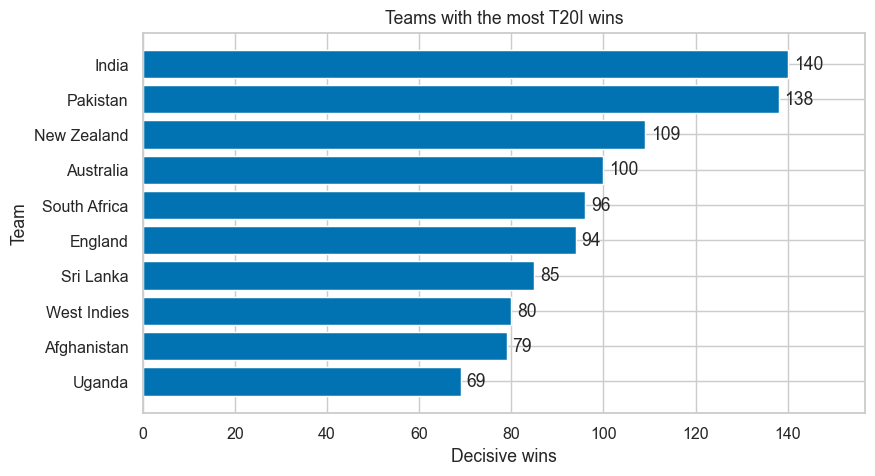

**India** leads with **140 wins**, 2 more than Pakistan. Teams played different numbers of matches, so the totals include differences in exposure.

In [13]:
BLUE, ORANGE, GREEN, _, PURPLE = sns.color_palette("colorblind")[:5]
team_wins = matches.loc[matches.outcome.eq("Decisive"), "match_winner"].value_counts()
top_winners = team_wins.head(10).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.7))
bars = ax.barh(top_winners.index, top_winners.values, color=BLUE)
ax.bar_label(bars, padding=4)
ax.set(xlabel="Decisive wins", ylabel="Team", title="Teams with the most T20I wins")
ax.set_xlim(0, 1.12 * top_winners.max())
save_plot(fig, "01_bar_team_wins")
note(f"**{team_wins.index[0]}** leads with **{team_wins.iloc[0]} wins**, {team_wins.iloc[0] - team_wins.iloc[1]} "
     f"more than {team_wins.index[1]}. Teams played different numbers of matches, so the totals include differences in exposure.")

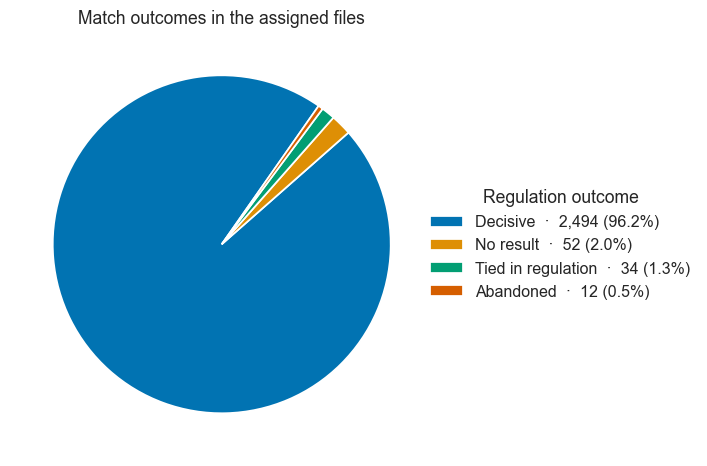

**2,494 of 2,592 matches (96.2%)** had a decisive regulation winner. 34 were tied at the end of regulation, including any subsequent one-over tiebreakers.

In [14]:
outcome_counts = matches.outcome.value_counts()
fig, ax = plt.subplots(figsize=(8.5, 4.6))
wedges, _ = ax.pie(outcome_counts, startangle=55, colors=sns.color_palette("colorblind", len(outcome_counts)),
                   wedgeprops={"edgecolor": "white", "linewidth": 1.2})
ax.legend(wedges, [f"{name}  ·  {count:,} ({count/len(matches):.1%})" for name, count in outcome_counts.items()],
          loc="center left", bbox_to_anchor=(0.96, 0.5), title="Regulation outcome", frameon=False)
ax.set_title("Match outcomes in the assigned files")
save_plot(fig, "02_pie_match_outcomes")
note(f"**{outcome_counts['Decisive']:,} of {len(matches):,} matches ({outcome_counts['Decisive']/len(matches):.1%})** "
     f"had a decisive regulation winner. {outcome_counts.get('Tied in regulation', 0)} were tied at the end of regulation, "
     "including any subsequent one-over tiebreakers.")

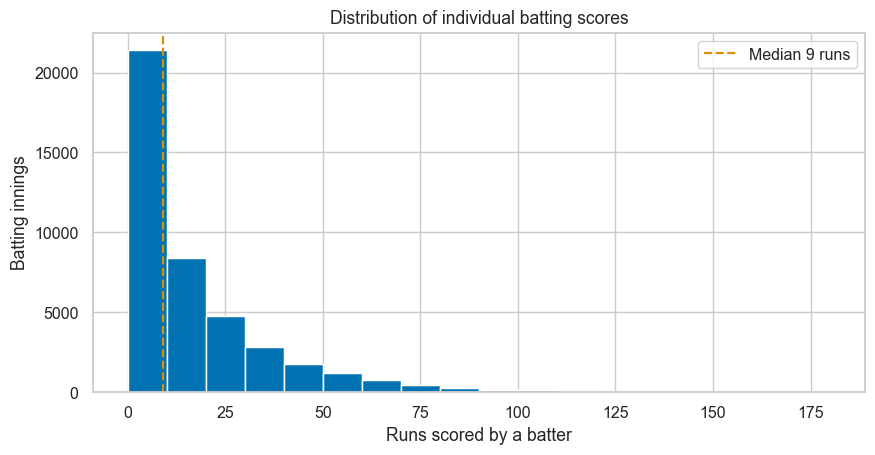

**71.2%** of innings scored under 20. Only 147 of 41,872 batting innings reached 100 runs. The long right tail raises the mean above the median.

In [15]:
batter_scores = played.runs.astype(float)
hist_edges = np.arange(0, 10 * math.ceil(batter_scores.max() / 10) + 1, 10)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.hist(batter_scores, bins=hist_edges, color=BLUE, edgecolor="white")
ax.axvline(batter_scores.median(), color=ORANGE, linestyle="--", label=f"Median {batter_scores.median():.0f} runs")
ax.set(xlabel="Runs scored by a batter", ylabel="Batting innings", title="Distribution of individual batting scores")
ax.legend()
save_plot(fig, "03_histogram_batter_runs")
note(f"**{batter_scores.lt(20).mean():.1%}** of innings scored under 20. Only {int(batter_scores.ge(100).sum())} "
     f"of {len(batter_scores):,} batting innings reached 100 runs. The long right tail raises the mean above the median.")

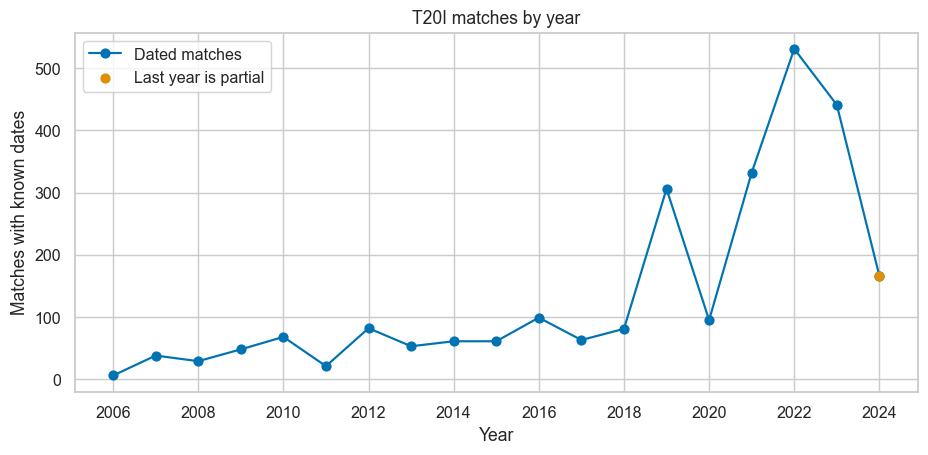

The highest recorded year is **2022 with 531 matches**. The 2024 count is 166 because the dated records end on 07 May 2024.

In [16]:
annual = matches.match_date.dropna().dt.year.value_counts().sort_index()
annual = annual.reindex(range(annual.index.min(), annual.index.max() + 1), fill_value=0)
save_table(annual.rename_axis("year").reset_index(name="dated_matches"), "annual_dated_matches")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(annual.index, annual.values, marker="o", color=BLUE, label="Dated matches")
ax.scatter(annual.index[-1], annual.iloc[-1], color=ORANGE, zorder=4, label="Last year is partial")
ax.set(xlabel="Year", ylabel="Matches with known dates", title="T20I matches by year")
ax.set_xticks(annual.index[::2])
ax.legend()
save_plot(fig, "04_line_annual_matches")
note(f"The highest recorded year is **{annual.idxmax()} with {annual.max()} matches**. The "
     f"{annual.index[-1]} count is {annual.iloc[-1]} because the dated records end on {dated.max():%d %B %Y}.")

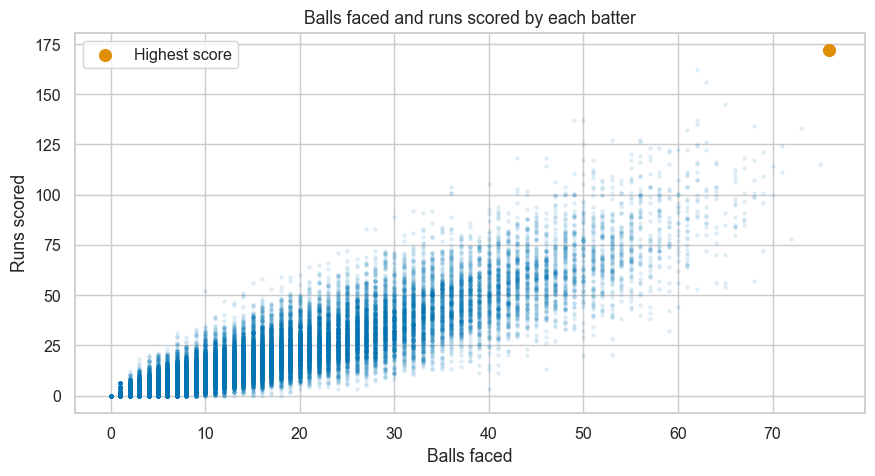

The Pearson correlation is **0.906**. The highest point is Aaron Finch's 172 from 76 balls. Scores still vary at the same number of balls faced.

In [17]:
fig, ax = plt.subplots(figsize=(8.5, 4.7))
ax.scatter(played.balls, played.runs, s=9, alpha=0.13, color=BLUE, linewidth=0)
ax.scatter(best_batter.balls, best_batter.runs, s=64, color=ORANGE, label="Highest score")
ax.set(xlabel="Balls faced", ylabel="Runs scored", title="Balls faced and runs scored by each batter")
ax.legend()
save_plot(fig, "05_scatter_balls_and_runs")
bat_correlation = played[["balls", "runs"]].astype(float).corr().loc["balls", "runs"]
note(f"The Pearson correlation is **{bat_correlation:.3f}**. The highest point is {best_batter.player_label}'s "
     f"{best_batter.runs} from {best_batter.balls} balls. Scores still vary at the same number of balls faced.")

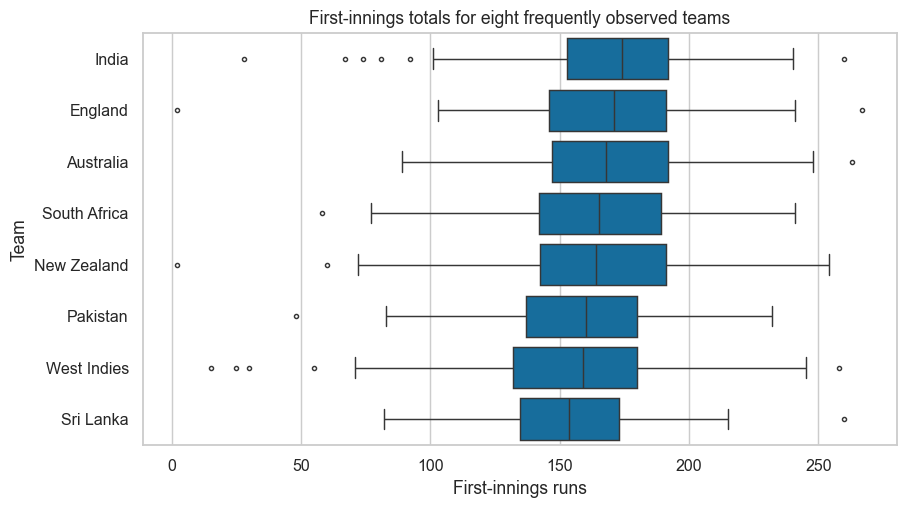

Of these teams, **India** has the highest median at **174** runs. Sri Lanka's median is 153.5. The distributions also reflect venue, opposition and match-length differences.

In [18]:
first_totals = innings.loc[innings.innings.eq(1)].dropna(subset=["total_runs"])
box_teams = first_totals.batting_team.value_counts().head(8).index
box_data = first_totals.loc[first_totals.batting_team.isin(box_teams)]
medians_by_team = box_data.groupby("batting_team").total_runs.median().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.8, 5))
sns.boxplot(data=box_data, x="total_runs", y="batting_team", order=medians_by_team.index,
            color=BLUE, fliersize=2.8, ax=ax)
ax.set(xlabel="First-innings runs", ylabel="Team", title="First-innings totals for eight frequently observed teams")
save_plot(fig, "06_box_first_innings_by_team")
note(f"Of these teams, **{medians_by_team.index[0]}** has the highest median at **{medians_by_team.iloc[0]:g}** runs. "
     f"{medians_by_team.index[-1]}'s median is {medians_by_team.iloc[-1]:g}. The distributions also reflect venue, "
     "opposition and match-length differences.")

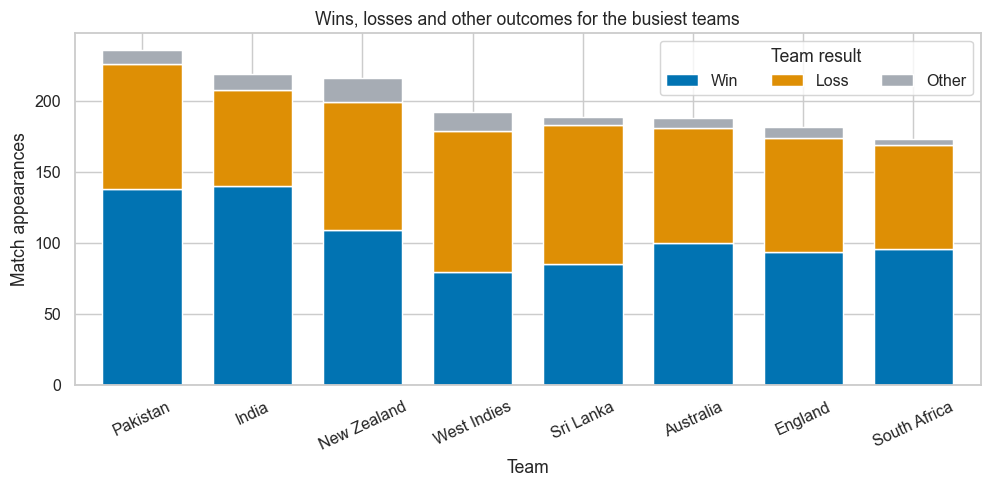

Among the eight busiest teams, **India** has the highest decisive win rate (67.3%). New Zealand has the most appearances with other outcomes (17).

In [19]:
appearances = pd.concat([
    matches[["team1_name", "outcome", "match_winner"]].rename(columns={"team1_name": "team"}),
    matches[["team2_name", "outcome", "match_winner"]].rename(columns={"team2_name": "team"}),
], ignore_index=True)
appearances["team_result"] = np.select(
    [appearances.outcome.ne("Decisive"), appearances.team.eq(appearances.match_winner)],
    ["Other", "Win"], default="Loss",
)
busiest_teams = appearances.team.value_counts().head(8).index
result_by_team = pd.crosstab(appearances.team, appearances.team_result).reindex(
    index=busiest_teams, columns=["Win", "Loss", "Other"], fill_value=0
)
fig, ax = plt.subplots(figsize=(9.6, 4.8))
result_by_team.plot.bar(stacked=True, ax=ax, color=[BLUE, ORANGE, "#a6acb4"], width=0.72)
ax.set(xlabel="Team", ylabel="Match appearances", title="Wins, losses and other outcomes for the busiest teams")
ax.tick_params(axis="x", labelrotation=25)
ax.legend(title="Team result", ncol=3)
save_plot(fig, "07_stacked_bar_team_outcomes")
decisive_win_rate = result_by_team.Win / (result_by_team.Win + result_by_team.Loss)
note(f"Among the eight busiest teams, **{decisive_win_rate.idxmax()}** has the highest decisive win rate "
     f"({decisive_win_rate.max():.1%}). {result_by_team.Other.idxmax()} has the most appearances "
     f"with other outcomes ({result_by_team.Other.max()}).")

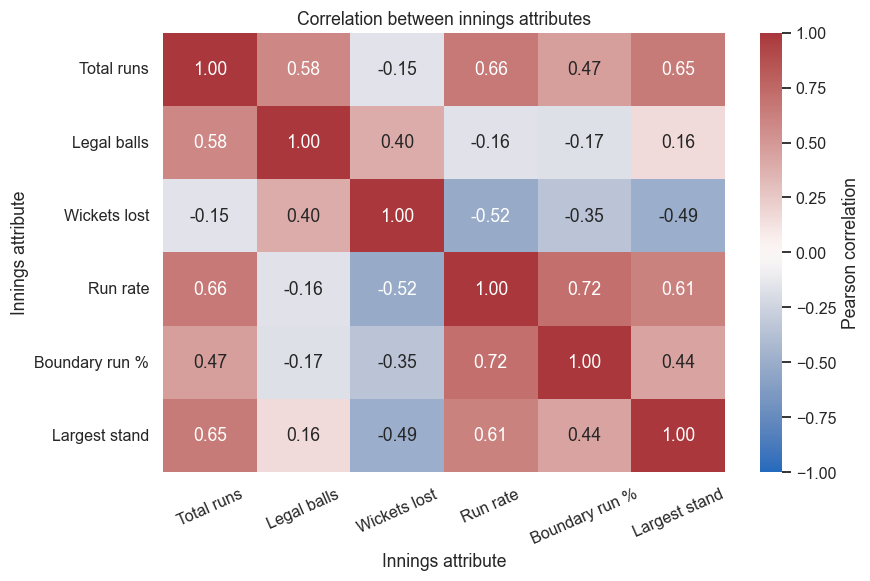

Total runs and run rate correlate at **0.66** across both innings. Total runs and the largest stand correlate at 0.65. These measures share some scoring information.

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 5.7))
sns.heatmap(innings_corr.rename(index=columns_for_corr, columns=columns_for_corr), vmin=-1, vmax=1, center=0,
            cmap="vlag", annot=True, fmt=".2f", cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set(xlabel="Innings attribute", ylabel="Innings attribute", title="Correlation between innings attributes")
ax.tick_params(axis="x", labelrotation=24)
ax.tick_params(axis="y", labelrotation=0)
save_plot(fig, "08_heatmap_innings_correlations")
note(f"Total runs and run rate correlate at **{innings_corr.loc['total_runs', 'run_rate']:.2f}** across both "
     f"innings. Total runs and the largest stand correlate at {innings_corr.loc['total_runs', 'largest_stand']:.2f}. "
     "These measures share some scoring information.")

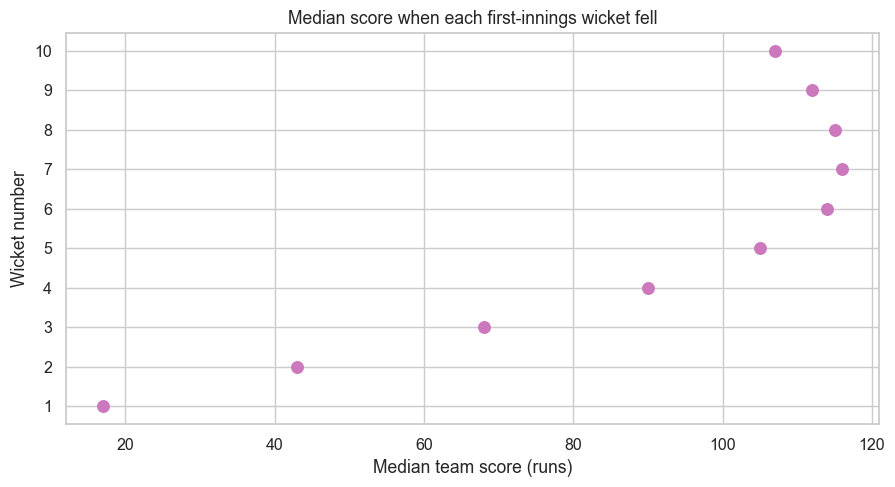

The median score at wicket 1 is **17** from 2,569 innings. Wicket 10 has a median of 107 across 408 innings. Each dot uses the innings that reached that wicket.

In [21]:
first_dismissals = fall.loc[fall.confirmed_dismissal & fall.innings.eq(1)].dropna(subset=["score_at_event"])
first_dismissals = first_dismissals.drop_duplicates(innings_key + ["wicket"], keep=False)
wicket_scores = first_dismissals.groupby("wicket").score_at_event.agg(["median", "size"])
fig, ax = plt.subplots(figsize=(8.7, 4.8))
ax.scatter(wicket_scores["median"], wicket_scores.index, s=62, color=PURPLE)
ax.set_yticks(wicket_scores.index)
ax.set(xlabel="Median team score (runs)", ylabel="Wicket number", title="Median score when each first-innings wicket fell")
save_plot(fig, "09_dot_fall_of_wicket")
note(f"The median score at wicket 1 is **{wicket_scores.loc[1, 'median']:g}** from "
     f"{wicket_scores.loc[1, 'size']:,} innings. Wicket 10 has a median of {wicket_scores.loc[10, 'median']:g} "
     f"across {wicket_scores.loc[10, 'size']:,} innings. Each dot uses the innings that reached that wicket.")

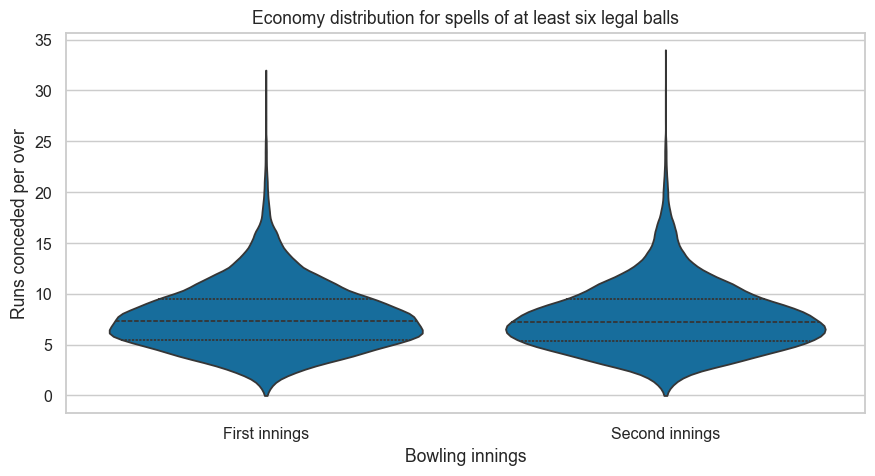

Median economy is **7.33** in first innings and **7.20** in second innings. The plot uses 30,346 bowling spells and shows the median and quartiles inside each violin.

In [22]:
violin_data = bowling.loc[bowling.legal_balls.ge(6)].dropna(subset=["conceded"]).copy()
violin_data["economy_calc"] = (6 * violin_data.conceded / violin_data.legal_balls).astype(float)
violin_data["bowling_in"] = violin_data.innings.map({1: "First innings", 2: "Second innings"})
fig, ax = plt.subplots(figsize=(8.5, 4.7))
sns.violinplot(data=violin_data, x="bowling_in", y="economy_calc", inner="quart", cut=0, color=BLUE, ax=ax)
ax.set(xlabel="Bowling innings", ylabel="Runs conceded per over", title="Economy distribution for spells of at least six legal balls")
save_plot(fig, "10_violin_bowling_economy")
economy_medians = violin_data.groupby("bowling_in").economy_calc.median()
note(f"Median economy is **{economy_medians['First innings']:.2f}** in first innings and "
     f"**{economy_medians['Second innings']:.2f}** in second innings. The plot uses {len(violin_data):,} "
     "bowling spells and shows the median and quartiles inside each violin.")

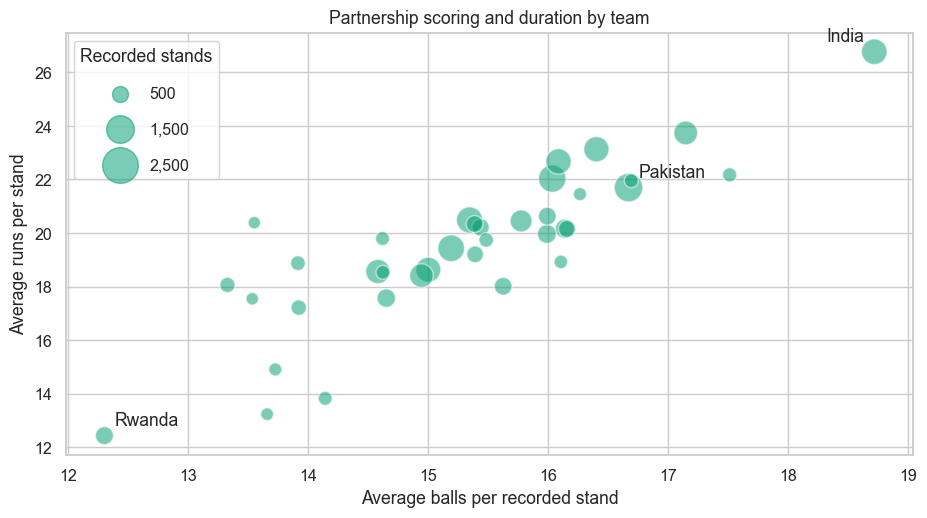

Among teams with at least 300 recorded stands, **India** has the highest average at 26.8 runs. The largest bubble is Pakistan with 1,597 stands.

In [23]:
stand_summary = partnerships.dropna(subset=["partnership_balls", "partnership_runs"]).groupby("batting_team").agg(
    mean_balls=("partnership_balls", "mean"), mean_runs=("partnership_runs", "mean"), n_stands=("for_wicket", "size")
).query("n_stands >= 300").sort_values("n_stands", ascending=False)
size_factor = 0.24
fig, ax = plt.subplots(figsize=(9, 5.1))
ax.scatter(stand_summary.mean_balls, stand_summary.mean_runs, s=size_factor * stand_summary.n_stands,
           alpha=0.52, color=GREEN, edgecolor="white")
label_teams = dict.fromkeys([stand_summary.index[0], stand_summary.mean_runs.idxmax(), stand_summary.mean_runs.idxmin()])
for name in label_teams:
    row = stand_summary.loc[name]
    near_right = row.mean_balls > stand_summary.mean_balls.max() - 1
    ax.annotate(name, (row.mean_balls, row.mean_runs), xytext=(-7 if near_right else 7, 7),
                ha="right" if near_right else "left", textcoords="offset points")
for sample_size in [500, 1500, 2500]:
    ax.scatter([], [], s=sample_size * size_factor, color=GREEN, alpha=0.52, label=f"{sample_size:,}")
ax.legend(title="Recorded stands", loc="upper left", frameon=True, labelspacing=1.3)
ax.set(xlabel="Average balls per recorded stand", ylabel="Average runs per stand",
       title="Partnership scoring and duration by team")
save_plot(fig, "11_bubble_partnership_profiles")
note(f"Among teams with at least 300 recorded stands, **{stand_summary.mean_runs.idxmax()}** has the highest "
     f"average at {stand_summary.mean_runs.max():.1f} runs. The largest bubble is {stand_summary.index[0]} "
     f"with {stand_summary.n_stands.iloc[0]:,} stands.")

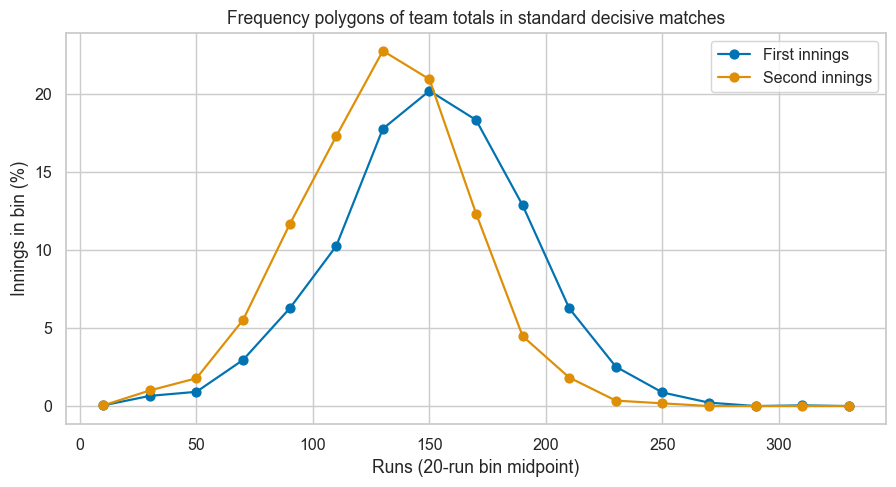

The most common first-innings band is **140–159** runs (20.2%). The second-innings peak is **120–139** (22.7%). A successful chase ends as soon as the target is reached.

In [24]:
score_edges = np.arange(0, math.ceil(standard_innings.total_runs.max() / 20) * 20 + 21, 20)
midpoints = (score_edges[:-1] + score_edges[1:]) / 2
fig, ax = plt.subplots(figsize=(8.7, 4.8))
modal_bands = {}
for number, label, color in [(1, "First innings", BLUE), (2, "Second innings", ORANGE)]:
    scores = standard_innings.loc[standard_innings.innings.eq(number), "total_runs"].astype(float)
    counts, _ = np.histogram(scores, bins=score_edges)
    peak = counts.argmax()
    modal_bands[label] = (f"{score_edges[peak]}–{score_edges[peak + 1] - 1}", counts[peak] / len(scores))
    ax.plot(midpoints, 100 * counts / len(scores), marker="o", label=label, color=color)
ax.set(xlabel="Runs (20-run bin midpoint)", ylabel="Innings in bin (%)",
       title="Frequency polygons of team totals in standard decisive matches")
ax.legend()
save_plot(fig, "12_frequency_polygon_innings_totals")
note(f"The most common first-innings band is **{modal_bands['First innings'][0]}** runs "
     f"({modal_bands['First innings'][1]:.1%}). The second-innings peak is **{modal_bands['Second innings'][0]}** "
     f"({modal_bands['Second innings'][1]:.1%}). A successful chase ends as soon as the target is reached.")

### Stem-and-leaf, quantile, Q–Q and frequency dot plots

The Lecture 4 stem-and-leaf plot shows each small-sample score as a stem and a final digit. The quantile plot uses the sorted scores and plotting positions `(i − 0.5) / n`, where `i` starts at 1. The Q–Q plot compares the independently sorted scores of the two innings at the same positions. The frequency dot plot stacks one dot for each match at its recorded wicket count.

[Han, Kamber and Pei, *Data Mining: Concepts and Techniques*, 3rd ed., Chapter 2](https://www.sciencedirect.com/book/monograph/9780123814791/data-mining-concepts-and-techniques)

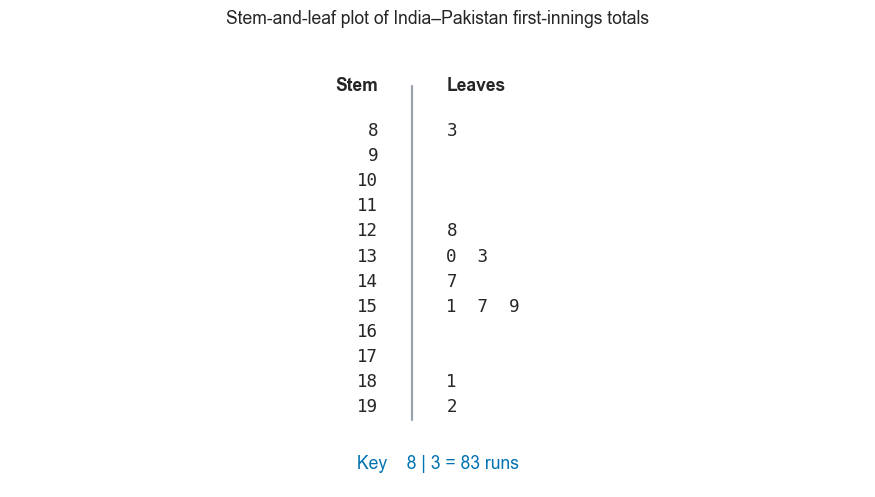

In the **10** standard decisive India–Pakistan matches, first-innings scores ranged from **83 to 192 runs**, with a median of **149**. 5 of the 10 innings reached 150 runs.

In [25]:
india_pakistan = standard.loc[
    (standard.first_batting_team.eq("India") & standard.second_batting_team.eq("Pakistan"))
    | (standard.first_batting_team.eq("Pakistan") & standard.second_batting_team.eq("India")),
    ["match_id", "match_date", "first_batting_team", "first_total_runs"],
].sort_values(["first_total_runs", "match_id"]).copy()
india_pakistan["stem"] = india_pakistan.first_total_runs // 10
india_pakistan["leaf"] = india_pakistan.first_total_runs % 10
stem_leaves = india_pakistan.groupby("stem").leaf.agg(list)
stem_min, stem_max = int(stem_leaves.index.min()), int(stem_leaves.index.max())

fig, ax = plt.subplots(figsize=(8.5, 4.9))
ax.set_axis_off()
ax.set_title("Stem-and-leaf plot of India–Pakistan first-innings totals", pad=12)
ax.text(0.43, 0.89, "Stem", ha="right", weight="bold", transform=ax.transAxes)
ax.text(0.51, 0.89, "Leaves", weight="bold", transform=ax.transAxes)
ax.plot([0.47, 0.47], [0.15, 0.9], color="#9aa2ac", transform=ax.transAxes)
for stem, y in zip(range(stem_min, stem_max + 1), np.linspace(0.80, 0.18, stem_max - stem_min + 1)):
    ax.text(0.43, y, f"{stem:d}", ha="right", va="center", fontfamily="monospace", transform=ax.transAxes)
    leaves = "  ".join(map(str, stem_leaves.get(stem, [])))
    ax.text(0.51, y, leaves, va="center", fontfamily="monospace", transform=ax.transAxes)
example = india_pakistan.iloc[0]
ax.text(0.5, 0.04, f"Key    {example.stem} | {example.leaf} = {example.first_total_runs} runs",
        ha="center", color=BLUE, transform=ax.transAxes)
save_plot(fig, "23_stem_leaf_india_pakistan")
save_table(india_pakistan, "descriptive_stem_leaf_totals")
subtotals = india_pakistan.first_total_runs
above_150 = int(subtotals.ge(150).sum())
note(f"In the **{len(subtotals)}** standard decisive India–Pakistan matches, first-innings scores ranged "
     f"from **{subtotals.min()} to {subtotals.max()} runs**, with a median of **{subtotals.median():g}**. "
     f"{above_150} of the {len(subtotals)} innings reached 150 runs.")

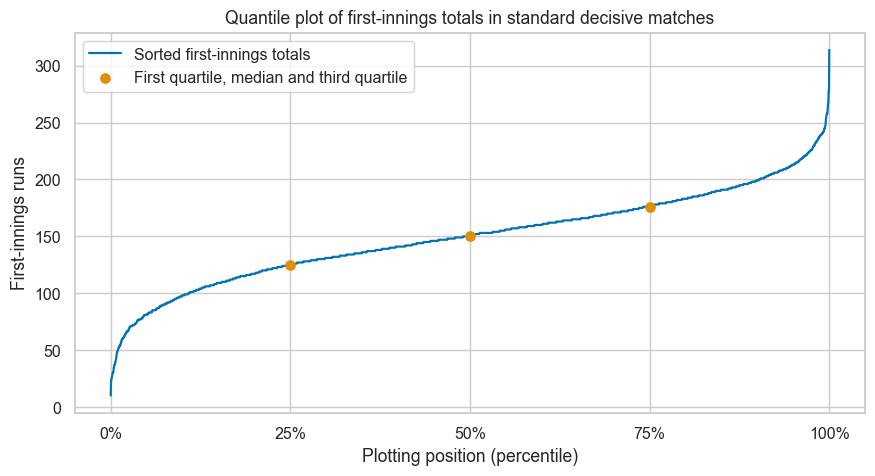

The median of **2,305** first-innings totals was **150 runs**. The middle half ran from **125 to 176**, and the 90th percentile was 199.

In [26]:
first_scores = np.sort(standard_innings.loc[standard_innings.innings.eq(1), "total_runs"].to_numpy(dtype=int))
second_scores = np.sort(standard_innings.loc[standard_innings.innings.eq(2), "total_runs"].to_numpy(dtype=int))
assert len(first_scores) == len(second_scores) == len(standard)
fractions = (np.arange(len(first_scores)) + 0.5) / len(first_scores)
percentiles = np.array([10, 25, 50, 75, 90])
quantile_comparison = pd.DataFrame({
    "percentile": percentiles,
    "first_innings_runs": np.interp(percentiles / 100, fractions, first_scores),
    "second_innings_runs": np.interp(percentiles / 100, fractions, second_scores),
})
quantile_comparison["second_minus_first_runs"] = (
    quantile_comparison.second_innings_runs - quantile_comparison.first_innings_runs
)
save_table(quantile_comparison, "descriptive_quantile_comparison")
marked_quantiles = quantile_comparison.loc[quantile_comparison.percentile.isin([25, 50, 75])]
quantile_runs = quantile_comparison.set_index("percentile")

fig, ax = plt.subplots(figsize=(8.5, 4.7))
ax.plot(fractions, first_scores, color=BLUE, label="Sorted first-innings totals")
ax.scatter(marked_quantiles.percentile / 100, marked_quantiles.first_innings_runs,
           color=ORANGE, s=40, label="First quartile, median and third quartile", zorder=3)
ax.set(xlabel="Plotting position (percentile)", ylabel="First-innings runs",
       title="Quantile plot of first-innings totals in standard decisive matches")
ax.set_xticks([0, .25, .50, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.legend(loc="upper left")
save_plot(fig, "24_quantile_first_innings_totals")
note(f"The median of **{len(first_scores):,}** first-innings totals was "
     f"**{quantile_runs.at[50, 'first_innings_runs']:g} runs**. The middle half ran from "
     f"**{quantile_runs.at[25, 'first_innings_runs']:g} to {quantile_runs.at[75, 'first_innings_runs']:g}**, "
     f"and the 90th percentile was {quantile_runs.at[90, 'first_innings_runs']:g}.")

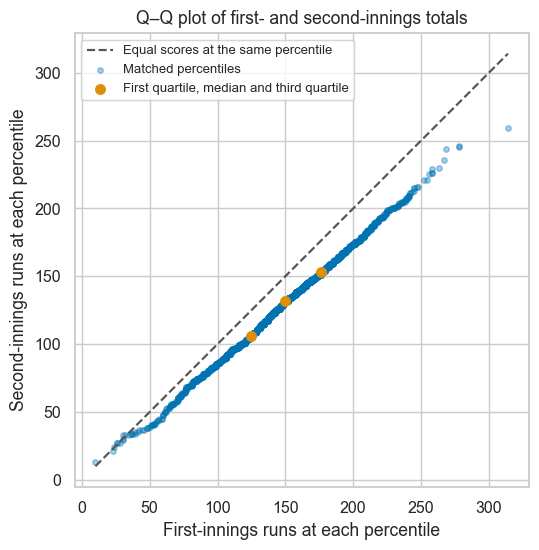

The first- and second-innings medians were **150** and **132 runs**. At the 90th percentile the totals were **199** and **173**. Each point compares the same percentile of the two distributions. A successful chase ends as soon as it reaches its target.

In [27]:
fig, ax = plt.subplots(figsize=(6.7, 5.4))
lower_score = min(first_scores[0], second_scores[0])
upper_score = max(first_scores[-1], second_scores[-1])
ax.plot([lower_score, upper_score], [lower_score, upper_score],
        linestyle="--", color="#555555", label="Equal scores at the same percentile")
ax.scatter(first_scores, second_scores, s=14, alpha=0.35, color=BLUE, label="Matched percentiles")
ax.scatter(marked_quantiles.first_innings_runs, marked_quantiles.second_innings_runs,
           color=ORANGE, s=42, zorder=3, label="First quartile, median and third quartile")
ax.set(xlabel="First-innings runs at each percentile", ylabel="Second-innings runs at each percentile",
       title="Q–Q plot of first- and second-innings totals")
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper left", fontsize=9)
save_plot(fig, "25_qq_innings_totals")
note(f"The first- and second-innings medians were **{quantile_runs.at[50, 'first_innings_runs']:g}** and "
     f"**{quantile_runs.at[50, 'second_innings_runs']:g} runs**. At the 90th percentile the totals were "
     f"**{quantile_runs.at[90, 'first_innings_runs']:g}** and **{quantile_runs.at[90, 'second_innings_runs']:g}**. "
     "Each point compares the same percentile of the two distributions. A successful chase ends as soon as it reaches its target.")

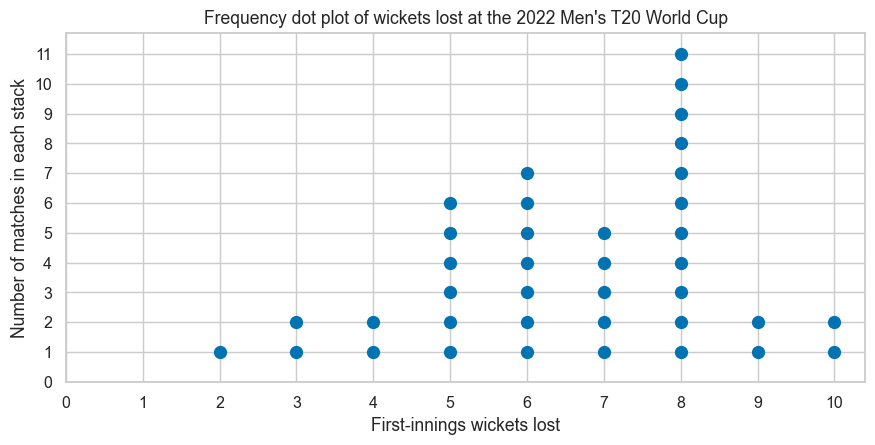

Each dot represents one of **38** standard decisive matches. The tallest stack is at **8 wickets**, with **11 matches** per peak. First-innings sides lost eight or more wickets in **15 matches**.

In [28]:
world_cup_series = "ICC Men's T20 World Cup in Australia - 2022 (2022/23)"
world_cup_matches = matches.loc[matches.series_name.eq(world_cup_series), "match_id"]
cup_wickets = standard_innings.loc[
    standard_innings.innings.eq(1) & standard_innings.match_id.isin(world_cup_matches), "wickets_lost"
]
wicket_frequency = cup_wickets.value_counts().reindex(range(11), fill_value=0)
save_table(wicket_frequency.rename_axis("wickets_lost").reset_index(name="matches"),
           "descriptive_wickets_frequency")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for wickets, count in wicket_frequency.items():
    ax.scatter([wickets] * count, range(1, count + 1), s=65, color=BLUE)
ax.set(xlabel="First-innings wickets lost", ylabel="Number of matches in each stack",
       title="Frequency dot plot of wickets lost at the 2022 Men's T20 World Cup")
ax.set_xticks(range(11))
ax.set_yticks(range(0, int(wicket_frequency.max()) + 1))
ax.set_ylim(0, wicket_frequency.max() + 0.7)
save_plot(fig, "26_frequency_dot_wickets_lost")
mode_wickets = " and ".join(str(wickets) for wickets in wicket_frequency.index[wicket_frequency.eq(wicket_frequency.max())])
note(f"Each dot represents one of **{len(cup_wickets)}** standard decisive matches. "
     f"The tallest stack is at **{mode_wickets} wickets**, with **{wicket_frequency.max()} matches** per peak. "
     f"First-innings sides lost eight or more wickets in **{int(cup_wickets.ge(8).sum())} matches**.")

## 4. Transactions and association rules

Each transaction represents one batting team in one standard, decisive match. We use both innings so every match contributes one winning and one losing team. The two innings from a match are related, so these patterns describe the dataset. They do not estimate a causal effect.

We split scoring rate, wickets lost and boundary share at their medians. Values equal to a median go in the lower bin. Boundary share means the percentage of innings runs scored in recorded fours and sixes. Team and match IDs identify records. They do not become items. We leave out total runs because it overlaps strongly with scoring rate, especially in first innings.

In [29]:
transaction_source = standard_innings.dropna(
    subset=["toss_won", "run_rate", "wickets_lost", "boundary_share"]
).copy()
# Keep both innings or neither. This preserves one win and one loss per match.
transaction_source = transaction_source.groupby("match_id").filter(lambda rows: len(rows) == 2)
bin_features = {
    "run_rate": ("pace", "low", "high"),
    "wickets_lost": ("wickets_lost", "few", "many"),
    "boundary_share": ("boundary_share", "low", "high"),
}
bin_edges = transaction_source[list(bin_features)].median()
item_columns = pd.DataFrame(index=transaction_source.index)
item_columns["batting_order"] = transaction_source["innings"].map({1: "order=first", 2: "order=second"})
item_columns["toss"] = transaction_source["toss_won"].astype(int).map({0: "toss=lost", 1: "toss=won"})
item_columns["outcome"] = transaction_source["team_won"].astype(int).map({0: "outcome=lost", 1: "outcome=won"})
for name, (prefix, lower, upper) in bin_features.items():
    item_columns[name] = np.where(
        transaction_source[name] <= bin_edges[name], f"{prefix}={lower}", f"{prefix}={upper}"
    )
assert item_columns.notna().all().all()
transaction_table = pd.concat(
    [transaction_source[["match_id", "innings", "batting_team"]], item_columns], axis=1
).sample(frac=1, random_state=SEED).reset_index(drop=True)
transaction_table.insert(0, "transaction_id", np.arange(len(transaction_table)))
transactions = [frozenset(row) for row in transaction_table[item_columns.columns].itertuples(index=False, name=None)]
transaction_table["items"] = [" | ".join(sorted(items)) for items in transactions]
save_processed(transaction_table, "transactions")
display(transaction_source[list(bin_features)].head(5).join(item_columns[list(bin_features)].head(5), rsuffix="_item"))
display(bin_edges.rename("median_cutoff").to_frame())
item_counts = Counter(item for row in transactions for item in row)
item_support = pd.DataFrame(
    [{"item": item, "support_count": count, "support_pct": 100 * count / len(transactions)}
     for item, count in sorted(item_counts.items())]
)
save_table(item_support, "transaction_item_support")
display(transaction_table[["transaction_id", "match_id", "innings", "items"]].head(), item_support)
note(f"The database contains **{len(transactions):,} transactions** from **"
     f"{transaction_table.match_id.nunique():,} matches** and {len(item_counts)} distinct items.")

,run_rate,wickets_lost,boundary_share,run_rate_item,wickets_lost_item,boundary_share_item
0,8.9500,8,52.5140,pace=high,wickets_lost=many,boundary_share=high
1,5.4483,10,50.6329,pace=low,wickets_lost=many,boundary_share=high
2,10.7000,5,61.6822,pace=high,wickets_lost=few,boundary_share=high
3,8.5000,10,57.6471,pace=high,wickets_lost=many,boundary_share=high
4,6.8205,10,55.6391,pace=low,wickets_lost=many,boundary_share=high


,median_cutoff
run_rate,7.4503
wickets_lost,7.0000
boundary_share,50.4854


,transaction_id,match_id,innings,items
0,0,1191008,1,boundary_share=low | order=first | outcome=los...
1,1,1426450,2,boundary_share=low | order=second | outcome=wo...
2,2,361654,2,boundary_share=low | order=second | outcome=lo...
3,3,1272377,1,boundary_share=low | order=first | outcome=won...
4,4,1257946,2,boundary_share=high | order=second | outcome=l...


,item,support_count,support_pct
0,boundary_share=high,2302,49.9566
1,boundary_share=low,2306,50.0434
2,order=first,2304,50.0000
3,order=second,2304,50.0000
4,outcome=lost,2304,50.0000
5,outcome=won,2304,50.0000
6,pace=high,2304,50.0000
7,pace=low,2304,50.0000
8,toss=lost,2304,50.0000
9,toss=won,2304,50.0000


The database contains **4,608 transactions** from **2,304 matches** and 12 distinct items.

### Dynamic Itemset Counting

DIC counts the active candidates in one block, updates their states and starts new candidates when all immediate subsets are suspected or confirmed frequent. A candidate starts as a dashed circle (DC) and becomes a dashed square (DS) once its partial count passes the threshold. It only becomes a solid square (SS) or solid circle (SC) after it has seen the full database since its own start.

The scan wraps around to block 0 as needed. Itemsets enter the scan mid-cycle, so several itemset sizes can be counted at the same time. Each transaction and candidate is encoded as a bit mask. The candidate is present when all of its bits are set in the transaction.

We round up the product of the support fraction and the transaction count. Fraction arithmetic gives an exact threshold even when the product is a whole number.

[Brin et al., SIGMOD 1997](https://sigmodrecord.org/publications/sigmodRecord/9706/pdfs/253262.253325.pdf)

In [30]:
def itemset_text(items):
    return " + ".join(sorted(items))


def minimum_count(min_support, n_transactions):
    support = Fraction(str(min_support))
    if not 0 < support <= 1:
        raise ValueError("Minimum support must be in (0, 1].")
    return math.ceil(support * n_transactions)


def encode_transactions(rows, block_size):
    if not rows or block_size < 1:
        raise ValueError("DIC requires transactions and a positive block size.")
    bit_by_item = {item: 1 << i for i, item in enumerate(sorted(set().union(*rows)))}
    # Every physical row has a unique ID, even when a benchmark repeats its item values.
    records = [(i, sum(bit_by_item[item] for item in row)) for i, row in enumerate(rows)]
    blocks = [records[start:start + block_size] for start in range(0, len(records), block_size)]
    return bit_by_item, blocks


def count_masks(records, candidate_masks):
    counts = [0] * len(candidate_masks)
    for _, transaction_mask in records:
        for index, candidate_mask in enumerate(candidate_masks):
            if transaction_mask & candidate_mask == candidate_mask:
                counts[index] += 1
    return counts


@dataclass
class Candidate:
    state: str = "DC"
    support: int = 0
    seen: int = 0


def dic_scan(bit_by_item, block_lengths, count_block, min_support, trace=False):
    """Run DIC checkpoints with a local or Spark block counter."""
    n_transactions = sum(block_lengths)
    threshold = minimum_count(min_support, n_transactions)
    candidates = {frozenset([name]): Candidate() for name in bit_by_item}
    events = []
    rows_scanned = checkpoint = 0

    def record(itemset, state, event):
        if trace:
            events.append({
                "checkpoint": checkpoint, "itemset": itemset_text(itemset),
                "event": event, "state": state.state,
                "support_so_far": state.support, "transactions_seen": state.seen,
            })

    for itemset, state in candidates.items():
        record(itemset, state, "activate singleton")

    while active := [itemset for itemset, state in candidates.items() if state.state in {"DC", "DS"}]:
        block_index = checkpoint % len(block_lengths)
        block_length = block_lengths[block_index]
        checkpoint += 1
        rows_scanned += block_length
        masks = [sum(bit_by_item[item] for item in itemset) for itemset in active]
        promoted = []
        for itemset, hits in zip(active, count_block(block_index, masks), strict=True):
            state = candidates[itemset]
            state.support += hits
            state.seen += block_length
            record(itemset, state, f"block {block_index + 1}: +{hits}")
            if state.state == "DC" and state.support >= threshold:
                state.state = "DS"
                promoted.append(itemset)
                record(itemset, state, "threshold reached")
            assert state.seen <= n_transactions
            if state.seen == n_transactions:
                state.state = "SS" if state.state == "DS" else "SC"
                record(itemset, state, "completed its own cycle")

        # Extend each newly frequent parent. Its last required parent has just
        # become frequent at this checkpoint, including promotions in this block.
        frequent_items = [name for name in bit_by_item if candidates[frozenset([name])].state in {"DS", "SS"}]
        for parent in promoted:
            for name in frequent_items:
                if name in parent:
                    continue
                child = parent | {name}
                if child in candidates:
                    continue
                if all((subset := child - {item}) in candidates and candidates[subset].state in {"DS", "SS"}
                       for item in child):
                    candidates[child] = Candidate()
                    record(child, candidates[child], "activate after all parents reach support")

    frequent = {items: state.support for items, state in candidates.items() if state.state == "SS"}
    statistics = {
        "transactions": n_transactions, "minimum_count": threshold, "checkpoints": checkpoint,
        "rows_scanned": rows_scanned, "equivalent_passes": rows_scanned / n_transactions,
        "candidates_counted": len(candidates),
    }
    return frequent, statistics, events


def dic_python(encoded, min_support, trace=False):
    bit_by_item, blocks = encoded
    return dic_scan(
        bit_by_item, [len(block) for block in blocks],
        lambda index, masks: count_masks(blocks[index], masks), min_support, trace,
    )


def exhaustive_counts(rows, min_support):
    """Independent reference for small examples. Test every nonempty subset."""
    items = sorted(set().union(*rows))
    threshold = minimum_count(min_support, len(rows))
    result = {}
    for length in range(1, len(items) + 1):
        for subset in combinations(items, length):
            pattern = frozenset(subset)
            count = sum(pattern.issubset(row) for row in rows)
            if count >= threshold:
                result[pattern] = count
    return result


def apriori_counts(rows, min_support):
    """Independent level-by-level reference. Count combinations within each row."""
    threshold = minimum_count(min_support, len(rows))
    singles = Counter(item for row in rows for item in row)
    level = {(item,) for item, count in singles.items() if count >= threshold}
    result = {frozenset(pair): singles[pair[0]] for pair in level}
    length = 2
    ordered_rows = [tuple(sorted(row)) for row in rows]
    items = sorted(key[0] for key in level)
    while level:
        allowed = {
            combo for combo in combinations(items, length)
            if all(parent in level for parent in combinations(combo, length - 1))
        }
        if not allowed:
            break
        counts = Counter(
            combo for row in ordered_rows for combo in combinations(row, length) if combo in allowed
        )
        level = {combo for combo, count in counts.items() if count >= threshold}
        result.update({frozenset(combo): counts[combo] for combo in level})
        length += 1
    return result


def pattern_table(patterns, n_transactions):
    rows = [
        {"itemset": itemset_text(items), "length": len(items),
         "support_count": count, "support_pct": 100 * count / n_transactions}
        for items, count in patterns.items()
    ]
    return pd.DataFrame(rows, columns=["itemset", "length", "support_count", "support_pct"]).sort_values(
        ["length", "support_count", "itemset"], ascending=[True, False, True], ignore_index=True
    )


RULE_COLUMNS = [
    "antecedent", "consequent", "support_count", "antecedent_count", "consequent_count",
    "support", "confidence", "lift",
]


def association_rules(unions, counts, n_transactions, min_confidence):
    """List every disjoint, nonempty rule split of each qualifying union."""
    cutoff = Fraction(str(min_confidence))
    rows = []
    for whole, count in unions.items():
        for size in range(1, len(whole)):
            for lhs in combinations(sorted(whole), size):
                lhs = frozenset(lhs)
                rhs = whole - lhs
                lhs_count, rhs_count = counts[lhs], counts[rhs]
                if count * cutoff.denominator >= lhs_count * cutoff.numerator:
                    rows.append({
                        "antecedent": itemset_text(lhs), "consequent": itemset_text(rhs),
                        "support_count": count, "antecedent_count": lhs_count, "consequent_count": rhs_count,
                        "support": count / n_transactions, "confidence": count / lhs_count,
                        "lift": count * n_transactions / (lhs_count * rhs_count),
                    })
    return pd.DataFrame(rows, columns=RULE_COLUMNS).sort_values(
        ["lift", "confidence", "support_count", "antecedent", "consequent"],
        ascending=[False, False, False, True, True], ignore_index=True,
    )


def verify_rule_metrics(rules, source_rows):
    """Recount each side and the union directly in the input transactions."""
    n = len(source_rows)
    for rule in rules.itertuples(index=False):
        lhs, rhs = frozenset(rule.antecedent.split(" + ")), frozenset(rule.consequent.split(" + "))
        assert lhs and rhs and not lhs & rhs
        lhs_count = sum(lhs <= row for row in source_rows)
        rhs_count = sum(rhs <= row for row in source_rows)
        joint = sum(lhs | rhs <= row for row in source_rows)
        assert (joint, lhs_count, rhs_count) == (rule.support_count, rule.antecedent_count, rule.consequent_count)
        assert math.isclose(rule.support, joint / n)
        assert math.isclose(rule.confidence, joint / lhs_count)
        assert math.isclose(rule.lift, (joint / lhs_count) / (rhs_count / n))

In [31]:
toy_rows = list(map(frozenset, ["ABCD", "ABCD", "AB", "AC", "B", "CE", "AB", "BC"]))
toy_frequent, toy_scan, trace = dic_python(encode_transactions(toy_rows, 2), 0.375, trace=True)
assert toy_frequent == exhaustive_counts(toy_rows, 0.375)
assert toy_frequent[frozenset("AB")] == 4
display(pd.DataFrame({"transaction": range(1, 9), "items": list(map(itemset_text, toy_rows))}))
toy_trace = pd.DataFrame(trace)
display(toy_trace[toy_trace.itemset.isin(["A", "D", "A + B", "A + B + C"])], pattern_table(toy_frequent, len(toy_rows)))
note("A starts as a singleton. A + B begins at a later checkpoint, so its final count needs a wraparound. "
     "The trace records every block counted for these four examples. D and A + B + C finish as SC.")

,transaction,items
0,1,A + B + C + D
1,2,A + B + C + D
2,3,A + B
3,4,A + C
4,5,B
5,6,C + E
6,7,A + B
7,8,B + C


,checkpoint,itemset,event,state,support_so_far,transactions_seen
0,0,A,activate singleton,DC,0,0
3,0,D,activate singleton,DC,0,0
5,1,A,block 1: +2,DC,2,2
8,1,D,block 1: +2,DC,2,2
10,2,A,block 2: +2,DC,4,4
11,2,A,threshold reached,DS,4,4
16,2,D,block 2: +0,DC,2,4
18,2,A + B,activate after all parents reach support,DC,0,0
21,3,A,block 3: +0,DS,4,6
24,3,D,block 3: +0,DC,2,6


,itemset,length,support_count,support_pct
0,B,1,6,75.0000
1,A,1,5,62.5000
2,C,1,5,62.5000
3,A + B,2,4,50.0000
4,A + C,2,3,37.5000
5,B + C,2,3,37.5000


A starts as a singleton. A + B begins at a later checkpoint, so its final count needs a wraparound. The trace records every block counted for these four examples. D and A + B + C finish as SC.

In [32]:
MIN_SUPPORT = 0.20
MIN_CONFIDENCE = 0.70
# Four checkpoints per pass keep the trace manageable for both backends.
BLOCK_SIZE = math.ceil(len(transactions) / 4)
start = time.perf_counter()
encoded_transactions = encode_transactions(transactions, BLOCK_SIZE)
dic_encoding_seconds = time.perf_counter() - start
dic_by_support = {}
sensitivity_rows = []
for support in (0.10, MIN_SUPPORT, 0.30):
    start = time.perf_counter()
    frequent, scan, _ = dic_python(encoded_transactions, support)
    elapsed = time.perf_counter() - start
    reference = apriori_counts(transactions, support)
    assert frequent == reference, f"DIC and Apriori differ at support {support}"
    dic_by_support[support] = (frequent, scan, elapsed)
    for confidence in (0.60, MIN_CONFIDENCE, 0.80):
        rules = association_rules(frequent, frequent, len(transactions), confidence)
        sensitivity_rows.append({
            "min_support": support, "min_confidence": confidence, "frequent_itemsets": len(frequent),
            "rules": len(rules), "outcome_rules": int(rules.consequent.isin(["outcome=won", "outcome=lost"]).sum()),
            "dic_seconds": elapsed, **scan,
        })

dic_frequent, dic_scan_stats, dic_seconds = dic_by_support[MIN_SUPPORT]
dic_patterns = pattern_table(dic_frequent, len(transactions))
dic_rules = association_rules(dic_frequent, dic_frequent, len(transactions), MIN_CONFIDENCE)
outcome_rules = dic_rules[dic_rules.consequent.isin(["outcome=won", "outcome=lost"])]
verify_rule_metrics(dic_rules, transactions)
parameter_sensitivity = pd.DataFrame(sensitivity_rows)
save_table(dic_patterns, "dic_frequent_itemsets")
save_table(dic_rules, "dic_association_rules")
save_table(outcome_rules, "dic_outcome_rules")
save_table(parameter_sensitivity, "parameter_sensitivity")
display(pd.DataFrame([dic_scan_stats]), parameter_sensitivity, dic_patterns.head(20), dic_rules.head(15), outcome_rules.head(10))
note(f"DIC and Apriori agreed on every support count at all three cutoffs. At 20% support and 70% "
     f"confidence we found **{len(dic_frequent)} itemsets** and **{len(dic_rules)} rules**. DIC read "
     f"{dic_scan_stats['equivalent_passes']:.2f} database passes through "
     f"{dic_scan_stats['checkpoints']} checkpoints.")
if not outcome_rules.empty:
    best_outcome_rule = outcome_rules.iloc[0]
    note(f"The highest-lift outcome rule was **{best_outcome_rule.antecedent} → {best_outcome_rule.consequent}** "
         f"({best_outcome_rule.support:.1%} support, {best_outcome_rule.confidence:.1%} confidence, "
         f"{best_outcome_rule.lift:.2f} lift). Innings performance is known only after the innings is played.")
else:
    note("No outcome rule met both default cutoffs. The sensitivity table shows how a lower cutoff affects coverage.")

,transactions,minimum_count,checkpoints,rows_scanned,equivalent_passes,candidates_counted
0,4608,922,15,17280,3.7500,168


,min_support,min_confidence,frequent_itemsets,rules,outcome_rules,dic_seconds,transactions,minimum_count,checkpoints,rows_scanned,equivalent_passes,candidates_counted
0,0.1000,0.6000,222,363,75,0.0824,4608,461,17,19584,4.2500,324
1,0.1000,0.7000,222,246,58,0.0824,4608,461,17,19584,4.2500,324
2,0.1000,0.8000,222,103,26,0.0824,4608,461,17,19584,4.2500,324
3,0.2000,0.6000,74,76,17,0.0447,4608,922,15,17280,3.7500,168
4,0.2000,0.7000,74,54,15,0.0447,4608,922,15,17280,3.7500,168
5,0.2000,0.8000,74,21,5,0.0447,4608,922,15,17280,3.7500,168
6,0.3000,0.6000,26,31,7,0.0233,4608,1383,11,12672,2.7500,83
7,0.3000,0.7000,26,19,5,0.0233,4608,1383,11,12672,2.7500,83
8,0.3000,0.8000,26,4,1,0.0233,4608,1383,11,12672,2.7500,83


,itemset,length,support_count,support_pct
0,wickets_lost=few,1,2762,59.9392
1,boundary_share=low,1,2306,50.0434
2,order=first,1,2304,50.0000
3,order=second,1,2304,50.0000
4,outcome=lost,1,2304,50.0000
5,outcome=won,1,2304,50.0000
6,pace=high,1,2304,50.0000
7,pace=low,1,2304,50.0000
8,toss=lost,1,2304,50.0000
9,toss=won,1,2304,50.0000


,antecedent,consequent,support_count,antecedent_count,consequent_count,support,confidence,lift
0,boundary_share=low + wickets_lost=many,outcome=lost + pace=low,953,1173,1639,0.2068,0.8124,2.2842
1,boundary_share=high + wickets_lost=few,outcome=won + pace=high,1156,1629,1639,0.2509,0.7096,1.9951
2,outcome=won + pace=high,boundary_share=high + wickets_lost=few,1156,1639,1629,0.2509,0.7053,1.9951
3,boundary_share=high + outcome=won,pace=high + wickets_lost=few,1156,1467,1830,0.2509,0.7880,1.9842
4,boundary_share=low + outcome=lost + wickets_lo...,pace=low,953,1017,2304,0.2068,0.9371,1.8741
5,outcome=lost + pace=low,wickets_lost=many,1221,1639,1846,0.2650,0.7450,1.8596
6,boundary_share=low + outcome=lost + pace=low,wickets_lost=many,953,1295,1846,0.2068,0.7359,1.8370
7,boundary_share=low + wickets_lost=many,pace=low,1069,1173,2304,0.2320,0.9113,1.8227
8,boundary_share=high + outcome=won + wickets_lo...,pace=high,1156,1296,2304,0.2509,0.8920,1.7840
9,boundary_share=low + pace=low + wickets_lost=many,outcome=lost,953,1069,2304,0.2068,0.8915,1.7830


,antecedent,consequent,support_count,antecedent_count,consequent_count,support,confidence,lift
9,boundary_share=low + pace=low + wickets_lost=many,outcome=lost,953,1069,2304,0.2068,0.8915,1.7830
10,pace=low + wickets_lost=many,outcome=lost,1221,1372,2304,0.2650,0.8899,1.7799
14,boundary_share=low + wickets_lost=many,outcome=lost,1017,1173,2304,0.2207,0.8670,1.7340
15,wickets_lost=many,outcome=lost,1519,1846,2304,0.3296,0.8229,1.6457
16,boundary_share=high + pace=high + wickets_lost...,outcome=won,1156,1413,2304,0.2509,0.8181,1.6362
19,pace=high + wickets_lost=few,outcome=won,1463,1830,2304,0.3175,0.7995,1.5989
20,order=second + wickets_lost=few,outcome=won,1126,1414,2304,0.2444,0.7963,1.5926
21,boundary_share=high + wickets_lost=few,outcome=won,1296,1629,2304,0.2812,0.7956,1.5912
38,boundary_share=low + pace=low,outcome=lost,1295,1785,2304,0.2810,0.7255,1.4510
39,boundary_share=high + pace=high,outcome=won,1292,1783,2304,0.2804,0.7246,1.4492


DIC and Apriori agreed on every support count at all three cutoffs. At 20% support and 70% confidence we found **74 itemsets** and **54 rules**. DIC read 3.75 database passes through 15 checkpoints.

The highest-lift outcome rule was **boundary_share=low + pace=low + wickets_lost=many → outcome=lost** (20.7% support, 89.1% confidence, 1.78 lift). Innings performance is known only after the innings is played.

### CHARM closed frequent itemsets

A closed itemset has no larger itemset with exactly the same support. CHARM starts with a vertical index of transaction IDs (TIDs). At each prefix class it intersects TID sets and skips intersections below minimum support.

If two TID sets are equal, their items merge into the current node and the sibling is removed. If the current TIDs are a proper subset, the sibling's items join the current node and the sibling stays. If the current TIDs are a proper superset, the union moves to a child class and the sibling is removed. With incomparable TID sets, a frequent intersection becomes a child and the sibling stays. We check subsumption within exact TID sets as nodes return from the search.

[Zaki and Hsiao, SDM 2002](https://www.cs.nmsu.edu/~hcao/readings/cs508/CHARM_sdm2002_zaki.pdf) · [Author's CHARM repository](https://github.com/zakimjz/CHARM)

In [33]:
def vertical_index(rows):
    index = defaultdict(set)
    for tid, items in enumerate(rows):
        for item in items:
            index[item].add(tid)
    return {item: frozenset(tids) for item, tids in index.items()}


def charm(rows, min_support, trace=False, order_by_support=True):
    threshold = minimum_count(min_support, len(rows))
    initial = [
        (frozenset([item]), tids) for item, tids in vertical_index(rows).items()
        if len(tids) >= threshold
    ]
    closed_by_tids = {}
    events = []

    def sort_node(node):
        items, tids = node
        return (len(tids) if order_by_support else 0, tuple(sorted(items)))

    def record(depth, current, other, tids, action):
        if trace:
            events.append({
                "depth": depth, "left": itemset_text(current), "right": itemset_text(other),
                "intersection_tids": ", ".join(map(str, sorted(tids))), "action": action,
            })

    def extend(nodes, depth=0):
        siblings = sorted(nodes, key=sort_node)
        while siblings:
            current, current_tids = siblings[0]
            remaining_siblings = []
            children = []
            for other, other_tids in siblings[1:]:
                common_tids = current_tids & other_tids
                if len(common_tids) < threshold:
                    remaining_siblings.append((other, other_tids))
                    record(depth, current, other, common_tids, "prune below support")
                    continue

                union = current | other
                if current_tids == other_tids:
                    record(depth, current, other, common_tids, "equal: merge and remove sibling")
                    current = union
                elif current_tids < other_tids:
                    record(depth, current, other, common_tids, "proper subset: merge and keep sibling")
                    current = union
                    remaining_siblings.append((other, other_tids))
                elif current_tids > other_tids:
                    record(depth, current, other, common_tids, "proper superset: add child and remove sibling")
                    children.append((union, common_tids))
                else:
                    record(depth, current, other, common_tids, "incomparable: add child and keep sibling")
                    children.append((union, common_tids))
                    remaining_siblings.append((other, other_tids))

            # Earlier children must inherit items absorbed later in this prefix class.
            if children:
                extend([(items | current, tids) for items, tids in children], depth + 1)

            stored = closed_by_tids.get(current_tids)
            if stored is None or stored < current:
                closed_by_tids[current_tids] = current
                record(depth, current, frozenset(), current_tids, "store larger itemset for these TIDs")
            elif current <= stored:
                record(depth, current, stored, current_tids, "subsumed by stored itemset")
            else:
                # Equal TIDs imply that the union appears in exactly those same rows.
                closed_by_tids[current_tids] = current | stored
                record(depth, current, stored, current_tids, "merge closures with identical TIDs")
            siblings = remaining_siblings

    extend(initial)
    return {items: len(tids) for tids, items in closed_by_tids.items()}, events


def reference_closed(frequent):
    """Check every verified frequent itemset against larger equal-support sets."""
    buckets = defaultdict(list)
    for items, support in frequent.items():
        buckets[support].append(items)
    return {
        items: support for support, bucket in buckets.items() for items in bucket
        if not any(items < other for other in bucket)
    }


def support_from_closures(closed):
    """Any frequent subset gets its greatest support from a closed superset."""
    counts = {}
    for items, support in closed.items():
        for length in range(1, len(items) + 1):
            for subset in combinations(sorted(items), length):
                pattern = frozenset(subset)
                counts[pattern] = max(counts.get(pattern, 0), support)
    return counts


def exact_generator_rules(closed, counts, n_transactions):
    rules = association_rules(closed, counts, n_transactions, 1)
    with_empty = {**counts, frozenset(): n_transactions}
    keep = []
    for rule in rules.itertuples(index=False):
        lhs = frozenset(rule.antecedent.split(" + "))
        keep.append(all(with_empty[lhs - {item}] > rule.support_count for item in lhs))
    return rules.loc[keep].reset_index(drop=True)

In [34]:
charm_toy_rows = list(map(frozenset, ["ABCE", "ABCDE", "ADE", "AE", "DEF", "EF", "F"]))
# Alphabetical order makes all four relationships visible in this small example.
charm_example, charm_trace = charm(charm_toy_rows, Fraction(2, 7), trace=True, order_by_support=False)
example_reference = exhaustive_counts(charm_toy_rows, Fraction(2, 7))
assert charm_example == reference_closed(example_reference)
display(pd.DataFrame([{"item": item, "TIDs (0-based)": sorted(tids)}
                      for item, tids in sorted(vertical_index(charm_toy_rows).items())]))
display(pd.DataFrame(charm_trace), pattern_table(charm_example, len(charm_toy_rows)))
display(exact_generator_rules(charm_example, support_from_closures(charm_example), len(charm_toy_rows)))
note("B and C always appear together in this example. The trace shows how CHARM combines their itemsets. "
     "The exact-rule table also shows which small itemsets imply the rest of a closure with 100% confidence.")

,item,TIDs (0-based)
0,A,"[0, 1, 2, 3]"
1,B,"[0, 1]"
2,C,"[0, 1]"
3,D,"[1, 2, 4]"
4,E,"[0, 1, 2, 3, 4, 5]"
5,F,"[4, 5, 6]"


,depth,left,right,intersection_tids,action
0,0,A,B,"0, 1",proper superset: add child and remove sibling
1,0,A,C,"0, 1",proper superset: add child and remove sibling
2,0,A,D,"1, 2",incomparable: add child and keep sibling
3,0,A,E,"0, 1, 2, 3",proper subset: merge and keep sibling
4,0,A + E,F,,prune below support
5,1,A + B + E,A + C + E,"0, 1",equal: merge and remove sibling
6,1,A + B + C + E,A + D + E,1,prune below support
7,1,A + B + C + E,,"0, 1",store larger itemset for these TIDs
8,1,A + D + E,,"1, 2",store larger itemset for these TIDs
9,0,A + E,,"0, 1, 2, 3",store larger itemset for these TIDs


,itemset,length,support_count,support_pct
0,E,1,6,85.7143
1,F,1,3,42.8571
2,A + E,2,4,57.1429
3,D + E,2,3,42.8571
4,E + F,2,2,28.5714
5,A + D + E,3,2,28.5714
6,A + B + C + E,4,2,28.5714


,antecedent,consequent,support_count,antecedent_count,consequent_count,support,confidence,lift
0,B,A + C + E,2,2,2,0.2857,1.0000,3.5000
1,C,A + B + E,2,2,2,0.2857,1.0000,3.5000
2,A,E,4,4,6,0.5714,1.0000,1.1667
3,D,E,3,3,6,0.4286,1.0000,1.1667
4,A + D,E,2,2,6,0.2857,1.0000,1.1667


B and C always appear together in this example. The trace shows how CHARM combines their itemsets. The exact-rule table also shows which small itemsets imply the rest of a closure with 100% confidence.

In [35]:
# Exercise uneven final blocks, shared TID sets, sparse items and varying cutoffs.
check_rng = np.random.default_rng(SEED)
for _ in range(100):
    shape = (int(check_rng.integers(2, 12)), int(check_rng.integers(1, 8)))
    matrix = check_rng.random(shape) < check_rng.uniform(0.1, 0.95)
    rows = [frozenset(chr(65 + col) for col in np.flatnonzero(row)) for row in matrix]
    cutoff = [Fraction(1, 4), Fraction(1, 2), Fraction(2, 3), Fraction(1)][int(check_rng.integers(4))]
    block = int(check_rng.integers(1, len(rows) + 1))
    reference = exhaustive_counts(rows, cutoff)
    assert dic_python(encode_transactions(rows, block), cutoff)[0] == reference
    assert apriori_counts(rows, cutoff) == reference
    for ordered in (True, False):
        check_closed, _ = charm(rows, cutoff, order_by_support=ordered)
        assert check_closed == reference_closed(reference)
        assert support_from_closures(check_closed) == reference
print("Passed 100 reproducible small-database checks for DIC and CHARM.")

Passed 100 reproducible small-database checks for DIC and CHARM.


In [36]:
charm_comparison_rows = []
for support, (frequent, _, elapsed) in dic_by_support.items():
    start = time.perf_counter()
    closed, _ = charm(transactions, support)
    charm_elapsed = time.perf_counter() - start
    # Check both soundness and completeness after CHARM has finished.
    assert closed == reference_closed(frequent)
    recovered = support_from_closures(closed)
    assert recovered == frequent
    closed_rules = association_rules(closed, recovered, len(transactions), MIN_CONFIDENCE)
    charm_comparison_rows.append({
        "min_support": support, "all_frequent_itemsets": len(frequent),
        "closed_itemsets": len(closed), "closed_union_rules": len(closed_rules),
        "pattern_reduction_pct": 100 * (1 - len(closed) / len(frequent)),
        "dic_scan_seconds": elapsed, "dic_seconds_with_encoding": elapsed + dic_encoding_seconds,
        "charm_seconds_with_vertical_index": charm_elapsed,
    })
    if support == MIN_SUPPORT:
        charm_closed, charm_rules = closed, closed_rules
        generators = exact_generator_rules(closed, recovered, len(transactions))

charm_patterns = pattern_table(charm_closed, len(transactions))
charm_comparison = pd.DataFrame(charm_comparison_rows)
verify_rule_metrics(charm_rules, transactions)
verify_rule_metrics(generators, transactions)
save_table(charm_patterns, "charm_closed_itemsets")
save_table(charm_rules, "charm_closed_union_rules")
save_table(generators, "charm_minimal_generator_exact_rules")
save_table(charm_comparison, "dic_charm_comparison")
display(charm_comparison, charm_patterns.head(20), charm_rules.head(15), generators.head(15))
note(f"At 20% support, CHARM found **{len(charm_closed)}** closed patterns out of {len(dic_frequent)} "
     f"frequent patterns. It gave {len(charm_rules)} closed-union rules and {len(generators)} exact rules "
     "with minimal nonempty antecedents. The minimal-generator table describes exact implications. "
     "The full closed-union rule table can still contain redundant rules, and neither table is claimed "
     "as a formally non-redundant basis for all approximate rules.")
charm_default = charm_comparison.set_index("min_support").loc[MIN_SUPPORT]
note(f"At the default cutoff, the pattern count fell by {charm_default.pattern_reduction_pct:.1f}%. "
     f"CHARM took {charm_default.charm_seconds_with_vertical_index:.4f} s including its vertical index. "
     f"Python DIC took {charm_default.dic_seconds_with_encoding:.4f} s including bit-mask encoding. "
     "These times cover itemset mining before rule generation.")

if charm_comparison.closed_itemsets.eq(charm_comparison.all_frequent_itemsets).all():
    cutoffs = ", ".join(f"{support:.0%}" for support in charm_comparison.min_support)
    note(f"**Every frequent itemset is closed at {cutoffs} support.** CHARM therefore gives **0% pattern "
         "compression at all three cutoffs**. The independent check found zero proper frequent supersets "
         "with the same support as their subsets. This result comes from the chosen items and how they "
         "occur together in the transaction database.")


,min_support,all_frequent_itemsets,closed_itemsets,closed_union_rules,pattern_reduction_pct,dic_scan_seconds,dic_seconds_with_encoding,charm_seconds_with_vertical_index
0,0.1000,222,222,246,0.0000,0.0824,0.0880,0.0208
1,0.2000,74,74,54,0.0000,0.0447,0.0504,0.0151
2,0.3000,26,26,19,0.0000,0.0233,0.0289,0.0122


,itemset,length,support_count,support_pct
0,wickets_lost=few,1,2762,59.9392
1,boundary_share=low,1,2306,50.0434
2,order=first,1,2304,50.0000
3,order=second,1,2304,50.0000
4,outcome=lost,1,2304,50.0000
5,outcome=won,1,2304,50.0000
6,pace=high,1,2304,50.0000
7,pace=low,1,2304,50.0000
8,toss=lost,1,2304,50.0000
9,toss=won,1,2304,50.0000


,antecedent,consequent,support_count,antecedent_count,consequent_count,support,confidence,lift
0,boundary_share=low + wickets_lost=many,outcome=lost + pace=low,953,1173,1639,0.2068,0.8124,2.2842
1,boundary_share=high + wickets_lost=few,outcome=won + pace=high,1156,1629,1639,0.2509,0.7096,1.9951
2,outcome=won + pace=high,boundary_share=high + wickets_lost=few,1156,1639,1629,0.2509,0.7053,1.9951
3,boundary_share=high + outcome=won,pace=high + wickets_lost=few,1156,1467,1830,0.2509,0.7880,1.9842
4,boundary_share=low + outcome=lost + wickets_lo...,pace=low,953,1017,2304,0.2068,0.9371,1.8741
5,outcome=lost + pace=low,wickets_lost=many,1221,1639,1846,0.2650,0.7450,1.8596
6,boundary_share=low + outcome=lost + pace=low,wickets_lost=many,953,1295,1846,0.2068,0.7359,1.8370
7,boundary_share=low + wickets_lost=many,pace=low,1069,1173,2304,0.2320,0.9113,1.8227
8,boundary_share=high + outcome=won + wickets_lo...,pace=high,1156,1296,2304,0.2509,0.8920,1.7840
9,boundary_share=low + pace=low + wickets_lost=many,outcome=lost,953,1069,2304,0.2068,0.8915,1.7830


,antecedent,consequent,support_count,antecedent_count,consequent_count,support,confidence,lift


At 20% support, CHARM found **74** closed patterns out of 74 frequent patterns. It gave 54 closed-union rules and 0 exact rules with minimal nonempty antecedents. The minimal-generator table describes exact implications. The full closed-union rule table can still contain redundant rules, and neither table is claimed as a formally non-redundant basis for all approximate rules.

At the default cutoff, the pattern count fell by 0.0%. CHARM took 0.0151 s including its vertical index. Python DIC took 0.0504 s including bit-mask encoding. These times cover itemset mining before rule generation.

**Every frequent itemset is closed at 10%, 20%, 30% support.** CHARM therefore gives **0% pattern compression at all three cutoffs**. The independent check found zero proper frequent supersets with the same support as their subsets. This result comes from the chosen items and how they occur together in the transaction database.

## 5. Decision Tree classification

At the end of the first innings, predict whether the chasing team will win. The class is 1 for a chase win and 0 for a defending win. Each match counts once. The predictors are team names, venue country, toss information and statistics from the first scorecard. All are available by the first-innings break.

We selected the historical evaluation cohort using completed-match information. The final winner supplies the label. The result text, both innings' scores and completion checks helped identify standard decisive matches. In a live setting, some games seen at the break can later be shortened, abandoned or tied. The reported accuracy applies to the retrospectively selected cohort. Performance across all live games remains unmeasured.

In [37]:
classification = pd.DataFrame({
    "match_id": standard.match_id, "match_date": standard.match_date,
    "chase_won": standard.match_winner.eq(standard.second_batting_team).astype(int),
    "first_total_runs": standard.first_total_runs, "first_wickets_lost": standard.first_wickets_lost,
    "first_legal_balls": standard.first_legal_balls,
    "first_boundary_pct": 100 * standard.first_boundary_runs / standard.first_total_runs.where(standard.first_total_runs.gt(0)),
    "batting_first_team": standard.first_batting_team, "chasing_team": standard.second_batting_team,
    "venue_country": standard.match_venue_country,
    "toss_choice": standard.toss_winner_choice,
    "toss_side": np.where(standard.toss_winner.isna(), None,
                          np.where(standard.toss_winner.eq(standard.second_batting_team), "chaser", "setter")),
}).dropna(subset=["match_date"]).sort_values(["match_date", "match_id"]).reset_index(drop=True)

numerical = ["first_total_runs", "first_wickets_lost", "first_legal_balls", "first_boundary_pct"]
categorical = ["batting_first_team", "chasing_team", "venue_country", "toss_choice", "toss_side"]
predictors = numerical + categorical
assert classification.match_id.is_unique
assert set(classification.columns) == {"match_id", "match_date", "chase_won", *predictors}
validation_start = classification.match_date.iloc[math.floor(0.60 * len(classification))]
test_start = classification.match_date.iloc[math.floor(0.80 * len(classification))]
classification["partition"] = np.select(
    [classification.match_date.lt(validation_start), classification.match_date.lt(test_start)],
    ["Train", "Validation"], default="Test",
)
train = classification.loc[classification.partition.eq("Train")]
validation = classification.loc[classification.partition.eq("Validation")]
test = classification.loc[classification.partition.eq("Test")]
assert train.match_date.max() < validation.match_date.min() <= validation.match_date.max() < test.match_date.min()
assert set(train.match_id).isdisjoint(validation.match_id) and set(test.match_id).isdisjoint(
    set(train.match_id) | set(validation.match_id)
)
assert all(group.chase_won.nunique() == 2 for group in (train, validation, test))
split_summary = classification.groupby("partition", sort=False).agg(
    matches=("match_id", "size"), from_date=("match_date", "min"),
    through_date=("match_date", "max"), chase_win_rate=("chase_won", "mean"),
).reset_index()
save_table(split_summary, "classification_split_summary")
save_processed(classification, "classification_matches")
display(split_summary, classification[["match_id", *predictors]].head(5))
note(f"Chronological partitions contain **{len(train):,} train**, **{len(validation):,} validation** and "
     f"**{len(test):,} test** matches. All matches from the same date stay together.")

,partition,matches,from_date,through_date,chase_win_rate
0,Train,1377,2006-06-15,2022-06-09,0.5054
1,Validation,459,2022-06-10,2023-06-09,0.4858
2,Test,460,2023-06-10,2024-05-07,0.5435


,match_id,first_total_runs,first_wickets_lost,first_legal_balls,first_boundary_pct,batting_first_team,chasing_team,venue_country,toss_choice,toss_side
0,225271,163,10,120,44.1718,Sri Lanka,England,England,bat,setter
1,225263,144,7,120,51.3889,England,Pakistan,England,bat,setter
2,264065,166,10,119,53.0120,Bangladesh,Zimbabwe,Bangladesh,bowl,chaser
3,255954,126,9,120,47.6190,South Africa,India,South Africa,bat,setter
4,251488,115,10,110,50.4348,Sri Lanka,New Zealand,New Zealand,bowl,chaser


Chronological partitions contain **1,377 train**, **459 validation** and **460 test** matches. All matches from the same date stay together.

In [38]:
candidate_numbers = train[numerical].astype(float).copy()
candidate_numbers["required_rate_for_20_overs"] = (candidate_numbers["first_total_runs"] + 1) / 20
training_correlations = candidate_numbers.corr()
save_table(training_correlations.rename_axis("feature").reset_index(), "classification_training_correlations")
display(training_correlations)
note(f"On the training set, first-innings runs and the initial required rate correlate at "
     f"**{training_correlations.loc['first_total_runs', 'required_rate_for_20_overs']:.2f}**. "
     "The rate is a direct rescaling of the score. The model keeps the score, wickets, legal balls "
     "and boundary percentage. Wickets and legal balls capture different ways the innings can finish.")

,first_total_runs,first_wickets_lost,first_legal_balls,first_boundary_pct,required_rate_for_20_overs
first_total_runs,1.0000,-0.6320,0.4434,0.7067,1.0000
first_wickets_lost,-0.6320,1.0000,-0.3370,-0.3497,-0.6320
first_legal_balls,0.4434,-0.3370,1.0000,0.1393,0.4434
first_boundary_pct,0.7067,-0.3497,0.1393,1.0000,0.7067
required_rate_for_20_overs,1.0000,-0.6320,0.4434,0.7067,1.0000


On the training set, first-innings runs and the initial required rate correlate at **1.00**. The rate is a direct rescaling of the score. The model keeps the score, wickets, legal balls and boundary percentage. Wickets and legal balls capture different ways the innings can finish.

In [39]:
def labels_impurity(labels):
    probabilities = np.unique(labels, return_counts=True)[1] / len(labels)
    return -sum(probabilities * np.log2(probabilities)), 1 - sum(probabilities ** 2)


small_left = [0, 0, 0, 1]
small_right = [1, 1, 1, 1]
parent_entropy, parent_gini = labels_impurity(small_left + small_right)
left_entropy, left_gini = labels_impurity(small_left)
right_entropy, right_gini = labels_impurity(small_right)
example_impurity = pd.DataFrame({
    "node": ["Parent", "Left child", "Right child", "Weighted children"],
    "entropy": [parent_entropy, left_entropy, right_entropy, (left_entropy + right_entropy) / 2],
    "gini": [parent_gini, left_gini, right_gini, (left_gini + right_gini) / 2],
})
display(example_impurity)
note(f"With two equally sized children, the weighted impurity is their average. The information gain is "
     f"**{parent_entropy - (left_entropy + right_entropy)/2:.3f} bits** and the Gini decrease is "
     f"**{parent_gini - (left_gini + right_gini)/2:.3f}**. The pure right child has zero impurity.")

,node,entropy,gini
0,Parent,0.9544,0.4688
1,Left child,0.8113,0.3750
2,Right child,-0.0000,0.0000
3,Weighted children,0.4056,0.1875


With two equally sized children, the weighted impurity is their average. The information gain is **0.549 bits** and the Gini decrease is **0.281**. The pure right child has zero impurity.

We fit the encoder and imputers on the training rows during selection. Teams and venues with fewer than 15 training appearances share a rare category. Unknown categories use that category when one exists. Missing nominal values get an explicit label. The median imputer is available for missing numeric values. Decision Trees use the original numeric units.

We compare depths of 2, 3 and 4 and minimum leaf sizes of 15, 30 and 60. Validation F1 for chase wins selects the settings. Ties favor higher validation accuracy, then a shallower tree and a larger minimum leaf. We prefer entropy if both criteria still tie.

In [40]:
def make_transformer():
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numerical),
        ("nominal", Pipeline([
            ("missing", SimpleImputer(strategy="constant", fill_value="Unrecorded")),
            ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=15, sparse_output=False)),
        ]), categorical),
    ], verbose_feature_names_out=False)


def feature_frame(frame):
    return frame[predictors].astype({**dict.fromkeys(numerical, float), **dict.fromkeys(categorical, object)}).fillna(np.nan)


def local_tree(criterion, max_depth, min_leaf):
    return DecisionTreeClassifier(
        criterion=criterion, max_depth=int(max_depth), min_samples_leaf=int(min_leaf), random_state=SEED
    )


# Fit it once per split. All candidates in the grid use these same fit-only features.
tuning_transform = make_transformer()
x_train = tuning_transform.fit_transform(feature_frame(train))
x_validation = tuning_transform.transform(feature_frame(validation))
feature_preview = pd.DataFrame(x_train[:4], columns=tuning_transform.get_feature_names_out())
active_preview = [column for column in feature_preview if column in numerical or feature_preview[column].any()]
display(feature_frame(train).head(4), feature_preview[active_preview])
note(f"One-hot encoding expands the {len(predictors)} inputs to {x_train.shape[1]} numeric features on the "
     f"training rows. The first four records above show the active columns. "
     f"The numeric training inputs contain {int(feature_frame(train)[numerical].isna().sum().sum())} missing values.")

grid = []
for criterion in ("entropy", "gini"):
    for depth in (2, 3, 4):
        for min_leaf in (15, 30, 60):
            tree = local_tree(criterion, depth, min_leaf)
            tree.fit(x_train, train.chase_won)
            validation_pred = tree.predict(x_validation)
            grid.append({
                "criterion": criterion, "max_depth": depth, "min_leaf": min_leaf,
                "train_accuracy": tree.score(x_train, train.chase_won),
                "validation_accuracy": accuracy_score(validation.chase_won, validation_pred),
                "validation_f1": f1_score(validation.chase_won, validation_pred, zero_division=0),
            })
tuning = pd.DataFrame(grid).sort_values(
    ["validation_f1", "validation_accuracy", "max_depth", "min_leaf", "criterion"],
    ascending=[False, False, True, False, True], ignore_index=True,
)
best_per_criterion = tuning.drop_duplicates("criterion").set_index("criterion")
chosen_criterion = tuning.iloc[0].criterion
save_table(tuning, "classification_validation_grid")
display(tuning)
note(f"Validation selected **{chosen_criterion}** overall, with maximum depth {tuning.iloc[0].max_depth} "
     f"and minimum leaf {tuning.iloc[0].min_leaf}. The validation F1 was {tuning.iloc[0].validation_f1:.3f}.")
if best_per_criterion.nunique().drop("train_accuracy").eq(1).all():
    note("Entropy and Gini tied on the selection criteria. The final tie-break chose entropy.")

,first_total_runs,first_wickets_lost,first_legal_balls,first_boundary_pct,batting_first_team,chasing_team,venue_country,toss_choice,toss_side
0,163.0000,10.0000,120.0000,44.1718,Sri Lanka,England,England,bat,setter
1,144.0000,7.0000,120.0000,51.3889,England,Pakistan,England,bat,setter
2,166.0000,10.0000,119.0000,53.0120,Bangladesh,Zimbabwe,Bangladesh,bowl,chaser
3,126.0000,9.0000,120.0000,47.6190,South Africa,India,South Africa,bat,setter


,first_total_runs,first_wickets_lost,first_legal_balls,first_boundary_pct,batting_first_team_Bangladesh,batting_first_team_England,batting_first_team_South Africa,batting_first_team_Sri Lanka,chasing_team_England,chasing_team_India,chasing_team_Pakistan,chasing_team_Zimbabwe,venue_country_Bangladesh,venue_country_England,venue_country_South Africa,toss_choice_bat,toss_choice_bowl,toss_side_chaser,toss_side_setter
0,163.0000,10.0000,120.0000,44.1718,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000
1,144.0000,7.0000,120.0000,51.3889,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000
2,166.0000,10.0000,119.0000,53.0120,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000
3,126.0000,9.0000,120.0000,47.6190,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000


One-hot encoding expands the 9 inputs to 86 numeric features on the training rows. The first four records above show the active columns. The numeric training inputs contain 0 missing values.

,criterion,max_depth,min_leaf,train_accuracy,validation_accuracy,validation_f1
0,entropy,3,15,0.7458,0.7364,0.7484
1,gini,3,15,0.7458,0.7364,0.7484
2,entropy,2,60,0.7407,0.7342,0.7448
3,gini,2,60,0.7407,0.7342,0.7448
4,entropy,2,30,0.7407,0.7342,0.7448
5,gini,2,30,0.7407,0.7342,0.7448
6,entropy,2,15,0.7407,0.7342,0.7448
7,gini,2,15,0.7407,0.7342,0.7448
8,entropy,3,60,0.7407,0.7342,0.7448
9,gini,3,60,0.7407,0.7342,0.7448


Validation selected **entropy** overall, with maximum depth 3 and minimum leaf 15. The validation F1 was 0.748.

Entropy and Gini tied on the selection criteria. The final tie-break chose entropy.

Once the settings are fixed, we fit both trees on train plus validation. The majority baseline uses the same fit rows. We evaluate all three once on the late test period. Precision, recall and F1 refer to chase wins.

The validation results tied for entropy and Gini. The predefined tie-break selected entropy. The higher Gini test accuracy is reported for comparison, and entropy remains the selected model.

In [41]:
development = pd.concat([train, validation])
final_transform = make_transformer()
x_development = final_transform.fit_transform(feature_frame(development))
x_test = final_transform.transform(feature_frame(test))
y_development = development.chase_won.to_numpy(dtype=int)
y_test = test.chase_won.to_numpy(dtype=int)
feature_names = list(final_transform.get_feature_names_out())


def performance_row(engine, criterion, y_fit, pred_fit, y_true, pred, probability, fit_seconds, predict_seconds):
    return {
        "engine": engine, "model": criterion, "train_accuracy": accuracy_score(y_fit, pred_fit),
        "test_accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0), "roc_auc": roc_auc_score(y_true, probability),
        "fit_seconds": fit_seconds, "test_prediction_seconds": predict_seconds,
    }


def prediction_from_probabilities(probability):
    return (probability > 0.5).astype(int)


local_models = {
    "majority": DummyClassifier(strategy="most_frequent"),
    **{criterion: local_tree(criterion, config.max_depth, config.min_leaf)
       for criterion, config in best_per_criterion.iterrows()},
}
local_performance = []
test_probabilities = {}
local_predictions = {}
for name, model in local_models.items():
    start = time.perf_counter()
    model.fit(x_development, y_development)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    probability = model.predict_proba(x_test)[:, 1]
    predicted = prediction_from_probabilities(probability)
    predict_seconds = time.perf_counter() - start
    test_probabilities[name] = probability
    local_predictions[name] = predicted
    local_performance.append(performance_row(
        "scikit-learn", name, y_development, model.predict(x_development), y_test, predicted, probability,
        fit_seconds, predict_seconds,
    ))

local_metrics = pd.DataFrame(local_performance)
selected_tree = local_models[chosen_criterion]
selected_predictions = local_predictions[chosen_criterion]
selected_metrics = local_metrics.set_index("model").loc[chosen_criterion]
baseline_metrics = local_metrics.set_index("model").loc["majority"]
test_output = test[["match_id", "match_date", "chase_won"]].copy()
for name in local_models:
    test_output[f"{name}_prediction"] = local_predictions[name]
    test_output[f"{name}_probability"] = test_probabilities[name]
save_table(test_output, "classification_test_predictions")
display(local_metrics)
display(pd.DataFrame(classification_report(
    y_test, selected_predictions, labels=[0, 1], target_names=["Defending win", "Chase win"],
    zero_division=0, output_dict=True,
)).T)

,engine,model,train_accuracy,test_accuracy,precision,recall,f1,roc_auc,fit_seconds,test_prediction_seconds
0,scikit-learn,majority,0.5005,0.5435,0.5435,1.0000,0.7042,0.5000,0.0003,0.0001
1,scikit-learn,entropy,0.7467,0.7370,0.8209,0.6600,0.7317,0.8158,0.0051,0.0003
2,scikit-learn,gini,0.7495,0.7500,0.7974,0.7240,0.7589,0.8047,0.0049,0.0003


,precision,recall,f1-score,support
Defending win,0.6718,0.8286,0.7420,210.0000
Chase win,0.8209,0.6600,0.7317,250.0000
accuracy,0.7370,0.7370,0.7370,0.7370
macro avg,0.7464,0.7443,0.7369,460.0000
weighted avg,0.7528,0.7370,0.7364,460.0000


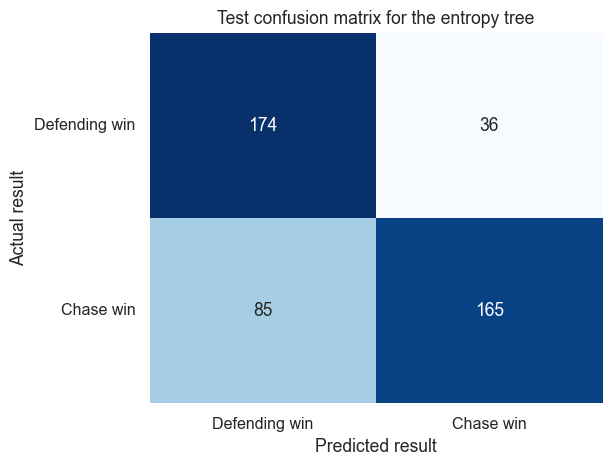

The tree correctly identified **165 of 250** chase wins and **174 of 210** defending wins. It missed 85 chase wins and falsely predicted 36 chase wins.

In [42]:
matrix = confusion_matrix(y_test, selected_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Defending win", "Chase win"], yticklabels=["Defending win", "Chase win"], ax=ax)
ax.set(xlabel="Predicted result", ylabel="Actual result", title=f"Test confusion matrix for the {chosen_criterion} tree")
ax.tick_params(axis="y", labelrotation=0)
save_plot(fig, "13_tree_confusion_matrix")
note(f"The tree correctly identified **{matrix[1, 1]} of {matrix[1].sum()}** chase wins and "
     f"**{matrix[0, 0]} of {matrix[0].sum()}** defending wins. "
     f"It missed {matrix[1, 0]} chase wins and falsely predicted {matrix[0, 1]} chase wins.")

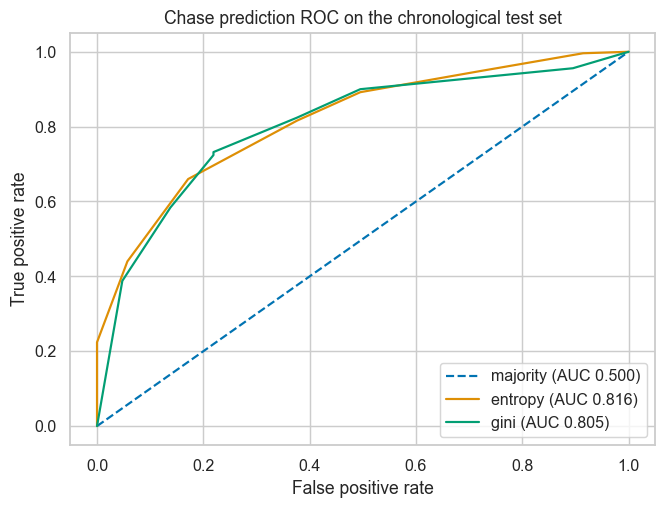

The selected tree's test AUC is **0.816**, compared with the majority baseline's 0.500. AUC measures ranking over thresholds. With the fitted decision threshold, test accuracy is 73.7% and chase-win F1 is 0.732.

In [43]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, probability in test_probabilities.items():
    false_positive, true_positive, _ = roc_curve(y_test, probability)
    ax.plot(false_positive, true_positive, label=f"{name} (AUC {roc_auc_score(y_test, probability):.3f})",
            linestyle="--" if name == "majority" else "-")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Chase prediction ROC on the chronological test set")
ax.legend(loc="lower right")
save_plot(fig, "14_tree_roc")
note(f"The selected tree's test AUC is **{selected_metrics.roc_auc:.3f}**, compared with the majority baseline's "
     f"{baseline_metrics.roc_auc:.3f}. AUC measures ranking over thresholds. "
     f"With the fitted decision threshold, test accuracy is {selected_metrics.test_accuracy:.1%} "
     f"and chase-win F1 is {selected_metrics.f1:.3f}.")

**Entropy tree IF–THEN rules**

IF first_total_runs <= 157.5 AND first_total_runs <= 114.5 AND first_total_runs <= 89.5 THEN Chase win
IF first_total_runs <= 157.5 AND first_total_runs <= 114.5 AND first_total_runs > 89.5 THEN Chase win
IF first_total_runs <= 157.5 AND first_total_runs > 114.5 AND chasing_team_infrequent_sklearn <= 0.5 THEN Chase win
IF first_total_runs <= 157.5 AND first_total_runs > 114.5 AND chasing_team_infrequent_sklearn > 0.5 THEN Defending win
IF first_total_runs > 157.5 AND chasing_team_infrequent_sklearn <= 0.5 AND first_total_runs <= 177.5 THEN Defending win
IF first_total_runs > 157.5 AND chasing_team_infrequent_sklearn <= 0.5 AND first_total_runs > 177.5 THEN Defending win
IF first_total_runs > 157.5 AND chasing_team_infrequent_sklearn > 0.5 AND first_total_runs <= 196.5 THEN Defending win
IF first_total_runs > 157.5 AND chasing_team_infrequent_sklearn > 0.5 AND first_total_runs > 196.5 THEN Defending win


**Gini tree IF–THEN rules**

IF first_total_runs <= 157.5 AND first_total_runs <= 130.5 AND first_total_runs <= 109.5 THEN Chase win
IF first_total_runs <= 157.5 AND first_total_runs <= 130.5 AND first_total_runs > 109.5 THEN Chase win
IF first_total_runs <= 157.5 AND first_total_runs > 130.5 AND chasing_team_infrequent_sklearn <= 0.5 THEN Chase win
IF first_total_runs <= 157.5 AND first_total_runs > 130.5 AND chasing_team_infrequent_sklearn > 0.5 THEN Defending win
IF first_total_runs > 157.5 AND first_total_runs <= 177.5 AND chasing_team_infrequent_sklearn <= 0.5 THEN Defending win
IF first_total_runs > 157.5 AND first_total_runs <= 177.5 AND chasing_team_infrequent_sklearn > 0.5 THEN Defending win
IF first_total_runs > 157.5 AND first_total_runs > 177.5 AND chasing_team_India <= 0.5 THEN Defending win
IF first_total_runs > 157.5 AND first_total_runs > 177.5 AND chasing_team_India > 0.5 THEN Defending win


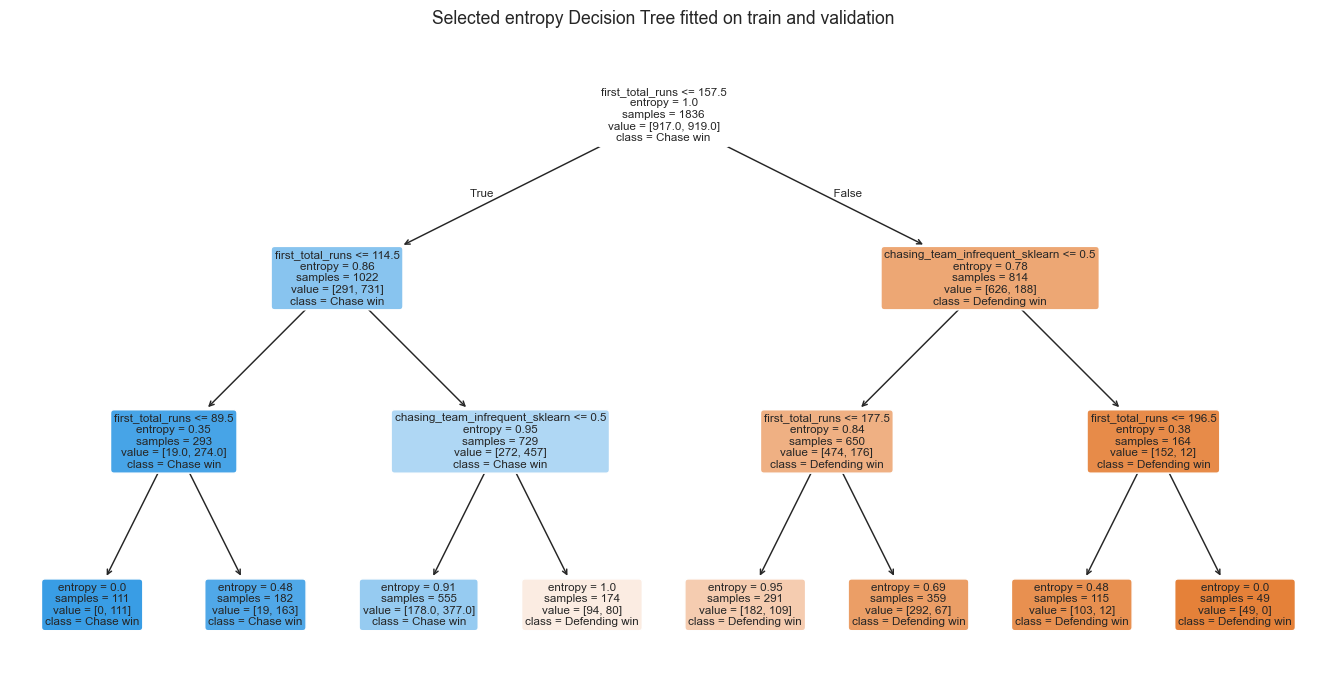

The root splits on **first_total_runs** at 157.50. The fitted tree has 8 leaves and depth 3.

In [44]:
def sklearn_rules(model, columns, criterion):
    tree = model.tree_
    rows = []

    def walk(node, tests):
        left, right = tree.children_left[node], tree.children_right[node]
        if left == right:
            values = tree.value[node, 0]
            prediction = model.classes_[values.argmax()]
            decision = "Chase win" if prediction == 1 else "Defending win"
            conditions = " AND ".join(tests) or "any match"
            rows.append({
                "engine": "scikit-learn", "model": criterion, "leaf": node,
                "if_then_rule": f"IF {conditions} THEN {decision}",
                "fit_matches_at_leaf": int(tree.n_node_samples[node]),
                "chase_win_probability": values[1] / values.sum(),
            })
            return
        feature = columns[tree.feature[node]]
        threshold = tree.threshold[node]
        walk(left, [*tests, f"{feature} <= {threshold:.10g}"])
        walk(right, [*tests, f"{feature} > {threshold:.10g}"])

    walk(0, [])
    return pd.DataFrame(rows)


local_rule_tables = {
    name: sklearn_rules(model, feature_names, name) for name, model in local_models.items() if name != "majority"
}
for name, rules in local_rule_tables.items():
    note(f"**{name.title()} tree IF–THEN rules**")
    for line in rules.if_then_rule:
        print(line)

fig, ax = plt.subplots(figsize=(max(11.5, 1.6 * selected_tree.get_n_leaves()), 6.8))
plot_tree(selected_tree, feature_names=feature_names, class_names=["Defending win", "Chase win"],
          filled=True, rounded=True, precision=2, fontsize=8, ax=ax)
ax.set_title(f"Selected {chosen_criterion} Decision Tree fitted on train and validation")
save_plot(fig, "15_decision_tree")
root_feature = feature_names[selected_tree.tree_.feature[0]]
note(f"The root splits on **{root_feature}** at {selected_tree.tree_.threshold[0]:.2f}. "
     f"The fitted tree has {selected_tree.get_n_leaves()} leaves and depth {selected_tree.get_depth()}.")

,engine,model,feature,importance
0,scikit-learn,entropy,first_total_runs,0.9097
75,scikit-learn,entropy,chasing_team_infrequent_sklearn,0.0903


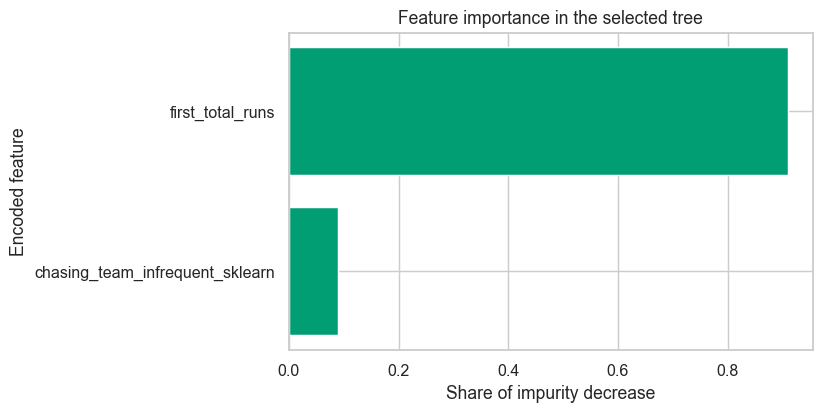

**first_total_runs** accounts for 91.0% of the impurity reduction. Importance reflects how the tree split this sample. Accuracy was 74.7% on the fit rows and 73.7% on the later test rows, a fit-minus-test gap of +1.0 percentage points. Even a shallow tree can learn patterns specific to the teams and venues in the fit period. Schedule changes, unrecorded conditions and newer teams can affect performance.

In [45]:
local_importances = pd.concat([
    pd.DataFrame({"engine": "scikit-learn", "model": name, "feature": feature_names,
                  "importance": model.feature_importances_})
    for name, model in local_models.items() if name != "majority"
], ignore_index=True)
leading_features = local_importances.loc[local_importances.model.eq(chosen_criterion)].nlargest(10, "importance")
leading_features = leading_features.loc[leading_features.importance.gt(0)].sort_values("importance")
display(leading_features.sort_values("importance", ascending=False))
fig, ax = plt.subplots(figsize=(8, 4.1))
ax.barh(leading_features.feature, leading_features.importance, color=GREEN)
ax.set(xlabel="Share of impurity decrease", ylabel="Encoded feature", title="Feature importance in the selected tree")
save_plot(fig, "16_tree_feature_importance")
gap = selected_metrics.train_accuracy - selected_metrics.test_accuracy
note(f"**{leading_features.feature.iloc[-1]}** accounts for {leading_features.importance.iloc[-1]:.1%} of "
     "the impurity reduction. Importance reflects how the tree split this sample. "
     f"Accuracy was {selected_metrics.train_accuracy:.1%} on the fit rows and {selected_metrics.test_accuracy:.1%} "
     f"on the later test rows, a fit-minus-test gap of {100 * gap:+.1f} percentage points. "
     "Even a shallow tree can learn patterns specific to the teams and venues in the fit period. "
     "Schedule changes, unrecorded conditions and newer teams can affect performance.")

## 6. Hierarchical AGNES clustering

AGNES starts with one cluster per player, merges the closest pair and repeats. Single linkage uses the closest pair of points. Complete linkage uses the farthest pair. Average linkage uses the mean pairwise distance. Ward linkage merges the pair with the smallest increase in within-cluster squared error.

We use batting profiles from players with at least 12 innings batted and 120 total balls faced. This avoids comparing a one-off innings with a longer record. The features cover run output, scoring pace, how runs were scored and how often the batter was dismissed. They describe batting performance, irrespective of the player's bowling role.

In [46]:
toy_points = pd.DataFrame({"runs": [0, 1, 3, 3], "pace": [0, 0, 2, 3]}, index=list("ABCD"))
toy_distances = pd.DataFrame(squareform(pdist(toy_points)), index=toy_points.index, columns=toy_points.index)
toy_links = linkage(toy_points, method="single", metric="euclidean")
labels = dict(enumerate(toy_points.index))
merges = []
for index, (left, right, distance, size) in enumerate(toy_links, start=1):
    left, right = labels[int(left)], labels[int(right)]
    merged = "{" + left + ", " + right + "}"
    labels[len(toy_points) + index - 1] = merged
    merges.append({"step": index, "left": left, "right": right, "distance": distance, "new_cluster": merged, "size": int(size)})
display(toy_points, toy_distances, pd.DataFrame(merges))
note(f"Single linkage first joins **{merges[0]['left']} and {merges[0]['right']}** at distance "
     f"{merges[0]['distance']:.1f}. The remaining two groups join at distance {merges[-1]['distance']:.2f}.")

,runs,pace
A,0,0
B,1,0
C,3,2
D,3,3


,A,B,C,D
A,0.0000,1.0000,3.6056,4.2426
B,1.0000,0.0000,2.8284,3.6056
C,3.6056,2.8284,0.0000,1.0000
D,4.2426,3.6056,1.0000,0.0000


,step,left,right,distance,new_cluster,size
0,1,A,B,1.0000,"{A, B}",2
1,2,C,D,1.0000,"{C, D}",2
2,3,"{A, B}","{C, D}",2.8284,"{{A, B}, {C, D}}",4


Single linkage first joins **A and B** at distance 1.0. The remaining two groups join at distance 2.83.

In [47]:
player_profiles = played.dropna(subset=["is_out"]).groupby(["player_id", "player_label"], as_index=False).agg(
    innings_batted=("match_id", "size"), total_balls=("balls", "sum"), total_runs=("runs", "sum"),
    boundary_runs=("boundary_runs", "sum"), dismissals=("is_out", "sum"),
)
cluster_scope = player_profiles.loc[
    player_profiles.innings_batted.ge(12) & player_profiles.total_balls.ge(120) & player_profiles.total_runs.gt(0)
].copy().reset_index(drop=True)
cluster_scope["runs_per_innings"] = cluster_scope.total_runs / cluster_scope.innings_batted
cluster_scope["strike_rate"] = 100 * cluster_scope.total_runs / cluster_scope.total_balls
cluster_scope["boundary_pct"] = 100 * cluster_scope.boundary_runs / cluster_scope.total_runs
cluster_scope["dismissal_pct"] = 100 * cluster_scope.dismissals / cluster_scope.innings_batted
cluster_features = ["runs_per_innings", "strike_rate", "boundary_pct", "dismissal_pct"]
cluster_input = cluster_scope[cluster_features].astype(float)
cluster_values = StandardScaler().fit_transform(cluster_input)
scaled_preview = pd.concat(
    [cluster_input.head(4), pd.DataFrame(cluster_values[:4], columns=[f"{item}_z" for item in cluster_features])],
    axis=1,
)
min_max_preview = pd.DataFrame(MinMaxScaler().fit_transform(cluster_input)[:4], columns=cluster_features)
cluster_correlation = cluster_input.corr()
save_table(cluster_correlation.rename_axis("feature").reset_index(), "clustering_correlations")
display(scaled_preview, min_max_preview, cluster_correlation)
note(f"**{len(cluster_scope):,} players** qualify. Z-score scaling centers each feature at zero and gives it "
     "unit variance before distances are measured. The min–max example maps each feature to a 0–1 scale. "
     f"Strike rate and boundary percentage correlate at {cluster_correlation.loc['strike_rate', 'boundary_pct']:.2f}. "
     "Strike rate includes all scoring. Boundary percentage describes how the runs were made.")

,runs_per_innings,strike_rate,boundary_pct,dismissal_pct,runs_per_innings_z,strike_rate_z,boundary_pct_z,dismissal_pct_z
0,20.9667,129.1581,70.2703,90.0000,0.5330,0.5912,1.5050,0.6295
1,15.5909,98.8473,48.3965,77.2727,-0.2465,-0.8009,-0.4223,-0.3439
2,25.0625,132.7815,57.3566,87.5000,1.1269,0.7576,0.3672,0.4383
3,28.9565,119.3548,51.6517,82.6087,1.6915,0.1410,-0.1355,0.0642


,runs_per_innings,strike_rate,boundary_pct,dismissal_pct
0,0.3688,0.5731,0.8519,0.8533
1,0.2585,0.3582,0.5555,0.6667
2,0.4529,0.5988,0.6769,0.8167
3,0.5328,0.5036,0.5996,0.7449


,runs_per_innings,strike_rate,boundary_pct,dismissal_pct
runs_per_innings,1.0000,0.5586,0.4626,0.3311
strike_rate,0.5586,1.0000,0.7562,-0.0227
boundary_pct,0.4626,0.7562,1.0000,0.2590
dismissal_pct,0.3311,-0.0227,0.2590,1.0000


**934 players** qualify. Z-score scaling centers each feature at zero and gives it unit variance before distances are measured. The min–max example maps each feature to a 0–1 scale. Strike rate and boundary percentage correlate at 0.76. Strike rate includes all scoring. Boundary percentage describes how the runs were made.

We compare all four linkages for 2 to 7 clusters on the same standardized data. We choose the highest silhouette score among partitions whose smallest cluster has at least 15 players and at least 5% of the sample. This helps avoid calling a handful of unusual players a batting group.

linkage,average,complete,single,ward
clusters,,,,
2,0.5181,0.2589,0.5018,0.2390
3,0.3211,0.2671,0.4522,0.2364
4,0.2405,0.2193,0.3254,0.1938
5,0.1969,0.1853,0.3226,0.1675
6,0.1632,0.1571,0.2874,0.1491
7,0.1400,0.1491,0.2116,0.1552


,selected
linkage,complete
clusters,3
silhouette,0.2671
smallest_cluster,71
eligible,True


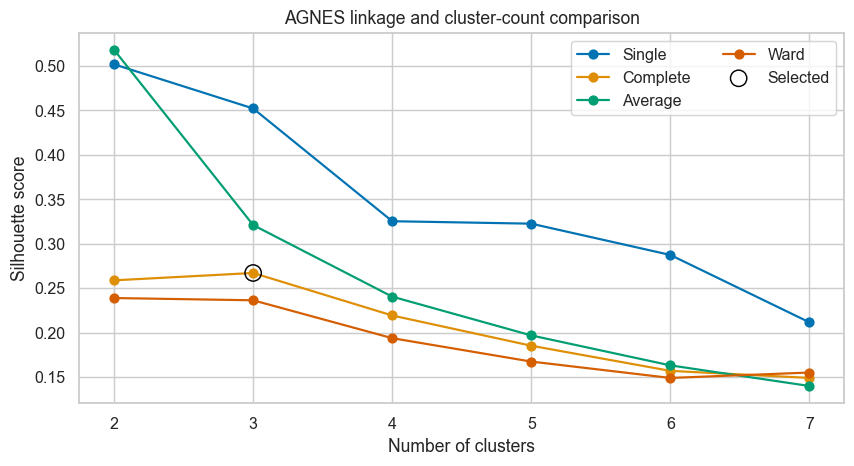

**Complete linkage with 3 clusters** has the best eligible silhouette (0.267). The smallest group has 71 players. Across all cuts, the highest raw score is 0.518 for average with 2 clusters and only 1 in its smallest group.

In [48]:
linkages = {}
labels_by_method = {}
silhouette_rows = []
minimum_cluster_size = max(15, math.ceil(0.05 * len(cluster_scope)))
cluster_counts = range(2, 8)
for method in ("single", "complete", "average", "ward"):
    tree = linkage(cluster_values, method=method, metric="euclidean")
    linkages[method] = tree
    cuts = cut_tree(tree, n_clusters=list(cluster_counts))
    for column, k in enumerate(cluster_counts):
        assignments = cuts[:, column]
        smallest = np.bincount(assignments).min()
        silhouette_rows.append({
            "linkage": method, "clusters": k, "silhouette": silhouette_score(cluster_values, assignments),
            "smallest_cluster": smallest, "eligible": smallest >= minimum_cluster_size,
        })
        labels_by_method[(method, k)] = assignments

silhouettes = pd.DataFrame(silhouette_rows)
chosen_cluster = silhouettes.loc[silhouettes.eligible].sort_values(
    ["silhouette", "clusters", "linkage"], ascending=[False, True, True],
).iloc[0]
method, k = chosen_cluster.linkage, int(chosen_cluster.clusters)
cluster_tree = linkages[method]
labels_agnes = labels_by_method[(method, k)]
save_table(silhouettes, "agnes_silhouettes")
display(silhouettes.pivot(index="clusters", columns="linkage", values="silhouette"), chosen_cluster.to_frame("selected"))

fig, ax = plt.subplots(figsize=(8.3, 4.6))
for name, group in silhouettes.groupby("linkage", sort=False):
    ax.plot(group.clusters, group.silhouette, marker="o", label=name.title())
ax.scatter(k, chosen_cluster.silhouette, s=125, facecolors="none", edgecolors="black", label="Selected", zorder=5)
ax.set(xlabel="Number of clusters", ylabel="Silhouette score", title="AGNES linkage and cluster-count comparison")
ax.set_xticks(list(cluster_counts))
ax.legend(ncol=2)
save_plot(fig, "17_agnes_silhouette")
raw_best = silhouettes.loc[silhouettes.silhouette.idxmax()]
note(f"**{method.title()} linkage with {k} clusters** has the best eligible silhouette ({chosen_cluster.silhouette:.3f}). "
     f"The smallest group has {chosen_cluster.smallest_cluster} players. Across all cuts, the highest raw score is "
     f"{raw_best.silhouette:.3f} for {raw_best.linkage} with {raw_best.clusters} clusters "
     f"and only {raw_best.smallest_cluster} in its smallest group.")

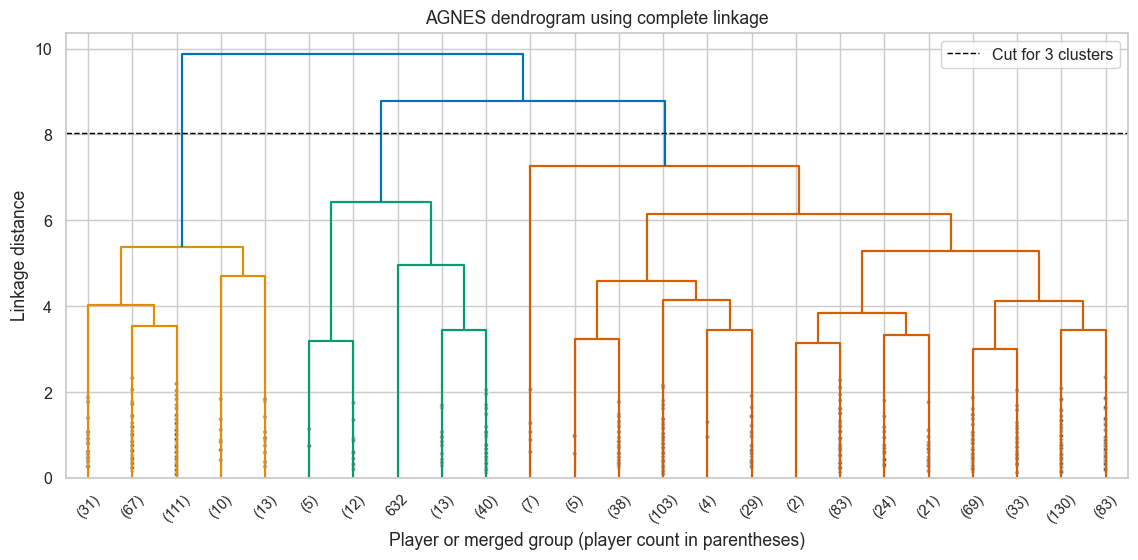

The cut at **8.02** is between merge heights 7.26 and 8.78. It crosses 3 branches. For readability the bottom row shows the last 24 branch groups.

In [49]:
lower_height, upper_height = cluster_tree[-k, 2], cluster_tree[-k + 1, 2]
cut_height = (lower_height + upper_height) / 2
fig, ax = plt.subplots(figsize=(11, 5.5))
dendrogram(cluster_tree, truncate_mode="lastp", p=24, show_contracted=True, color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, color="black", linestyle="--", linewidth=1, label=f"Cut for {k} clusters")
ax.set(xlabel="Player or merged group (player count in parentheses)", ylabel="Linkage distance",
       title=f"AGNES dendrogram using {method} linkage")
ax.legend()
save_plot(fig, "18_agnes_dendrogram")
note(f"The cut at **{cut_height:.2f}** is between merge heights {lower_height:.2f} and {upper_height:.2f}. "
     f"It crosses {k} branches. For readability the bottom row shows the last 24 branch groups.")

In [50]:
# Number the groups from lowest to highest average runs per innings.
run_order = cluster_scope.assign(group=labels_agnes).groupby("group").runs_per_innings.mean().sort_values().index
cluster_number = {group: index for index, group in enumerate(run_order, start=1)}
cluster_scope["cluster"] = pd.Series(labels_agnes).map(cluster_number)
cluster_profiles = cluster_scope.groupby("cluster", as_index=False).agg(
    players=("player_id", "size"), runs_per_innings=("runs_per_innings", "mean"), strike_rate=("strike_rate", "mean"),
    boundary_pct=("boundary_pct", "mean"), dismissal_pct=("dismissal_pct", "mean"),
)
representatives = []
for cluster, group in cluster_scope.groupby("cluster"):
    scaled_group = cluster_values[group.index]
    distance = np.linalg.norm(scaled_group - scaled_group.mean(axis=0), axis=1)
    nearest = group.assign(distance_to_centroid=distance).nsmallest(3, "distance_to_centroid")
    representatives.append(nearest[["cluster", "player_id", "player_label", *cluster_features, "distance_to_centroid"]])
representative_players = pd.concat(representatives, ignore_index=True)
save_table(cluster_profiles, "cluster_profiles")
save_table(cluster_profiles[["cluster", "players"]], "cluster_sizes")
save_table(representative_players, "cluster_representative_players")
save_processed(cluster_scope, "player_batting_clusters")
display(cluster_profiles, representative_players)
for profile in cluster_profiles.itertuples(index=False):
    closest = representative_players.loc[representative_players.cluster.eq(profile.cluster), "player_label"].tolist()
    pace = "above" if profile.strike_rate >= cluster_input.strike_rate.mean() else "below"
    note(f"**Cluster {profile.cluster} ({profile.players} players).** Batters averaged "
         f"{profile.runs_per_innings:.1f} runs per innings with strike rate {profile.strike_rate:.1f}, "
         f"{pace} the overall player average of {cluster_input.strike_rate.mean():.1f}. Boundaries made up "
         f"{profile.boundary_pct:.1f}% of runs and these players were dismissed in {profile.dismissal_pct:.1f}% "
         f"of innings on average. Players near the center include {', '.join(closest)}.")

,cluster,players,runs_per_innings,strike_rate,boundary_pct,dismissal_pct
0,1,71,10.9787,116.9657,49.9161,53.7111
1,2,232,12.0293,90.8766,40.3743,82.7636
2,3,631,19.9359,125.5518,58.2696,84.5610


,cluster,player_id,player_label,runs_per_innings,strike_rate,boundary_pct,dismissal_pct,distance_to_centroid
0,1,70884,Mohammad Saifuddin,10.0000,113.6364,53.0000,55.0000,0.3565
1,1,64864,Mitchell Santner,9.5588,122.1805,49.8462,58.8235,0.5027
2,1,109784,Devender Singh,13.7368,118.0995,48.2759,57.8947,0.5347
3,2,96720,Kadek Gamantika,13.9286,93.7500,42.0513,82.1429,0.3426
4,2,65832,Andrew Reyes,10.8462,81.5029,39.7163,84.6154,0.4881
5,2,112101,Mehar Cheema,9.1429,91.4286,42.1875,85.7143,0.5023
6,3,48736,Tom Cooper,20.5938,129.4695,57.6631,87.5000,0.3080
7,3,111967,Doyle-Calle,21.9000,125.5014,59.8174,85.0000,0.3176
8,3,107566,Usman Patel,18.5897,122.8814,59.5862,82.0513,0.3216


**Cluster 1 (71 players).** Batters averaged 11.0 runs per innings with strike rate 117.0, above the overall player average of 116.3. Boundaries made up 49.9% of runs and these players were dismissed in 53.7% of innings on average. Players near the center include Mohammad Saifuddin, Mitchell Santner, Devender Singh.

**Cluster 2 (232 players).** Batters averaged 12.0 runs per innings with strike rate 90.9, below the overall player average of 116.3. Boundaries made up 40.4% of runs and these players were dismissed in 82.8% of innings on average. Players near the center include Kadek Gamantika, Andrew Reyes, Mehar Cheema.

**Cluster 3 (631 players).** Batters averaged 19.9 runs per innings with strike rate 125.6, above the overall player average of 116.3. Boundaries made up 58.3% of runs and these players were dismissed in 84.6% of innings on average. Players near the center include Tom Cooper, Doyle-Calle, Usman Patel.

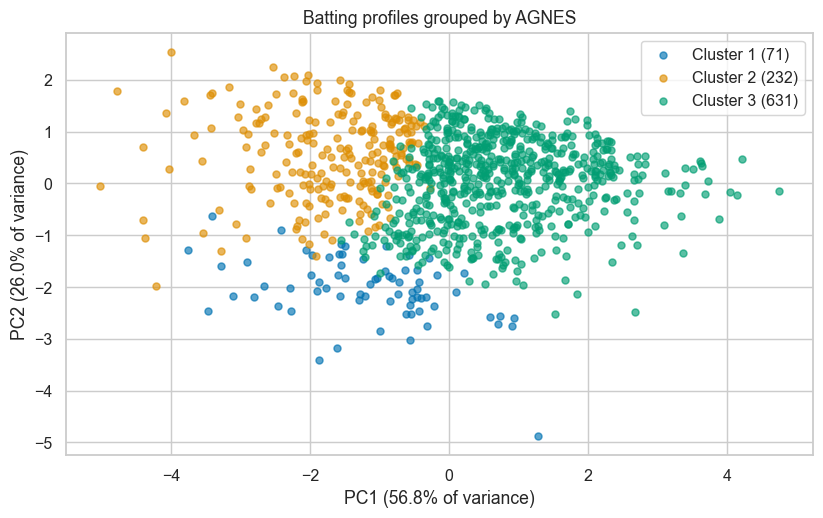

The two axes display **82.8%** of the standardized variance. Cluster sizes range from 71 to 631 players. The original four features determine cluster membership.

AGNES used 435,711 possible player pairs here. Pairwise distances grow quadratically with the number of players, which limits larger runs. The clusters summarize career scorecards in this sample. Batting position, era and opposition can all influence a profile.

In [51]:
pca = PCA(n_components=2, random_state=SEED)
projection = pca.fit_transform(cluster_values)
explained_pc = pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(8, 5.1))
for number, group in cluster_scope.groupby("cluster"):
    points = projection[group.index]
    ax.scatter(points[:, 0], points[:, 1], s=23, alpha=0.65, label=f"Cluster {number} ({len(group)})")
ax.set(xlabel=f"PC1 ({explained_pc[0]:.1%} of variance)", ylabel=f"PC2 ({explained_pc[1]:.1%} of variance)",
       title="Batting profiles grouped by AGNES")
ax.legend()
save_plot(fig, "19_agnes_player_clusters")
note(f"The two axes display **{explained_pc.sum():.1%}** of the standardized variance. Cluster sizes range from "
     f"{cluster_profiles.players.min()} to {cluster_profiles.players.max()} players. The original four "
     "features determine cluster membership.")
note(f"AGNES used {math.comb(len(cluster_scope), 2):,} possible player pairs here. Pairwise distances grow "
     "quadratically with the number of players, which limits larger runs. The clusters summarize career "
     "scorecards in this sample. Batting position, era and opposition can all influence a profile.")

## 7. PySpark on the same data

Spark runs locally on a single machine. Both Spark backends and Python use the same DIC checkpoint controller, block boundaries and support thresholds.

The original RDD backend starts one support-counting action per checkpoint. It creates a Python broadcast of the active candidate masks, sends a Python function to each partition and gathers partial counts. For a small block, scheduling and exchanges between Python and the JVM can cost more time than checking the masks. Four partitions give Spark work to share across local threads, but each partition still needs a task even when it holds only a few hundred transactions.

The Spark SQL backend groups identical masks within each block and caches their occurrence counts. A mask with count 8 contributes 8 to the support of each active candidate it contains. At each checkpoint, Spark filters the same block and uses built-in expressions in the JVM to sum exact support counts. The driver sends only the active candidate list and receives the resulting counts. This removes the Python broadcast and worker function from each checkpoint. The JVM still schedules a counting action at every checkpoint since the next active candidates depend on these results. Spark can coalesce small shuffle partitions under its default adaptive settings.

[Apache Spark SQL performance guide](https://spark.apache.org/docs/3.5.8/sql-performance-tuning.html) · [Spark SQL built-in functions](https://spark.apache.org/docs/3.5.8/api/sql/)

In [52]:
import shutil
import psutil
import pyspark
import scipy
import sklearn
from pyspark.ml.classification import DecisionTreeClassifier as SparkDecisionTree
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, LongType, StructField, StructType

if not os.environ.get("JAVA_HOME"):
    # The reviewed Windows run uses a portable JDK in the workspace.
    java_name = "java.exe" if os.name == "nt" else "java"
    bundled_java = sorted(Path(".work/java").glob(f"*/bin/{java_name}"))
    if bundled_java:
        os.environ["JAVA_HOME"] = str(bundled_java[0].resolve().parent.parent)
    elif shutil.which(java_name) is None:
        raise RuntimeError("Install OpenJDK 17 and set JAVA_HOME or put java on PATH before this section.")
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
SPARK_THREADS = max(1, min(4, os.cpu_count() or 1))
start = time.perf_counter()
spark = (
    SparkSession.builder.master(f"local[{SPARK_THREADS}]").appName("T20I practical analytics")
    .config("spark.ui.enabled", "false").config("spark.driver.host", "127.0.0.1")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.default.parallelism", str(SPARK_THREADS))
    .config("spark.sql.shuffle.partitions", str(SPARK_THREADS))
    .getOrCreate()
)
spark_startup = time.perf_counter() - start
spark.sparkContext.setLogLevel("ERROR")
start = time.perf_counter()
assert spark.range(1).count() == 1
spark_first_action = time.perf_counter() - start
environment = pd.DataFrame([{
    "os": platform.platform(), "processor": platform.processor(),
    "physical_cores": psutil.cpu_count(logical=False), "logical_cores": psutil.cpu_count(),
    "memory_gib": psutil.virtual_memory().total / (1024 ** 3),
    "openblas_threads": os.environ.get("OPENBLAS_NUM_THREADS", "default"),
    "omp_threads": os.environ.get("OMP_NUM_THREADS", "default"),
    "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "scipy": scipy.__version__, "scikit_learn": sklearn.__version__,
    "spark": spark.version, "pyspark": pyspark.__version__,
    "java": spark.sparkContext._jvm.java.lang.System.getProperty("java.version"),
    "spark_master": spark.sparkContext.master, "spark_threads": SPARK_THREADS,
    "spark_startup_seconds": spark_startup, "spark_first_action_seconds": spark_first_action,
}])
save_table(environment, "runtime_environment")
display(environment.T)

,0
os,Windows-10-10.0.26300-SP0
processor,"AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD"
physical_cores,6
logical_cores,12
memory_gib,15.1924
openblas_threads,1
omp_threads,1
python,3.11.14
pandas,2.2.3
numpy,1.26.4


In [53]:
def spark_dic_rdd_input(context, encoded):
    _, blocks = encoded
    distributed = [
        context.parallelize(block, min(SPARK_THREADS, len(block))).cache() for block in blocks
    ]
    # One action materializes every block before any warm counting timers begin.
    assert context.union(distributed).count() == sum(map(len, blocks))
    return distributed


def add_counts(left, right):
    return [a + b for a, b in zip(left, right)]


def dic_spark_rdd(context, encoded, distributed, min_support):
    bit_by_item, blocks = encoded

    def count_block(block_index, masks):
        active_masks = context.broadcast(masks)

        def count_partition(iterator):
            yield count_masks(iterator, active_masks.value)

        try:
            counts = distributed[block_index].mapPartitions(count_partition)
            return counts.fold([0] * len(masks), add_counts)
        finally:
            active_masks.destroy()

    return dic_scan(bit_by_item, list(map(len, blocks)), count_block, min_support)

In [54]:
def spark_dic_sql_input(session, encoded):
    bit_by_item, blocks = encoded
    if len(bit_by_item) > 63:
        raise ValueError("The Spark SQL counter uses signed long masks. Use the RDD counter for more than 63 items.")
    # Each transaction still creates a row. Spark groups equal masks only within their block.
    entries = [(index, mask) for index, block in enumerate(blocks) for _, mask in block]
    histogram = (
        session.createDataFrame(entries, "block_index INT, transaction_mask LONG")
        .groupBy("block_index", "transaction_mask").count()
        .withColumnRenamed("count", "occurrences").cache()
    )
    # This action fills the cache and checks that every original row is counted.
    block_totals = histogram.groupBy("block_index").agg(
        F.sum("occurrences").alias("transaction_count"), F.count("*").alias("distinct_masks"),
    ).collect()
    assert {row.block_index: row.transaction_count for row in block_totals} == {
        index: len(block) for index, block in enumerate(blocks)
    }
    return histogram, sum(row.distinct_masks for row in block_totals)


def dic_spark_sql(encoded, histogram, min_support):
    bit_by_item, blocks = encoded

    def count_block(block_index, masks):
        # The lambda builds a Spark SQL expression. Spark evaluates it inside the JVM.
        present = F.filter(
            F.lit(masks), lambda mask: F.col("transaction_mask").bitwiseAND(mask) == mask,
        )
        counts = (
            histogram.where(F.col("block_index") == block_index)
            .select(F.explode(present).alias("candidate"), "occurrences")
            .groupBy("candidate").agg(F.sum("occurrences").alias("support"))
            .collect()
        )
        support_by_mask = {row.candidate: row.support for row in counts}
        return [support_by_mask.get(mask, 0) for mask in masks]

    return dic_scan(bit_by_item, list(map(len, blocks)), count_block, min_support)

### Spark Decision Trees

Spark receives the same encoded features and match IDs used by scikit-learn. VectorAssembler builds the Spark feature vector. Both engines use the same validation-selected depth and minimum leaf size for each impurity criterion. Spark bins candidate split points, which can produce a different tree even with these settings.

In [55]:
spark_features = [f"x{i}" for i in range(len(feature_names))]
spark_schema = StructType([
    StructField("row_id", LongType(), False), StructField("label", DoubleType(), False),
    *[StructField(name, DoubleType(), False) for name in spark_features],
])
assembler = VectorAssembler(inputCols=spark_features, outputCol="features")


def encoded_tree_records(ids, matrix, labels):
    return [(int(row_id), float(label), *row)
            for row_id, row, label in zip(ids, matrix.tolist(), labels)]


def spark_tree_input(records):
    frame = spark.createDataFrame(records, schema=spark_schema)
    cached = assembler.transform(frame).select("row_id", "label", "features").cache()
    assert cached.count() == len(records)
    return cached


def make_spark_tree(criterion, config):
    return SparkDecisionTree(
        impurity=criterion, maxDepth=int(config.max_depth), minInstancesPerNode=int(config.min_leaf),
        seed=SEED, maxBins=32, labelCol="label", featuresCol="features",
    )


def collect_spark_probabilities(model, frame):
    # The collect is part of prediction time on Spark. Sort by ID in Python.
    rows = model.transform(frame).select(
        "row_id", "label", "prediction", vector_to_array("probability").getItem(1).alias("chase_probability")
    ).collect()
    rows.sort(key=lambda row: row.row_id)
    return pd.DataFrame(rows, columns=["row_id", "label", "prediction", "chase_probability"])


def spark_rules(model, criterion):
    conditions = {}
    rows = []
    for line in model.toDebugString.splitlines():
        body = line.strip()
        depth = len(line) - len(line.lstrip())
        if body.startswith(("If (", "Else (")):
            condition = body[body.index("(") + 1:-1]
            condition = re.sub(r"\bfeature (\d+)\b", lambda match: feature_names[int(match[1])], condition)
            conditions = {level: text for level, text in conditions.items() if level < depth}
            conditions[depth] = condition
        elif body.startswith("Predict:"):
            label = float(body.split()[-1])
            side = "Chase win" if label == 1 else "Defending win"
            clauses = " AND ".join(conditions.values()) or "any match"
            rows.append({
                "engine": "PySpark", "model": criterion, "leaf": len(rows) + 1,
                "if_then_rule": f"IF {clauses} THEN {side}",
            })
    assert len(rows) == (model.numNodes + 1) // 2
    return pd.DataFrame(rows)


development_records = encoded_tree_records(development.match_id, x_development, y_development)
test_records = encoded_tree_records(test.match_id, x_test, y_test)
fit_spark = spark_tree_input(development_records)
test_spark = spark_tree_input(test_records)
spark_performance = []
spark_rule_tables = []
spark_importances = []
for criterion, config in best_per_criterion.iterrows():
    start = time.perf_counter()
    model = make_spark_tree(criterion, config).fit(fit_spark)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    test_rows = collect_spark_probabilities(model, test_spark)
    predict_seconds = time.perf_counter() - start
    fit_rows = collect_spark_probabilities(model, fit_spark)
    assert test_rows.row_id.tolist() == sorted(test.match_id.tolist())
    assert fit_rows.row_id.tolist() == sorted(development.match_id.tolist())
    assert test_rows.label.tolist() == test.sort_values("match_id").chase_won.tolist()
    spark_performance.append(performance_row(
        "PySpark", criterion, fit_rows.label, fit_rows.prediction, test_rows.label, test_rows.prediction,
        test_rows.chase_probability, fit_seconds, predict_seconds,
    ))
    print(model.toDebugString)
    extracted = spark_rules(model, criterion)
    spark_rule_tables.append(extracted)
    for line in extracted.if_then_rule:
        print(line)
    spark_importances.append(pd.DataFrame({
        "engine": "PySpark", "model": criterion, "feature": feature_names,
        "importance": model.featureImportances.toArray(),
    }))
fit_spark.unpersist(blocking=True)
test_spark.unpersist(blocking=True)

classification_metrics = pd.concat([local_metrics, pd.DataFrame(spark_performance)], ignore_index=True)
settings = best_per_criterion[["max_depth", "min_leaf"]].reset_index().rename(columns={"criterion": "model"})
classification_metrics = classification_metrics.merge(settings, on="model", how="left", validate="many_to_one")
classification_rules = pd.concat([*local_rule_tables.values(), *spark_rule_tables], ignore_index=True)
feature_importance = pd.concat([local_importances, *spark_importances], ignore_index=True)
save_table(classification_metrics, "classification_performance")
save_table(classification_rules, "classification_if_then_rules")
save_table(feature_importance, "classification_feature_importance")
display(classification_metrics, pd.concat(spark_importances).query("importance > 0").sort_values("importance", ascending=False).head(10))
spark_selected = classification_metrics.loc[
    classification_metrics.engine.eq("PySpark") & classification_metrics.model.eq(chosen_criterion)
].iloc[0]
note(f"Using {chosen_criterion} and the same test match IDs, Spark has **{spark_selected.test_accuracy:.1%}** "
     f"test accuracy and scikit-learn has **{selected_metrics.test_accuracy:.1%}**.")

DecisionTreeClassificationModel: uid=DecisionTreeClassifier_f3aacfffb509, depth=3, numNodes=7, numClasses=2, numFeatures=111
  If (feature 0 <= 146.5)
   If (feature 0 <= 113.5)
    Predict: 1.0
   Else (feature 0 > 113.5)
    If (feature 75 <= 0.5)
     Predict: 1.0
    Else (feature 75 > 0.5)
     Predict: 0.0
  Else (feature 0 > 146.5)
   Predict: 0.0

IF first_total_runs <= 146.5 AND first_total_runs <= 113.5 THEN Chase win
IF first_total_runs <= 146.5 AND first_total_runs > 113.5 AND chasing_team_infrequent_sklearn <= 0.5 THEN Chase win
IF first_total_runs <= 146.5 AND first_total_runs > 113.5 AND chasing_team_infrequent_sklearn > 0.5 THEN Defending win
IF first_total_runs > 146.5 THEN Defending win


DecisionTreeClassificationModel: uid=DecisionTreeClassifier_0371e17b02eb, depth=3, numNodes=7, numClasses=2, numFeatures=111
  If (feature 0 <= 146.5)
   If (feature 0 <= 113.5)
    Predict: 1.0
   Else (feature 0 > 113.5)
    If (feature 75 <= 0.5)
     Predict: 1.0
    Else (feature 75 > 0.5)
     Predict: 0.0
  Else (feature 0 > 146.5)
   Predict: 0.0

IF first_total_runs <= 146.5 AND first_total_runs <= 113.5 THEN Chase win
IF first_total_runs <= 146.5 AND first_total_runs > 113.5 AND chasing_team_infrequent_sklearn <= 0.5 THEN Chase win
IF first_total_runs <= 146.5 AND first_total_runs > 113.5 AND chasing_team_infrequent_sklearn > 0.5 THEN Defending win
IF first_total_runs > 146.5 THEN Defending win


,engine,model,train_accuracy,test_accuracy,precision,recall,f1,roc_auc,fit_seconds,test_prediction_seconds,max_depth,min_leaf
0,scikit-learn,majority,0.5005,0.5435,0.5435,1.0000,0.7042,0.5000,0.0003,0.0001,NaN,NaN
1,scikit-learn,entropy,0.7467,0.7370,0.8209,0.6600,0.7317,0.8158,0.0051,0.0003,3.0000,15.0000
2,scikit-learn,gini,0.7495,0.7500,0.7974,0.7240,0.7589,0.8047,0.0049,0.0003,3.0000,15.0000
3,PySpark,entropy,0.7369,0.7413,0.8659,0.6200,0.7226,0.7884,2.0842,0.5812,3.0000,15.0000
4,PySpark,gini,0.7369,0.7413,0.8659,0.6200,0.7226,0.7884,0.8260,0.1702,3.0000,15.0000


,engine,model,feature,importance
0,PySpark,entropy,first_total_runs,0.9491
0,PySpark,gini,first_total_runs,0.9487
75,PySpark,gini,chasing_team_infrequent_sklearn,0.0513
75,PySpark,entropy,chasing_team_infrequent_sklearn,0.0509


Using entropy and the same test match IDs, Spark has **74.1%** test accuracy and scikit-learn has **73.7%**.

## 8. Performance and scaling

Both algorithms use a seeded half-size sample, the original workload and a 4× replicated workload. We also time DIC at 16× and the tree at 32×. The largest tree workload has 73,472 rows across fitting and prediction, small enough to test within the memory available on this machine. Every benchmark row has a unique ID. Copies stay within their original partitions and are used only for timing. Test accuracy and other model metrics come from the original held-out matches.

Both engines start each repetition from the same in-memory records. We measure input preparation separately and materialize Spark caches before timing the computation. End-to-end time covers preparation, computation and output collection. Session startup and the first Spark action are timed separately. Replicating the DIC rows mostly increases the counts of existing masks, which keeps the Spark SQL cache small. Data with more distinct masks per block could take longer.

We report medians of two runs per size. Speedup is Python time divided by Spark time, so a ratio below 1 means Spark took longer. To compare the two Spark counters directly, we also replay the original RDD counter once on the original data in the same session. Both Spark counters continue to use one counting action per checkpoint.

In [56]:
WORKLOADS = [("Half original", 0.5), ("Original", 1.0), ("4× replicated", 4.0)]
DIC_WORKLOADS = [*WORKLOADS, ("16× replicated", 16.0)]
TREE_WORKLOADS = [*WORKLOADS, ("32× replicated", 32.0)]
REPEATS = 2
benchmark_runs = []


def workload_sample(rows, factor):
    if factor == 0.5:
        indices = np.random.default_rng(SEED).choice(len(rows), size=len(rows) // 2, replace=False)
        return [rows[i] for i in sorted(indices)]
    return rows * int(factor)


def record_timing(algorithm, workload, factor, engine, repetition, fit_n, predict_n, start, ready, finish):
    benchmark_runs.append({
        "algorithm": algorithm, "workload": workload, "input_factor": factor, "engine": engine,
        "repetition": repetition, "fit_or_count_rows": fit_n, "prediction_rows": predict_n,
        "input_seconds": ready - start, "compute_seconds": finish - ready, "end_to_end_seconds": finish - start,
    })


spark_original_frequent = None
for workload, factor in DIC_WORKLOADS:
    workload_rows = workload_sample(transactions, factor)
    checkpoint_size = math.ceil(len(workload_rows) / 4)
    for repetition in range(1, REPEATS + 1):
        start = time.perf_counter()
        encoded = encode_transactions(workload_rows, checkpoint_size)
        ready = time.perf_counter()
        local_frequent, local_scan, _ = dic_python(encoded, MIN_SUPPORT)
        finish = time.perf_counter()
        record_timing("DIC", workload, factor, "Python", repetition, len(workload_rows), 0, start, ready, finish)

        start = time.perf_counter()
        encoded = encode_transactions(workload_rows, checkpoint_size)
        histogram, histogram_rows = spark_dic_sql_input(spark, encoded)
        ready = time.perf_counter()
        try:
            spark_frequent, spark_scan, _ = dic_spark_sql(encoded, histogram, MIN_SUPPORT)
            finish = time.perf_counter()
            record_timing("DIC", workload, factor, "PySpark", repetition, len(workload_rows), 0, start, ready, finish)
            assert spark_frequent == local_frequent and spark_scan == local_scan
            if factor == 1.0:
                assert checkpoint_size == BLOCK_SIZE
                spark_original_frequent = spark_frequent
                original_histogram_rows = histogram_rows
                assert spark_frequent == dic_frequent and spark_scan == dic_scan_stats
                # Check the other original thresholds outside the timed run.
                if repetition == REPEATS:
                    for support, (expected, expected_scan, _) in dic_by_support.items():
                        if support != MIN_SUPPORT:
                            counted, scan, _ = dic_spark_sql(encoded, histogram, support)
                            assert counted == expected and scan == expected_scan
        finally:
            histogram.unpersist(blocking=True)

spark_dic_rules = association_rules(spark_original_frequent, spark_original_frequent, len(transactions), MIN_CONFIDENCE)
pd.testing.assert_frame_equal(spark_dic_rules, dic_rules)
save_table(pattern_table(spark_original_frequent, len(transactions)), "spark_dic_frequent_itemsets")
note(f"Spark SQL DIC matched Python's counts and checkpoints at **10%, 20% and 30% support** on the original "
     f"{len(transactions):,} transactions. The {len(spark_dic_rules)} rules at the default thresholds also matched. "
     f"For the original workload Spark cached **{original_histogram_rows:,} block and mask pairs**, with a count on each pair.")

Spark SQL DIC matched Python's counts and checkpoints at **10%, 20% and 30% support** on the original 4,608 transactions. The 54 rules at the default thresholds also matched. For the original workload Spark cached **244 block and mask pairs**, with a count on each pair.

In [57]:
def tree_workload(rows, factor):
    if factor <= 1:
        return workload_sample(rows, factor)
    copies = int(factor)
    # Keep the source relationship recoverable while assigning a unique row ID.
    return [(row_id * copies + copy_number, label, *features)
            for copy_number in range(copies) for row_id, label, *features in rows]


tree_settings = best_per_criterion.loc[chosen_criterion]
for workload, factor in TREE_WORKLOADS:
    fit_records = tree_workload(development_records, factor)
    predict_records = tree_workload(test_records, factor)
    fit_ids = {row[0] for row in fit_records}
    predict_ids = {row[0] for row in predict_records}
    assert len(fit_ids) == len(fit_records) and len(predict_ids) == len(predict_records)
    assert fit_ids.isdisjoint(predict_ids)
    for repetition in range(1, REPEATS + 1):
        start = time.perf_counter()
        fit_array = np.asarray(fit_records, dtype=float)
        predict_array = np.asarray(predict_records, dtype=float)
        ready = time.perf_counter()
        model = local_tree(chosen_criterion, tree_settings.max_depth, tree_settings.min_leaf)
        model.fit(fit_array[:, 2:], fit_array[:, 1])
        predicted_probability = model.predict_proba(predict_array[:, 2:])[:, 1]
        local_benchmark_output = pd.DataFrame({
            "row_id": predict_array[:, 0].astype(int), "label": predict_array[:, 1],
            "prediction": prediction_from_probabilities(predicted_probability),
            "chase_probability": predicted_probability,
        }).sort_values("row_id", ignore_index=True)
        finish = time.perf_counter()
        record_timing("Decision Tree", workload, factor, "scikit-learn", repetition,
                      len(fit_records), len(predict_records), start, ready, finish)

        start = time.perf_counter()
        fit_cached = spark_tree_input(fit_records)
        predict_cached = spark_tree_input(predict_records)
        ready = time.perf_counter()
        model = make_spark_tree(chosen_criterion, tree_settings).fit(fit_cached)
        spark_benchmark_output = collect_spark_probabilities(model, predict_cached)
        finish = time.perf_counter()
        record_timing("Decision Tree", workload, factor, "PySpark", repetition,
                      len(fit_records), len(predict_records), start, ready, finish)
        fit_cached.unpersist(blocking=True)
        predict_cached.unpersist(blocking=True)
        assert local_benchmark_output.row_id.tolist() == spark_benchmark_output.row_id.tolist()
        assert local_benchmark_output.label.tolist() == spark_benchmark_output.label.tolist()

In [58]:
# Replay the original RDD implementation once in the same Spark session.
start = time.perf_counter()
original_encoded = encode_transactions(transactions, BLOCK_SIZE)
original_rdds = spark_dic_rdd_input(spark.sparkContext, original_encoded)
ready = time.perf_counter()
try:
    rdd_frequent, rdd_scan, _ = dic_spark_rdd(spark.sparkContext, original_encoded, original_rdds, MIN_SUPPORT)
    finish = time.perf_counter()
    assert rdd_frequent == spark_original_frequent and rdd_scan == dic_scan_stats
    rdd_baseline = {
        "backend": "Original PySpark RDD", "transactions": len(transactions),
        "cached_rows": len(transactions), "checkpoint_actions": rdd_scan["checkpoints"],
        "explicit_python_broadcasts": rdd_scan["checkpoints"],
        "input_seconds": ready - start, "compute_seconds": finish - ready,
        "end_to_end_seconds": finish - start, "repetitions": 1,
    }
finally:
    for block in original_rdds:
        block.unpersist(blocking=True)

,algorithm,workload,input_factor,fit_or_count_rows,prediction_rows,input_seconds_python,compute_seconds_python,end_to_end_seconds_python,input_seconds_spark,compute_seconds_spark,end_to_end_seconds_spark,repetitions,compute_speedup,end_to_end_speedup,spark_backend
0,DIC,Half original,0.5000,2304,0,0.0038,0.0268,0.0306,4.0806,3.3544,7.4350,2,0.0080,0.0041,Spark SQL
1,DIC,Original,1.0000,4608,0,0.0062,0.0482,0.0545,3.9487,2.8794,6.8281,2,0.0167,0.0080,Spark SQL
2,DIC,4× replicated,4.0000,18432,0,0.0256,0.1786,0.2043,3.8015,2.3989,6.2004,2,0.0745,0.0329,Spark SQL
3,DIC,16× replicated,16.0000,73728,0,0.0719,0.7281,0.7999,4.0369,2.3476,6.3845,2,0.3101,0.1253,Spark SQL
4,Decision Tree,Half original,0.5000,918,230,0.0043,0.0036,0.0078,6.9569,0.5206,7.4775,2,0.0069,0.0010,Spark MLlib
5,Decision Tree,Original,1.0000,1836,460,0.0120,0.0066,0.0186,7.6572,0.6016,8.2588,2,0.0110,0.0023,Spark MLlib
6,Decision Tree,4× replicated,4.0000,7344,1840,0.0477,0.0232,0.0710,7.9651,0.6741,8.6392,2,0.0345,0.0082,Spark MLlib
7,Decision Tree,32× replicated,32.0000,58752,14720,0.4543,0.2578,0.7120,11.8344,1.1464,12.9808,2,0.2249,0.0549,Spark MLlib


,backend,transactions,cached_rows,checkpoint_actions,explicit_python_broadcasts,input_seconds,compute_seconds,end_to_end_seconds,repetitions
0,Original PySpark RDD,4608,4608,15,15,14.8576,49.6888,64.5463,1
1,PySpark SQL,4608,244,15,0,3.9487,2.8794,6.8281,2


On the original data, the RDD replay took **49.69 s** for warm counting and Spark SQL took **2.88 s** (median of two runs). The RDD warm time was 17.26 times the SQL warm time. Both ran 15 checkpoint actions and returned the same results.

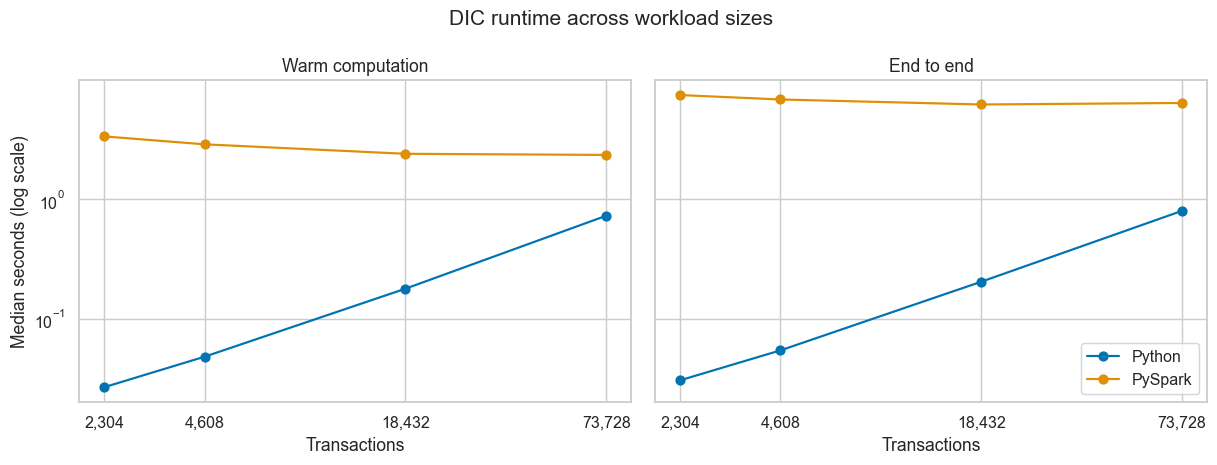

At the original size, **DIC** took 0.0482 s in Python and 2.879 s in Spark for warm computation. End to end it took 0.0545 s and 6.828 s. At 16×, warm times were 0.7281 s and 2.348 s. Warm Spark speedup was 0.0167× at the original size and 0.3101× at the largest size.

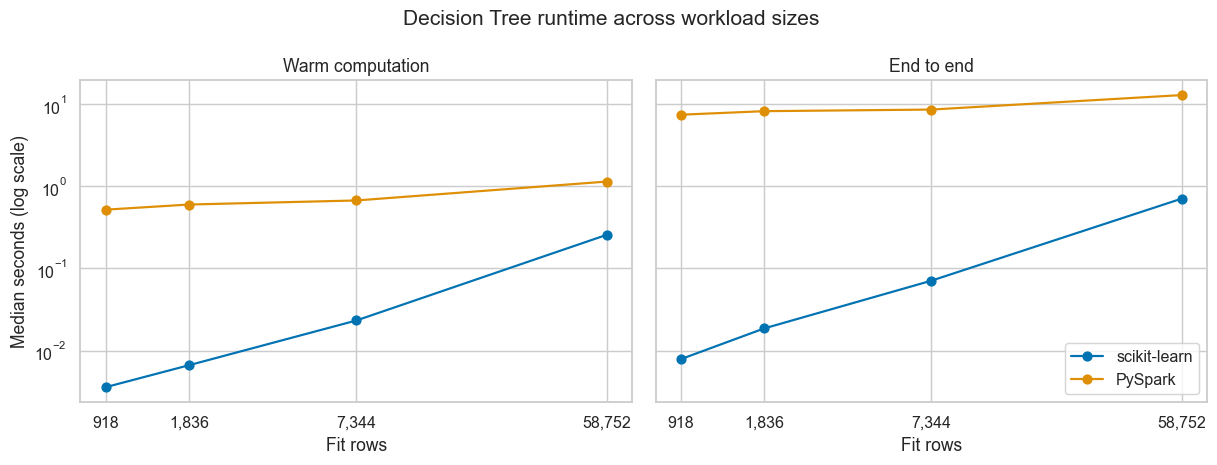

At the original size, **Decision Tree** took 0.0066 s in Python and 0.602 s in Spark for warm computation. End to end it took 0.0186 s and 8.259 s. At 32×, warm times were 0.2578 s and 1.146 s. Warm Spark speedup was 0.0110× at the original size and 0.2249× at the largest size.

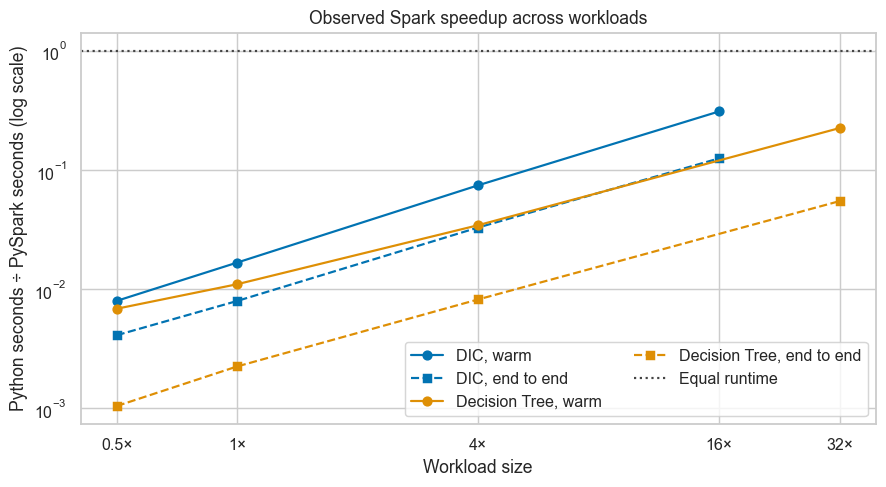

The highest warm speedup ratio was **0.3101×** for DIC on the 16× replicated workload. Spark session creation took 13.17 s and its first action took 4.75 s. As the workloads grow, local computation takes longer and Spark spreads its fixed costs over more rows. Spark still schedules tasks, converts input data and gathers results. A single computer with a shared CPU and memory cannot show how the same workloads would scale across machines.

Spark took longer end to end at every measured size.

In [59]:
run_times = pd.DataFrame(benchmark_runs)
keys = ["algorithm", "workload", "input_factor", "engine", "fit_or_count_rows", "prediction_rows"]
median_times = run_times.groupby(keys, sort=False, as_index=False).agg(
    input_seconds=("input_seconds", "median"), compute_seconds=("compute_seconds", "median"),
    end_to_end_seconds=("end_to_end_seconds", "median"), repetitions=("repetition", "size"),
)
compare_keys = [name for name in keys if name != "engine"]
local_times = median_times.loc[median_times.engine.ne("PySpark")].drop(columns=["engine", "repetitions"])
distributed_times = median_times.loc[median_times.engine.eq("PySpark")].drop(columns="engine")
benchmark = local_times.merge(distributed_times, on=compare_keys, suffixes=("_python", "_spark"), validate="one_to_one")
for measure in ("compute", "end_to_end"):
    benchmark[f"{measure}_speedup"] = benchmark[f"{measure}_seconds_python"] / benchmark[f"{measure}_seconds_spark"]
benchmark["spark_backend"] = benchmark.algorithm.map({"DIC": "Spark SQL", "Decision Tree": "Spark MLlib"})
save_table(run_times, "benchmark_repetitions")
save_table(benchmark, "python_spark_benchmarks")
display(benchmark)

original_sql = benchmark.loc[benchmark.algorithm.eq("DIC") & benchmark.input_factor.eq(1)].iloc[0]
sql_measurement = {
    "backend": "PySpark SQL", "transactions": len(transactions),
    "cached_rows": original_histogram_rows, "checkpoint_actions": dic_scan_stats["checkpoints"],
    "explicit_python_broadcasts": 0, "input_seconds": original_sql.input_seconds_spark,
    "compute_seconds": original_sql.compute_seconds_spark, "end_to_end_seconds": original_sql.end_to_end_seconds_spark,
    "repetitions": REPEATS,
}
backend_comparison = pd.DataFrame([rdd_baseline, sql_measurement])
save_table(backend_comparison, "spark_dic_backend_comparison")
display(backend_comparison)
dic_sql_timing_ratio = rdd_baseline["compute_seconds"] / original_sql.compute_seconds_spark
note(f"On the original data, the RDD replay took **{rdd_baseline['compute_seconds']:.2f} s** for warm counting "
     f"and Spark SQL took **{original_sql.compute_seconds_spark:.2f} s** (median of two runs). "
     f"The RDD warm time was {dic_sql_timing_ratio:.2f} times the SQL warm time. "
     f"Both ran {dic_scan_stats['checkpoints']} checkpoint actions and returned the same results.")

for algorithm, figure_number in [("DIC", 20), ("Decision Tree", 21)]:
    subset = benchmark.loc[benchmark.algorithm.eq(algorithm)].sort_values("input_factor")
    fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), sharey=True)
    for ax, measure, label in zip(axes, ("compute", "end_to_end"), ("Warm computation", "End to end")):
        for backend, color, legend in [("python", BLUE, "Python" if algorithm == "DIC" else "scikit-learn"),
                                       ("spark", ORANGE, "PySpark")]:
            ax.plot(subset.fit_or_count_rows, subset[f"{measure}_seconds_{backend}"], marker="o",
                    label=legend, color=color)
        ax.set(xlabel="Transactions" if algorithm == "DIC" else "Fit rows", title=label, yscale="log")
        ax.set_xscale("log", base=2)
        ax.set_xticks(subset.fit_or_count_rows, [f"{size:,}" for size in subset.fit_or_count_rows])
    axes[0].set_ylabel("Median seconds (log scale)")
    axes[1].legend()
    fig.suptitle(f"{algorithm} runtime across workload sizes")
    save_plot(fig, f"{figure_number:02d}_runtime_{algorithm.lower().replace(' ', '_')}")
    original = subset.loc[subset.input_factor.eq(1)].iloc[0]
    largest = subset.iloc[-1]
    note(f"At the original size, **{algorithm}** took {original.compute_seconds_python:.4f} s in Python and "
         f"{original.compute_seconds_spark:.3f} s in Spark for warm computation. End to end it took "
         f"{original.end_to_end_seconds_python:.4f} s and {original.end_to_end_seconds_spark:.3f} s. "
         f"At {largest.input_factor:g}×, warm times were {largest.compute_seconds_python:.4f} s and "
         f"{largest.compute_seconds_spark:.3f} s. Warm Spark speedup was "
         f"{original.compute_speedup:.4f}× at the original size and {largest.compute_speedup:.4f}× at the largest size.")

fig, ax = plt.subplots(figsize=(8.6, 4.8))
for (algorithm, group), color in zip(benchmark.groupby("algorithm", sort=False), [BLUE, ORANGE]):
    ax.plot(group.input_factor, group.compute_speedup, color=color, marker="o", label=f"{algorithm}, warm")
    ax.plot(group.input_factor, group.end_to_end_speedup, color=color, marker="s", linestyle="--", label=f"{algorithm}, end to end")
ax.axhline(1, color="#444444", linestyle=":", label="Equal runtime")
ax.set(xlabel="Workload size", ylabel="Python seconds ÷ PySpark seconds (log scale)", yscale="log",
       title="Observed Spark speedup across workloads")
ax.set_xscale("log", base=2)
factors = sorted(benchmark.input_factor.unique())
ax.set_xticks(factors, [f"{factor:g}×" for factor in factors])
ax.legend(ncol=2)
save_plot(fig, "22_python_spark_speedup")
maximum_speedup = benchmark.compute_speedup.max()
fastest = benchmark.loc[benchmark.compute_speedup.idxmax()]
note(f"The highest warm speedup ratio was **{maximum_speedup:.4f}×** for {fastest.algorithm} "
     f"on the {fastest.workload.lower()} workload. Spark session creation took {spark_startup:.2f} s "
     f"and its first action took {spark_first_action:.2f} s. "
     "As the workloads grow, local computation takes longer and Spark spreads its fixed costs over more rows. "
     "Spark still schedules tasks, converts input data and gathers results. "
     "A single computer with a shared CPU and memory cannot show how the same workloads would scale across machines.")
if benchmark.end_to_end_speedup.lt(1).all():
    note("Spark took longer end to end at every measured size.")

## 9. Conclusion

In [60]:
strongest_rule = ""
if not outcome_rules.empty:
    rule = outcome_rules.iloc[0]
    strongest_rule = (f" The highest-lift outcome rule was {rule.antecedent} → {rule.consequent}, "
                      f"with {rule.confidence:.1%} confidence.")
note(
    f"- We inspected {len(FILES)} files with **{len(matches):,} match records**, "
    f"then used {len(standard):,} standard decisive matches for the main cohort. "
    f"The most frequent first-innings total band was {modal_bands['First innings'][0]} runs.\n"
    f"- At 20% support and 70% confidence, DIC found **{len(dic_frequent)} frequent itemsets** "
    f"and {len(dic_rules)} rules. Python matched Apriori at all tested supports. Spark matched Python "
    f"on the original database at all tested supports. CHARM found **{len(charm_closed)} closed itemsets** "
    f"at the default threshold. Its pattern compression was {charm_comparison.pattern_reduction_pct.max():.1f}% "
    f"across the tested cutoffs on this transaction database.{strongest_rule}\n"
    f"- The selected {chosen_criterion} tree gave **{selected_metrics.test_accuracy:.1%} accuracy**, "
    f"**{selected_metrics.f1:.3f} F1** and **{selected_metrics.roc_auc:.3f} ROC AUC** on {len(test):,} later matches. "
    f"The majority baseline reached {baseline_metrics.test_accuracy:.1%} accuracy. "
    f"Spark reached {spark_selected.test_accuracy:.1%} with the same criterion and match IDs. "
    "These results apply to the cohort identified after the matches ended.\n"
    f"- AGNES grouped **{len(cluster_scope):,} players** into **{k} groups** with {method} linkage "
    f"and a silhouette of {chosen_cluster.silhouette:.3f}. Group averages ranged from "
    f"{cluster_profiles.runs_per_innings.min():.1f} to {cluster_profiles.runs_per_innings.max():.1f} runs per innings.\n"
    f"- The original RDD DIC warm time was {dic_sql_timing_ratio:.2f} times the new SQL warm time. "
    f"The highest observed warm Spark speedup over Python was {maximum_speedup:.4f}×. These measurements "
    "describe one computer with four or fewer Spark worker threads and the workload sizes above."
)
spark.stop()
print("Notebook complete. Tables, processed data and figures were written.")

- We inspected 6 files with **2,592 match records**, then used 2,305 standard decisive matches for the main cohort. The most frequent first-innings total band was 140–159 runs.
- At 20% support and 70% confidence, DIC found **74 frequent itemsets** and 54 rules. Python matched Apriori at all tested supports. Spark matched Python on the original database at all tested supports. CHARM found **74 closed itemsets** at the default threshold. Its pattern compression was 0.0% across the tested cutoffs on this transaction database. The highest-lift outcome rule was boundary_share=low + pace=low + wickets_lost=many → outcome=lost, with 89.1% confidence.
- The selected entropy tree gave **73.7% accuracy**, **0.732 F1** and **0.816 ROC AUC** on 460 later matches. The majority baseline reached 54.3% accuracy. Spark reached 74.1% with the same criterion and match IDs. These results apply to the cohort identified after the matches ended.
- AGNES grouped **934 players** into **3 groups** with complete linkage and a silhouette of 0.267. Group averages ranged from 11.0 to 19.9 runs per innings.
- The original RDD DIC warm time was 17.26 times the new SQL warm time. The highest observed warm Spark speedup over Python was 0.3101×. These measurements describe one computer with four or fewer Spark worker threads and the workload sizes above.

Notebook complete. Tables, processed data and figures were written.
